# Multi-TPC seven-group nested evaluation


In [1]:
# Configuration
from pathlib import Path
from functools import lru_cache
from scipy.optimize import linear_sum_assignment
from scipy.stats import wilcoxon
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
import hashlib
import json
import math
import os
import pickle
import random
import re
import shutil
import subprocess
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import torch

if globals().get('_FRESH_KERNEL_SENTINEL', False):
    raise RuntimeError('Restart the kernel before running this notebook from the top.')
_FRESH_KERNEL_SENTINEL = True

SEED = 1212
FRAME_HZ = 60.0
TARGET_SR = 16000
EVENT_TOLERANCES = (0.5, 0.7, 1.0)

# Artifact keys from the executed run, mapped to descriptive constants.
METHOD_STAGE1_ONLY = 'R12_cheap_only'
METHOD_AUDIO_ONLY = 'R12_audio_only'
METHOD_PROPOSED_FULL = 'R12_audio_fused'
METHOD_LEE_AUTOMATIC = 'Lee2024_automatic_R12_refit'
METHOD_TRIADIC_VAP = 'TriadicVAP_R12_refit'
METHOD_MUVAP = 'MuVAP_R12_refit'
METHOD_LEE_ANNOTATION_REFERENCE = 'Lee2024_annotation_R12_reference'

PRIMARY_EVENT_TOLERANCE = 1.0
NESTED_PROTOCOL_ID = 'r12-posthoc-fully-nested-logo-v3-report-complete'
REPORTING_REVISION = '2026-09-08-second-audit-complete-v1'
EXPECTED_GROUP_COUNT = 7
STAGE1_MAX_CANDIDATES_PER_MIN = 45.0
AUDIO_MAX_ROWS_PER_OUTER_FOLD = 7000
NEGATIVE_TO_POSITIVE_RATIO = 5
N_BOOTSTRAP = 10000
STAGE1_MODEL_CONFIGS = (
    {'max_leaf_nodes': 15, 'learning_rate': 0.04, 'max_iter': 250, 'l2_regularization': 2.0},
    {'max_leaf_nodes': 31, 'learning_rate': 0.03, 'max_iter': 350, 'l2_regularization': 3.0},
    {'max_leaf_nodes': 47, 'learning_rate': 0.02, 'max_iter': 500, 'l2_regularization': 4.0},
)
STAGE2_REGULARIZATION_GRID = (0.1, 0.3, 1.0)
NMS_GRID_S = (0.3, 0.5, 0.7, 0.9, 1.1, 1.4)
OFFSET_GRID_S = (-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3)
SCORE_QUANTILES = (0.40, 0.50, 0.60, 0.70, 0.78, 0.84, 0.88, 0.92, 0.95, 0.97)
WAVLM_MODEL_ID = 'microsoft/wavlm-large'
WAVLM_CONTEXT_S = 4.0
WAVLM_RECENT_CONTEXT_S = 0.5
WAVLM_PROJECTION_DIM = 48
ECAPA_MODEL_ID = 'speechbrain/spkrec-ecapa-voxceleb'
ECAPA_SEGMENT_S = 1.25
ECAPA_MIN_SEGMENT_S = 0.25
AUDIO_FUSION_WEIGHTS = (0.25, 0.5, 0.75)
AUDIO_STACK_ID = NESTED_PROTOCOL_ID
AUDIO_PRE_GATE_FACTOR = 0.75
AUDIO_GATE_DIAGNOSTIC_TOLERANCES = EVENT_TOLERANCES
AUDIO_NEUTRAL_PROB = 0.5
ALIGNMENT_SEARCH_MAX_S = 2.0
ALIGNMENT_WARN_ABS_S = 0.5
ALIGNMENT_BOUNDARY_MARGIN_S = 0.05
ALIGNMENT_CONTRACT_REV = 'offset-only-exact-60hz-v17.4-absolute-final-r3'
MODALITY_ROW_MISMATCH_MAX_S = 1.0
ANNOTATION_SCHEMA_OVERRIDE = None
PROSODY_COLUMN_OVERRIDE = None
NATIVE_NTT_MIN_GAP_S = 0.2
ITT_RESOLUTION_S = 1.0
ITT_MIN_SUCCESSFUL_FLOOR_S = 0.3
RESEARCH_EVENT_ONTOLOGY_REV = 'unique-event-frame-ambiguous-prev-aware-r1'
AUTO_INSTALL_LIGHT_DEPENDENCIES = False
RESOURCE_PROFILE = 'single_gpu_sequential_r12'
PROPOSED_TEXT_SOURCE = 'strict_online_none'
RUN_LEE24_CONTINUOUS = False
RUN_OFFLINE_ASR_DIAGNOSTIC = False
TRIADIC_VAP_MAX_PHYSICAL_BATCH = 1
STAGE2_TRAIN_BATCH_SIZE = 128
STAGE2_EVAL_BATCH_SIZE = 256
CUDA_MIN_FREE_GB_FOR_MAIN = float(os.environ.get('CUDA_MIN_FREE_GB_FOR_MAIN', '4.0'))
FORCE_MAIN_CPU = bool(int(os.environ.get('FORCE_MAIN_CPU', '0')))
# Optional external seven-group results, for comparison only.
OPTIONAL_HISTORICAL_NESTED_RESULTS_CSV = os.environ.get('HISTORICAL_NESTED_RESULTS_CSV', os.environ.get('R11_NESTED_RESULT_CSV', '')).strip()

_root_env = os.environ.get('MULTITPC_ROOT', '').strip()
_root_candidates = []
if _root_env:
    _root_candidates.append(Path(_root_env).expanduser())
for _base in [Path.cwd(), *Path.cwd().parents]:
    _root_candidates.extend([
        _base / 'data' / 'Multi-TPC',
        _base / 'Multi-TPC',
    ])
MULTITPC_ROOT = next((p.resolve() for p in _root_candidates if p.exists()), None)
if MULTITPC_ROOT is None:
    raise FileNotFoundError(
        "Set MULTITPC_ROOT to the Multi-TPC dataset/project root before running."
    )

RUN_ROOT = MULTITPC_ROOT / 'runs' / 'multitpc_seven_group_nested'
CACHE_ROOT = RUN_ROOT / 'cache'
MODEL_ROOT = RUN_ROOT / 'models'
RESULT_ROOT = RUN_ROOT / 'results'
FIG_ROOT = RUN_ROOT / 'figures'
FOLD_ROOT = RUN_ROOT / 'outer_folds'
AUDIO_FEATURE_CACHE_ROOT = CACHE_ROOT / 'wavlm_ecapa'
DETERMINISTIC_CACHE_ROOT = CACHE_ROOT / 'deterministic_alignment'
for _p in (RUN_ROOT, CACHE_ROOT, MODEL_ROOT, RESULT_ROOT, FIG_ROOT, FOLD_ROOT, AUDIO_FEATURE_CACHE_ROOT, DETERMINISTIC_CACHE_ROOT):
    _p.mkdir(parents=True, exist_ok=True)

HISTORICAL_FINAL_ROOT = MULTITPC_ROOT / 'runs' / 'MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7' / 'comparators_final_v1' / 'final_locked_test'
HISTORICAL_RESULT_PATH = HISTORICAL_FINAL_ROOT / 'results' / 'final_locked_test_result.json'
HISTORICAL_AUDIT_PATH = HISTORICAL_FINAL_ROOT / 'results' / 'final_locked_test_audit.csv'
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
print('Protocol:', NESTED_PROTOCOL_ID)
print('Multi-TPC:', MULTITPC_ROOT)
print('Output:', RUN_ROOT)

def _support_jsonable_config(value):
    if isinstance(value, np.ndarray): return [_support_jsonable_config(x) for x in value.tolist()]
    if isinstance(value, np.generic): return _support_jsonable_config(value.item())
    if isinstance(value,float) and not math.isfinite(value): return None
    if isinstance(value, Path): return str(value)
    if isinstance(value, (list, tuple)): return [_support_jsonable_config(x) for x in value]
    if isinstance(value, dict): return {str(k): _support_jsonable_config(v) for k, v in value.items()}
    return value

WAVLM_MODEL_REVISION='c1423ed94bb01d80a3f5ce5bc39f6026a0f4828c'
DEFAULT_CANDIDATE_THRESHOLD=.30
DEFAULT_CANDIDATE_REFRACTORY_S=.50
ACTIVITY_MODEL_CONFIG=dict(max_leaf_nodes=15,max_iter=120,learning_rate=.05,l2_regularization=2.)
LEE24_EPOCHS=20
TRIADIC_VAP_EPOCHS=10
MUVAP_EPOCHS=5
MUVAP_BATCH_SIZE=1
LEE24_TRAIN_BATCH_SIZE=128
LEE24_EVAL_BATCH_SIZE=128
LEE24_WINDOW_S=.5
DISTIL_DIM=1
TRI_BINS=((0.,.2),(.2,.6))
TRIADIC_VAP_FRAME_HZ=50.
TRIADIC_VAP_CHUNK_S=20.
TRIADIC_VAP_CHUNK_STRIDE_S=20.

IMPLEMENTATION_SHA256='a5d27a8d810e6319a5ab9ca86869a91e2f7dcb9f9d4b4bf5f57a2592b97d57b0'

In [2]:
# Reproducibility, hashing, and resource helpers
from IPython.display import display
import hashlib
import time
import sys,re,json,math,time,random,hashlib,pickle,warnings,subprocess,importlib.util,importlib.metadata,gc,inspect
from functools import lru_cache
from typing import Dict,List,Tuple,Optional,Any
warnings.filterwarnings("default")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from scipy.signal import find_peaks
from scipy.stats import t as student_t
from sklearn.metrics import (
    precision_recall_fscore_support,f1_score,accuracy_score,
    balanced_accuracy_score,confusion_matrix,roc_auc_score,
    average_precision_score,classification_report,matthews_corrcoef
)
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier,RandomForestClassifier,RandomForestRegressor

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader,TensorDataset,Subset

try:
    import soundfile as sf
except Exception as e:
    raise ImportError("soundfile is required. Install with: pip install soundfile") from e

LIGHTGBM_AVAILABLE=importlib.util.find_spec("lightgbm") is not None
TRANSFORMERS_AVAILABLE=importlib.util.find_spec("transformers") is not None
FASTER_WHISPER_AVAILABLE=importlib.util.find_spec("faster_whisper") is not None
XGBOOST_AVAILABLE=importlib.util.find_spec("xgboost") is not None
CATBOOST_AVAILABLE=importlib.util.find_spec("catboost") is not None

if AUTO_INSTALL_LIGHT_DEPENDENCIES:
    missing=[]
    for package,ok in [
        ("lightgbm",LIGHTGBM_AVAILABLE),
        ("transformers",TRANSFORMERS_AVAILABLE),
        ("faster-whisper",FASTER_WHISPER_AVAILABLE),
        ("xgboost",XGBOOST_AVAILABLE),
        ("catboost",CATBOOST_AVAILABLE),
    ]:
        if not ok: missing.append(package)
    if missing:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
        importlib.invalidate_caches()
        LIGHTGBM_AVAILABLE=importlib.util.find_spec("lightgbm") is not None
        TRANSFORMERS_AVAILABLE=importlib.util.find_spec("transformers") is not None
        FASTER_WHISPER_AVAILABLE=importlib.util.find_spec("faster_whisper") is not None
        XGBOOST_AVAILABLE=importlib.util.find_spec("xgboost") is not None
        CATBOOST_AVAILABLE=importlib.util.find_spec("catboost") is not None

if RUN_OFFLINE_ASR_DIAGNOSTIC and not FASTER_WHISPER_AVAILABLE:
    raise ImportError(
        "RUN_OFFLINE_ASR_DIAGNOSTIC=True requires faster-whisper. "
        "Install with `python -m pip install faster-whisper` or set RUN_OFFLINE_ASR_DIAGNOSTIC=False."
    )
if PROPOSED_TEXT_SOURCE not in {"strict_online_none","reference_words"}:
    raise ValueError(
        "Headline PROPOSED_TEXT_SOURCE must be 'strict_online_none' or 'reference_words'. "
        "Whole-recording automatic ASR is intentionally prohibited from the strict-online headline path."
    )
if RUN_LEE24_CONTINUOUS and not TRANSFORMERS_AVAILABLE:
    raise ImportError(
        "transformers is required by the selected Lee2024 branch. "
        "Install with `python -m pip install transformers`."
    )

random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

def stable_seed(tag, base=SEED):
    """Stable per-stage seed independent of Python's randomized hash()."""
    raw=f"{int(base)}::{str(tag)}".encode("utf8")
    return int.from_bytes(hashlib.sha256(raw).digest()[:4],"little") & 0x7fffffff

def set_run_seed(tag, base=SEED):
    """Reset Python/NumPy/PyTorch RNGs for a reproducible training stage."""
    sd=stable_seed(tag,base)
    random.seed(sd);np.random.seed(sd);torch.manual_seed(sd)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(sd)
    return sd

def _support_sha256_json(obj, n=24):
    raw=json.dumps(obj,sort_keys=True,default=str,separators=(",",":")).encode("utf8")
    return hashlib.sha256(raw).hexdigest()[:int(n)]

def _support_file_stat_record(path):
    p=Path(path)
    st=p.stat()
    return dict(path=str(p.resolve()),size=int(st.st_size),mtime_ns=int(st.st_mtime_ns))

SUPPORT_FILE_HASH_INDEX_PATH = CACHE_ROOT / "required_file_sha256_index.json"
try:
    _SUPPORT_FILE_HASH_INDEX = json.loads(SUPPORT_FILE_HASH_INDEX_PATH.read_text()) if SUPPORT_FILE_HASH_INDEX_PATH.exists() else {}
except Exception:
    _SUPPORT_FILE_HASH_INDEX = {}

def _support_sha256_file(path, block_bytes=8*1024*1024):
    p=Path(path)
    h=hashlib.sha256()
    with p.open("rb") as f:
        while True:
            b=f.read(int(block_bytes))
            if not b:break
            h.update(b)
    return h.hexdigest()

def _support_file_identity(path):
    """Content identity with a stat guard so unchanged large audio files are not rehashed every run."""
    p=Path(path).resolve();st=p.stat();key=str(p)
    cached=_SUPPORT_FILE_HASH_INDEX.get(key,{})
    same=(int(cached.get("size",-1))==int(st.st_size) and int(cached.get("mtime_ns",-1))==int(st.st_mtime_ns) and bool(cached.get("sha256")))
    sha=str(cached["sha256"]) if same else _support_sha256_file(p)
    rec=dict(path=key,size=int(st.st_size),mtime_ns=int(st.st_mtime_ns),sha256=sha)
    _SUPPORT_FILE_HASH_INDEX[key]=rec
    return rec

def _support_flush_file_hash_index():
    SUPPORT_FILE_HASH_INDEX_PATH.write_text(json.dumps(_SUPPORT_FILE_HASH_INDEX,indent=2,sort_keys=True))

def _support_table_fingerprint(df, columns):
    q=df.loc[:,list(columns)].copy() if len(df) else pd.DataFrame(columns=list(columns))
    return _support_sha256_json(q.sort_values(list(columns)[:2] if len(columns)>=2 else list(columns)).to_dict("records"))

def _support_package_version(name):
    try:return importlib.metadata.version(name)
    except Exception:return "unknown"

def _cuda_memory_snapshot():
    """Return a fail-safe CUDA memory snapshot in GiB."""
    out={"available":bool(torch.cuda.is_available()),"free_gb":0.0,"total_gb":0.0}
    if not torch.cuda.is_available():
        return out
    try:
        free_b,total_b=torch.cuda.mem_get_info()
        out.update(
            free_gb=float(free_b)/(1024**3),
            total_gb=float(total_b)/(1024**3),
        )
    except Exception as exc:
        out["error"]=repr(exc)
    return out

CUDA_START=_cuda_memory_snapshot()
_cuda_ok=(
    CUDA_START.get("available",False)
    and not FORCE_MAIN_CPU
    and CUDA_START.get("free_gb",0.0)>=float(CUDA_MIN_FREE_GB_FOR_MAIN)
)

DEVICE=torch.device("cuda" if _cuda_ok else "cpu")
AUX_DEVICE=DEVICE
LEGACY_AUX_DEVICE=AUX_DEVICE
LEE24_DEVICE=AUX_DEVICE
TEXT_DEVICE=AUX_DEVICE
TRIADIC_DEVICE=DEVICE

def release_resources(*objs,note=""):
    """Move supplied torch modules to CPU and release this kernel's CUDA cache."""
    for obj in objs:
        try:
            if isinstance(obj,torch.nn.Module):
                obj.to("cpu")
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        try:
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
        except Exception:
            pass
    if note:
        snap=_cuda_memory_snapshot()
        print(f"[resource cleanup] {note}: free CUDA={snap.get('free_gb',0.0):.2f} GiB")

def ensure_min_cuda_free(stage,min_free_gb=None):
    """Diagnostic guard; returns False rather than causing a CUDA OOM."""
    if DEVICE.type!="cuda":
        return False
    need=float(CUDA_MIN_FREE_GB_FOR_MAIN if min_free_gb is None else min_free_gb)
    release_resources(note=f"before {stage}")
    snap=_cuda_memory_snapshot()
    ok=snap.get("free_gb",0.0)>=need
    if not ok:
        print(
            f"WARNING: {stage} requested CUDA but only {snap.get('free_gb',0.0):.2f} GiB "
            f"is free (<{need:.2f} GiB). This usually means another process owns the GPU."
        )
    return ok

try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

print("Resource profile:",RESOURCE_PROFILE)
print("Main device:",DEVICE)
print("Auxiliary comparator/text device (GPU-first, sequential):",AUX_DEVICE)
if torch.cuda.is_available():
    print("GPU:",torch.cuda.get_device_name(0))
    print(
        f"CUDA at start: total={CUDA_START.get('total_gb',0.0):.2f} GiB, "
        f"free={CUDA_START.get('free_gb',0.0):.2f} GiB; "
        f"main-CUDA minimum={CUDA_MIN_FREE_GB_FOR_MAIN:.2f} GiB"
    )
    if DEVICE.type!="cuda":
        print(
            "CUDA is present but not selected for the main pipeline. "
            "Close other GPU kernels/processes and restart this notebook for CUDA speed."
        )

RESOURCE_RUNTIME_STATUS={
    "profile":RESOURCE_PROFILE,
    "cuda_available":bool(torch.cuda.is_available()),
    "cuda_total_gb":float(CUDA_START.get("total_gb",0.0)),
    "cuda_free_gb_at_start":float(CUDA_START.get("free_gb",0.0)),
    "main_device":str(DEVICE),
    "aux_device":str(AUX_DEVICE),
    "legacy_aux_device":str(LEGACY_AUX_DEVICE),
    "lee24_device":str(LEE24_DEVICE),
    "text_device":str(TEXT_DEVICE),
    "v17_system2_train_batch":int(STAGE2_TRAIN_BATCH_SIZE),
    "v17_system2_eval_batch":int(STAGE2_EVAL_BATCH_SIZE),
    "triadic_max_physical_batch":int(TRIADIC_VAP_MAX_PHYSICAL_BATCH),
}
display(pd.DataFrame([RESOURCE_RUNTIME_STATUS]))

print(dict(
    lightgbm=LIGHTGBM_AVAILABLE,
    transformers=TRANSFORMERS_AVAILABLE,
    faster_whisper=FASTER_WHISPER_AVAILABLE,
    xgboost=XGBOOST_AVAILABLE,
    catboost=CATBOOST_AVAILABLE,
))

In [3]:
# Record the frozen held-out evaluation without modifying it
def _sha256_file(path, block=1 << 20):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(block), b''):
            h.update(chunk)
    return h.hexdigest()

if not HISTORICAL_RESULT_PATH.is_file():
    raise FileNotFoundError(f'Completed original held-out result is required: {HISTORICAL_RESULT_PATH}')
HISTORICAL_RESULT = json.loads(HISTORICAL_RESULT_PATH.read_text())
HISTORICAL_TASKA = pd.DataFrame(HISTORICAL_RESULT.get('taskA', []))
HISTORICAL_TASKB = pd.DataFrame(HISTORICAL_RESULT.get('taskB', []))
HISTORICAL_TASKC = pd.DataFrame(HISTORICAL_RESULT.get('taskC', []))
HISTORICAL_NEXT_SPEAKER = pd.DataFrame(HISTORICAL_RESULT.get('next_speaker', []))
if HISTORICAL_TASKC.empty:
    raise RuntimeError('Historical held-out result contains no Task-C records.')
HISTORICAL_TASKA.to_csv(RESULT_ROOT / 'historical_r11_v7_taskA.csv', index=False)
HISTORICAL_TASKB.to_csv(RESULT_ROOT / 'historical_r11_v7_taskB.csv', index=False)
HISTORICAL_TASKC.to_csv(RESULT_ROOT / 'historical_r11_v7_taskC.csv', index=False)
HISTORICAL_NEXT_SPEAKER.to_csv(RESULT_ROOT / 'historical_r11_v7_next_speaker.csv', index=False)
HISTORICAL_EVIDENCE = {
    'status': 'completed_frozen_evaluation_not_reopened',
    'result_path': str(HISTORICAL_RESULT_PATH.resolve()),
    'result_sha256': _sha256_file(HISTORICAL_RESULT_PATH),
    'audit_path': str(HISTORICAL_AUDIT_PATH.resolve()) if HISTORICAL_AUDIT_PATH.is_file() else None,
    'audit_sha256': _sha256_file(HISTORICAL_AUDIT_PATH) if HISTORICAL_AUDIT_PATH.is_file() else None,
    'former_locked_group': '01-28-2022',
    'new_role_of_former_locked_group': 'ordinary_outer_fold_in_posthoc_nested_logo',
    'claim_boundary': 'The seven-group results are post-hoc robustness evidence, not a second untouched confirmatory TEST.',
}
(RESULT_ROOT / 'historical_r11_v7_evidence.json').write_text(json.dumps(HISTORICAL_EVIDENCE, indent=2, sort_keys=True))
print(json.dumps(HISTORICAL_EVIDENCE, indent=2))

{
  "status": "completed_frozen_evaluation_not_reopened",
  "result_path": "<MULTITPC_ROOT>/runs/MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7/comparators_final_v1/final_locked_test/results/final_locked_test_result.json",
  "result_sha256": "4a5f7bd62be3114980154c34b4d949359d701608be94fb58dff7c75904b934da",
  "audit_path": "<MULTITPC_ROOT>/runs/MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7/comparators_final_v1/final_locked_test/results/final_locked_test_audit.csv",
  "audit_sha256": "f2ca5984b14b1f09faa0699e68d21b126c7fe6ac0a6f9338cc099d2158e99c7f",
  "former_locked_group": "01-28-2022",
  "new_role_of_former_locked_group": "ordinary_outer_fold_in_posthoc_nested_logo",
  "claim_boundary": "No R12 result is an untouched confirmatory TEST on 01-28-2022."
}


In [4]:
# Dataset discovery
ANNOT_RE = re.compile(r"(?P<date>\d{2}-\d{2}-\d{4})_Session_(?P<session>\d+)_audio_gaze_gback\.csv$", re.I)

def resolve_dir(*names):
    for n in names:
        p=MULTITPC_ROOT/n
        if p.exists(): return p
    return MULTITPC_ROOT/names[0]

AUDIO_DIR=resolve_dir("Audio","audio")
ANNOT_DIR=resolve_dir("AudioGazeGBack","audiogazegback")
WORD_DIR=resolve_dir("Word","word")
PROSODY_DIR=resolve_dir("Prosody","prosody")
MOCAP_DIR=resolve_dir("Mocap","mocap")
GAZE_DIR=resolve_dir("Gaze","gaze")

def session_id(date,n):
    mm,dd,yyyy=date.split("-")
    return f"mtpc_{yyyy}{mm}{dd}_s{int(n):02d}"

def discover_sessions():
    if not ANNOT_DIR.exists():
        raise FileNotFoundError(f"Missing annotation directory: {ANNOT_DIR}")
    rows=[]
    for ap in sorted(ANNOT_DIR.glob("*_audio_gaze_gback.csv")):
        m=ANNOT_RE.search(ap.name)
        if not m: continue
        date=m.group("date"); sn=int(m.group("session")); sid=session_id(date,sn)
        r=dict(session=sid,date=date,group_id=date,session_number=sn,annotation_path=str(ap),
               prosody_path=str(PROSODY_DIR/f"{date}_Session_{sn}_prosody.csv"))
        for p in (1,2,3):
            r[f"p{p}_audio_path"]=str(AUDIO_DIR/date/f"Session_{sn}_PC_{p}_audio.wav")
            r[f"p{p}_word_path"]=str(WORD_DIR/date/f"Session_{sn}_PC_{p}_words.csv")
            r[f"p{p}_mocap_path"]=str(MOCAP_DIR/date/f"Session_{sn}_PC_{p}_mocap_data.txt")
            g1=GAZE_DIR/date/f"Session_{sn}_PC_{p}_EyeTracker_data_gapfilled.txt"
            g2=GAZE_DIR/date/f"Session_{sn}_PC_{p}_EyeTracker_data.txt"
            r[f"p{p}_gaze_path"]=str(g1 if g1.exists() else g2)
        rows.append(r)
    mf=pd.DataFrame(rows).sort_values(["date","session_number"]).reset_index(drop=True)
    if mf.empty: raise RuntimeError("No Multi-TPC sessions discovered.")
    mf["group_index"]=mf["group_id"].map({g:i for i,g in enumerate(sorted(mf.group_id.unique()))})
    return mf

MANIFEST=discover_sessions()
print("Discovered sessions:",len(MANIFEST),"groups:",MANIFEST.group_id.nunique())
if len(MANIFEST)!=24:
    print(
        "NOTE: the Scientific Data paper reports 24 sessions. "
        f"This local release contains {len(MANIFEST)} complete discovered annotation sessions; "
        "the notebook uses exactly what is present and records the count."
    )
display(MANIFEST[["session","group_id","session_number"]])

DISCOVERY_AUDIT=[]
for r in MANIFEST.itertuples(index=False):
    paths=[r.annotation_path,r.prosody_path]
    paths += [getattr(r,f"p{p}_{k}_path") for p in (1,2,3) for k in ("audio","word","mocap","gaze")]
    missing=[x for x in paths if not Path(x).exists()]
    DISCOVERY_AUDIT.append(dict(session=r.session,n_missing=len(missing),missing=" | ".join(missing)))
DISCOVERY_AUDIT=pd.DataFrame(DISCOVERY_AUDIT)
display(DISCOVERY_AUDIT)
if DISCOVERY_AUDIT.n_missing.gt(0).any():
    bad=DISCOVERY_AUDIT[DISCOVERY_AUDIT.n_missing.gt(0)]
    raise FileNotFoundError(
        "The discovered Multi-TPC release is incomplete for the selected master experiment.\n"
        + bad[["session","missing"]].to_string(index=False)
    )
_SUPPORT_FINGERPRINT_PATHS=[]
for r in MANIFEST.itertuples(index=False):
    _SUPPORT_FINGERPRINT_PATHS.extend([r.annotation_path,r.prosody_path])
    for _p in (1,2,3):
        _SUPPORT_FINGERPRINT_PATHS.extend([getattr(r,f"p{_p}_audio_path"),getattr(r,f"p{_p}_word_path"),getattr(r,f"p{_p}_mocap_path"),getattr(r,f"p{_p}_gaze_path")])
SUPPORT_REQUIRED_FILE_IDENTITIES=[_support_file_identity(p) for p in sorted(set(_SUPPORT_FINGERPRINT_PATHS))]
_support_flush_file_hash_index()
MULTITPC_DATA_FINGERPRINT=_support_sha256_json(SUPPORT_REQUIRED_FILE_IDENTITIES)
print("Multi-TPC content fingerprint:",MULTITPC_DATA_FINGERPRINT,"files:",len(SUPPORT_REQUIRED_FILE_IDENTITIES))

Discovered sessions: 23 groups: 7
NOTE: the Scientific Data paper reports 24 sessions. This local release contains 23 complete discovered annotation sessions; the notebook uses exactly what is present and records the count.


,session,group_id,session_number
0,mtpc_20220128_s01,01-28-2022,1
1,mtpc_20220128_s02,01-28-2022,2
2,mtpc_20220128_s03,01-28-2022,3
3,mtpc_20220128_s04,01-28-2022,4
4,mtpc_20220128_s05,01-28-2022,5
5,mtpc_20220128_s06,01-28-2022,6
6,mtpc_20220211_s02,02-11-2022,2
7,mtpc_20220211_s03,02-11-2022,3
8,mtpc_20220304_s01,03-04-2022,1
9,mtpc_20220304_s02,03-04-2022,2


,session,n_missing,missing
0,mtpc_20220128_s01,0,
1,mtpc_20220128_s02,0,
2,mtpc_20220128_s03,0,
3,mtpc_20220128_s04,0,
4,mtpc_20220128_s05,0,
5,mtpc_20220128_s06,0,
6,mtpc_20220211_s02,0,
7,mtpc_20220211_s03,0,
8,mtpc_20220304_s01,0,
9,mtpc_20220304_s02,0,


Multi-TPC content fingerprint: bafe12cb3b50f703626cd357 files: 322


In [5]:
# Annotation loader
SESSION_ROW={r.session:r._asdict() for r in MANIFEST.itertuples(index=False)}

def _normcol(c):
    return re.sub(r"[^a-z0-9]+","",str(c).lower())

def _participant_col(cols,p,kind):
    """Resolve one official participant column without depending on file column order."""
    pn=f"p{int(p)}"
    candidates=[]
    for c in cols:
        n=_normcol(c)
        if pn not in n:
            continue
        if kind=="audio" and "audio" in n:
            candidates.append(c)
        elif kind=="gaze" and "gaze" in n:
            candidates.append(c)
        elif kind=="headshake" and ("headshak" in n or "shaking" in n):
            candidates.append(c)
        elif kind=="nodding" and ("nodd" in n):
            candidates.append(c)
    return candidates[0] if len(candidates)==1 else None

@lru_cache(maxsize=64)
def load_annotation(session):
    """Load the audited native 60-Hz annotation using named columns only.

    The executed V16 audit confirmed the local release names:
      P1/P2/P3 audio, P1/P2/P3 Gaze,
      p1/p2/p3_headshaking and p1/p2/p3_nodding.
    A future release with renamed columns must be mapped explicitly through
    ANNOTATION_SCHEMA_OVERRIDE; silent positional guessing is prohibited.
    """
    row=SESSION_ROW[str(session)]
    df=pd.read_csv(row["annotation_path"])
    cols=list(df.columns)

    if ANNOTATION_SCHEMA_OVERRIDE is not None:
        sch=dict(ANNOTATION_SCHEMA_OVERRIDE)
        audio=list(sch.get("audio",[]));gaze=list(sch.get("gaze",[]));head=list(sch.get("head",[]))
    else:
        audio=[_participant_col(cols,p,"audio") for p in (1,2,3)]
        gaze=[_participant_col(cols,p,"gaze") for p in (1,2,3)]
        head=[]
        for p in (1,2,3):
            head.extend([_participant_col(cols,p,"headshake"),_participant_col(cols,p,"nodding")])

    missing=[x for x in audio+gaze+head if x is None or x not in cols]
    if missing:
        raise RuntimeError(
            f"{session}: could not resolve the audited named annotation schema. "
            f"Observed columns={cols}. Set ANNOTATION_SCHEMA_OVERRIDE explicitly if this is a renamed release."
        )
    if len(audio)!=3 or len(gaze)!=3 or len(head)!=6 or len(set(audio+gaze+head))!=12:
        raise RuntimeError(f"{session}: invalid annotation schema mapping: audio={audio}, gaze={gaze}, head={head}")

    out={
        "df":df,
        "audio":df[audio].apply(pd.to_numeric,errors="coerce").fillna(0).to_numpy(np.int16),
        "gaze":df[gaze].apply(pd.to_numeric,errors="coerce").fillna(0).to_numpy(np.int16),
        "head":df[head].apply(pd.to_numeric,errors="coerce").fillna(0).to_numpy(np.float32),
        "audio_cols":list(audio),"gaze_cols":list(gaze),"head_cols":list(head),
    }
    if out["audio"].shape[1]!=3 or out["gaze"].shape[1]!=3 or out["head"].shape[1]!=6:
        raise RuntimeError(f"{session}: annotation tensor dimensions violate the 3/3/6 contract")
    if not set(np.unique(out["audio"]).tolist()).issubset({0,1,2}):
        raise RuntimeError(f"{session}: unexpected native activity state outside {{0,1,2}}")
    if not set(np.unique(out["gaze"]).tolist()).issubset({0,1,2}):
        raise RuntimeError(f"{session}: unexpected native gaze code outside {{0,1,2}}")
    return out

AUDIT_ROWS=[]
for s in MANIFEST.session:
    a=load_annotation(s)
    states=set(np.unique(a["audio"]).tolist())
    gazes=set(np.unique(a["gaze"]).tolist())
    AUDIT_ROWS.append(dict(
        session=s,
        n_frames=len(a["audio"]),
        duration_s=len(a["audio"])/FRAME_HZ,
        audio_states=sorted(states),
        gaze_states=sorted(gazes),
        audio_cols=" | ".join(map(str,a["audio_cols"])),
        gaze_cols=" | ".join(map(str,a["gaze_cols"])),
        head_cols=" | ".join(map(str,a["head_cols"])),
    ))

ANNOT_AUDIT=pd.DataFrame(AUDIT_ROWS)
display(ANNOT_AUDIT)
assert all(set(x).issubset({0,1,2}) for x in ANNOT_AUDIT.audio_states), "Unexpected native audio-state code."
assert all(set(x).issubset({0,1,2}) for x in ANNOT_AUDIT.gaze_states), "Unexpected native gaze code."

,session,n_frames,duration_s,audio_states,gaze_states,audio_cols,gaze_cols,head_cols
0,mtpc_20220128_s01,19377,322.950000,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
1,mtpc_20220128_s02,33463,557.716667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
2,mtpc_20220128_s03,21566,359.433333,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
3,mtpc_20220128_s04,36625,610.416667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
4,mtpc_20220128_s05,25730,428.833333,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
5,mtpc_20220128_s06,19681,328.016667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
6,mtpc_20220211_s02,43968,732.800000,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
7,mtpc_20220211_s03,68872,1147.866667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
8,mtpc_20220304_s01,47308,788.466667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
9,mtpc_20220304_s02,49953,832.550000,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...


In [6]:
# Audio alignment and acoustic cache
def resample_linear(x, orig_sr, target_sr):
    x = np.asarray(x, np.float32)

    if int(orig_sr) == int(target_sr):
        return x

    if len(x) == 0:
        return np.zeros(0, dtype=np.float32)

    n = max(
        1,
        int(
            round(
                len(x)
                * float(target_sr)
                / float(orig_sr)
            )
        ),
    )

    old = np.linspace(
        0.0,
        1.0,
        len(x),
        endpoint=False,
    )

    new = np.linspace(
        0.0,
        1.0,
        n,
        endpoint=False,
    )

    return np.interp(
        new,
        old,
        x.astype(float),
    ).astype(np.float32)

@lru_cache(maxsize=16)
def read_participant_audio(session, p):
    session = str(session)
    p = int(p)

    if session not in SESSION_ROW:
        raise KeyError(
            f"Session {session!r} is not present in SESSION_ROW."
        )

    key = f"p{p}_audio_path"

    if key not in SESSION_ROW[session]:
        raise KeyError(
            f"{key!r} is missing for session {session!r}."
        )

    path = Path(
        SESSION_ROW[session][key]
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Participant audio not found: {path}"
        )

    x, sr = sf.read(
        str(path),
        dtype="float32",
        always_2d=False,
    )

    x = np.asarray(x)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = np.nan_to_num(
        x,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    ).astype(np.float32)

    if int(sr) != int(TARGET_SR):
        x = resample_linear(
            x,
            int(sr),
            int(TARGET_SR),
        )
        sr = int(TARGET_SR)

    return x, int(sr)

def _audio_frame_rms(x, sr, hz=60.0):
    """RMS on an exact `hz` clock using sample-index boundaries round(k*sr/hz).

    At 16 kHz / 60 Hz the bins necessarily alternate between 266 and 267 samples.
    Using one fixed 267-sample block would create an artificial ~59.925-Hz clock and
    cumulative drift, so fixed-length reshape is explicitly prohibited here.
    """
    x=np.asarray(x,np.float32)
    sr=float(sr);hz=float(hz)
    if len(x)==0:return np.zeros(0,dtype=np.float32)
    if not (sr>0 and hz>0):raise ValueError(f"Invalid sr/hz: sr={sr}, hz={hz}")
    n_frames=int(np.floor(len(x)*hz/sr + 1e-12))
    if n_frames<=0:return np.zeros(0,dtype=np.float32)
    edges=np.rint(np.arange(n_frames+1,dtype=np.float64)*sr/hz).astype(np.int64)
    edges=np.clip(edges,0,len(x))
    if np.any(np.diff(edges)<=0):raise RuntimeError("Exact audio-frame boundaries are not strictly increasing")
    sq=np.asarray(x,dtype=np.float64)**2
    cs=np.concatenate(([0.0],np.cumsum(sq,dtype=np.float64)))
    sums=cs[edges[1:]]-cs[edges[:-1]]
    counts=(edges[1:]-edges[:-1]).astype(np.float64)
    return np.sqrt(sums/counts + 1e-10).astype(np.float32)

AUDIO_OFFSET_PATH = (
    DETERMINISTIC_CACHE_ROOT
    / f"audio_offset_{ALIGNMENT_CONTRACT_REV}_{MULTITPC_DATA_FINGERPRINT}.csv"
)

AUDIO_OFFSET_COLUMNS = [
    "session",
    "participant",
    "lag_frames",
    "offset_s",
    "corr",
    "boundary_solution",
    "warning",
]

if AUDIO_OFFSET_PATH.exists():

    AUDIO_OFFSETS = pd.read_csv(
        AUDIO_OFFSET_PATH
    )

    for col in AUDIO_OFFSET_COLUMNS:
        if col not in AUDIO_OFFSETS.columns:
            if col in (
                "lag_frames",
                "offset_s",
                "corr",
            ):
                AUDIO_OFFSETS[col] = np.nan

            elif col in (
                "boundary_solution",
                "warning",
            ):
                AUDIO_OFFSETS[col] = False

            else:
                AUDIO_OFFSETS[col] = ""

    AUDIO_OFFSETS["session"] = (
        AUDIO_OFFSETS["session"]
        .astype(str)
    )

    AUDIO_OFFSETS["participant"] = pd.to_numeric(
        AUDIO_OFFSETS["participant"],
        errors="coerce",
    )

    AUDIO_OFFSETS["lag_frames"] = pd.to_numeric(
        AUDIO_OFFSETS["lag_frames"],
        errors="coerce",
    )

    AUDIO_OFFSETS["offset_s"] = pd.to_numeric(
        AUDIO_OFFSETS["offset_s"],
        errors="coerce",
    )

    AUDIO_OFFSETS["corr"] = pd.to_numeric(
        AUDIO_OFFSETS["corr"],
        errors="coerce",
    )

    AUDIO_OFFSETS = (
        AUDIO_OFFSETS[
            AUDIO_OFFSET_COLUMNS
        ]
        .dropna(
            subset=[
                "participant",
                "offset_s",
                "corr",
            ]
        )
        .copy()
    )

    AUDIO_OFFSETS["participant"] = (
        AUDIO_OFFSETS["participant"]
        .astype(int)
    )

else:

    AUDIO_OFFSETS = pd.DataFrame(
        columns=AUDIO_OFFSET_COLUMNS
    )

def estimate_audio_offset(
    session,
    p,
    max_abs_s=ALIGNMENT_SEARCH_MAX_S,
):
    global AUDIO_OFFSETS

    session = str(session)
    p = int(p)

    hit = AUDIO_OFFSETS[
        (
            AUDIO_OFFSETS[
                "session"
            ].astype(str)
            == session
        )
        &
        (
            AUDIO_OFFSETS[
                "participant"
            ].astype(int)
            == p
        )
    ]

    if len(hit):

        row = hit.iloc[0]

        offset_s = float(
            row["offset_s"]
        )

        corr = float(
            row["corr"]
        )

        if np.isfinite(offset_s) and np.isfinite(corr):
            return offset_s, corr

        print(
            f"WARNING: invalid cached audio offset for "
            f"{session} P{p}; recomputing."
        )

    x, sr = read_participant_audio(
        session,
        p,
    )

    env = _audio_frame_rms(
        x,
        sr,
        FRAME_HZ,
    )

    ann = load_annotation(
        session
    )

    target = (
        ann["audio"][:, p - 1]
        > 0
    ).astype(np.float32)

    if len(env) == 0 or len(target) == 0:
        print(
            f"WARNING: empty audio/alignment signal for "
            f"{session} P{p}; using zero offset."
        )
        return 0.0, 0.0

    pos = env[env > 0]

    scale = (
        float(np.median(pos))
        if len(pos)
        else 1.0
    )

    env = np.log1p(
        env / max(1e-8, scale)
    )

    env = (
        env - env.mean()
    ) / (
        env.std() + 1e-8
    )

    target = (
        target - target.mean()
    ) / (
        target.std() + 1e-8
    )

    maxlag = int(
        round(
            float(max_abs_s)
            * float(FRAME_HZ)
        )
    )

    best_lag = 0
    best_corr = -np.inf

    for lag in range(
        -maxlag,
        maxlag + 1,
        2,
    ):

        i0 = max(
            0,
            -lag,
        )

        i1 = min(
            len(target),
            len(env) - lag,
        )

        if i1 - i0 < 300:
            continue

        c = float(
            np.mean(
                target[i0:i1]
                * env[
                    i0 + lag:
                    i1 + lag
                ]
            )
        )

        if np.isfinite(c) and c > best_corr:
            best_lag = int(lag)
            best_corr = float(c)

    coarse = int(best_lag)

    for lag in range(
        max(
            -maxlag,
            coarse - 4,
        ),
        min(
            maxlag,
            coarse + 4,
        )
        + 1,
    ):

        i0 = max(
            0,
            -lag,
        )

        i1 = min(
            len(target),
            len(env) - lag,
        )

        if i1 - i0 < 300:
            continue

        c = float(
            np.mean(
                target[i0:i1]
                * env[
                    i0 + lag:
                    i1 + lag
                ]
            )
        )

        if np.isfinite(c) and c > best_corr:
            best_lag = int(lag)
            best_corr = float(c)

    if not np.isfinite(best_corr):
        print(
            f"WARNING: no valid offset correlation for "
            f"{session} P{p}; using zero offset."
        )

        best_lag = 0
        best_corr = 0.0

    lag = int(best_lag)
    corr = float(best_corr)

    offset_s = float(
        lag / float(FRAME_HZ)
    )

    boundary = bool(
        abs(
            abs(offset_s)
            - float(max_abs_s)
        )
        <= float(
            ALIGNMENT_BOUNDARY_MARGIN_S
        )
    )

    warning = bool(
        abs(offset_s)
        > float(
            ALIGNMENT_WARN_ABS_S
        )
        or boundary
    )

    row = {
        "session": session,
        "participant": p,
        "lag_frames": lag,
        "offset_s": offset_s,
        "corr": corr,
        "boundary_solution": boundary,
        "warning": warning,
    }

    AUDIO_OFFSETS = AUDIO_OFFSETS[
        ~(
            (
                AUDIO_OFFSETS[
                    "session"
                ].astype(str)
                == session
            )
            &
            (
                AUDIO_OFFSETS[
                    "participant"
                ].astype(int)
                == p
            )
        )
    ].copy()

    AUDIO_OFFSETS = pd.concat(
        [
            AUDIO_OFFSETS,
            pd.DataFrame([row]),
        ],
        ignore_index=True,
    )

    AUDIO_OFFSETS = (
        AUDIO_OFFSETS[
            AUDIO_OFFSET_COLUMNS
        ]
        .sort_values(
            [
                "session",
                "participant",
            ]
        )
        .reset_index(drop=True)
    )

    AUDIO_OFFSETS.to_csv(
        AUDIO_OFFSET_PATH,
        index=False,
    )

    return offset_s, corr

def annotation_time_to_raw_audio(
    session,
    p,
    t,
):
    offset_s, _ = estimate_audio_offset(
        session,
        p,
    )

    return (
        float(t)
        + float(offset_s)
    )

audio_audit = []

for s in MANIFEST["session"].astype(str):

    for p in (1, 2, 3):

        audio_path = Path(
            SESSION_ROW[s][
                f"p{p}_audio_path"
            ]
        )

        if not audio_path.exists():
            continue

        off, corr = estimate_audio_offset(
            s,
            p,
        )

        warning = bool(
            abs(off)
            > float(
                ALIGNMENT_WARN_ABS_S
            )
            or abs(
                abs(off)
                - float(
                    ALIGNMENT_SEARCH_MAX_S
                )
            )
            <= float(
                ALIGNMENT_BOUNDARY_MARGIN_S
            )
        )

        audio_audit.append(
            {
                "session": s,
                "participant": p,
                "offset_s": float(off),
                "corr": float(corr),
                "warning": warning,
            }
        )

AUDIO_ALIGNMENT_AUDIT = pd.DataFrame(
    audio_audit
)
AUDIO_ALIGNMENT_FINGERPRINT=_support_table_fingerprint(AUDIO_ALIGNMENT_AUDIT,["session","participant","offset_s","corr","warning"])
print("Audio-alignment fingerprint:",AUDIO_ALIGNMENT_FINGERPRINT)

display(
    AUDIO_ALIGNMENT_AUDIT
)

if (
    len(AUDIO_ALIGNMENT_AUDIT)
    and AUDIO_ALIGNMENT_AUDIT[
        "warning"
    ].any()
):

    print(
        "WARNING: some audio offsets are outside the "
        "expected small-offset regime. "
        "No affine scaling is ever applied."
    )

ACOUSTIC_CACHE_DIR = (
    DETERMINISTIC_CACHE_ROOT
    / f"cheap_audio_10hz_{AUDIO_ALIGNMENT_FINGERPRINT}"
)

ACOUSTIC_CACHE_DIR.mkdir(
    exist_ok=True,
    parents=True,
)

def build_cheap_audio_cache(
    session,
):
    session = str(session)

    path = (
        ACOUSTIC_CACHE_DIR
        / f"{session}.npz"
    )

    if path.exists():
        try:
            _old=np.load(path,allow_pickle=False)
            _ok=(
                "data_fingerprint" in _old.files and str(_old["data_fingerprint"].item())==str(MULTITPC_DATA_FINGERPRINT)
                and "audio_alignment_fingerprint" in _old.files and str(_old["audio_alignment_fingerprint"].item())==str(AUDIO_ALIGNMENT_FINGERPRINT)
                and "alignment_contract_rev" in _old.files and str(_old["alignment_contract_rev"].item())==str(ALIGNMENT_CONTRACT_REV)
            )
            _old.close()
            if _ok:return path
        except Exception:pass
        path.unlink(missing_ok=True)

    ann = load_annotation(
        session
    )

    dur = (
        len(ann["audio"])
        / float(FRAME_HZ)
    )

    times = np.arange(
        0.05,
        dur,
        0.10,
        dtype=np.float32,
    )

    feats = np.zeros(
        (
            len(times),
            3,
            3,
        ),
        dtype=np.float32,
    )

    for pi, p in enumerate(
        (1, 2, 3)
    ):

        x, sr = read_participant_audio(
            session,
            p,
        )

        off, _ = estimate_audio_offset(
            session,
            p,
        )

        for i, t in enumerate(times):

            raw_t = (
                float(t)
                + float(off)
            )

            hi = int(
                round(
                    raw_t
                    * float(sr)
                )
            )

            lo = int(
                round(
                    (
                        raw_t
                        - 0.10
                    )
                    * float(sr)
                )
            )

            lo = max(
                0,
                lo,
            )

            hi = min(
                len(x),
                hi,
            )

            if hi <= lo:
                continue

            seg = x[lo:hi]

            if len(seg) == 0:
                continue

            feats[
                i,
                pi,
                0,
            ] = np.sqrt(
                np.mean(
                    seg * seg
                )
                + 1e-10
            )

            if len(seg) > 1:
                feats[
                    i,
                    pi,
                    1,
                ] = np.mean(
                    np.abs(
                        np.diff(seg)
                    )
                )

            feats[
                i,
                pi,
                2,
            ] = np.max(
                np.abs(seg)
            )

    np.savez_compressed(
        path,
        times=times,
        features=feats,
        alignment_method=np.asarray(
            "verified_offset_only"
        ),
        scale=np.float32(1.0),
        frame_hz=np.float32(10.0),
        data_fingerprint=np.asarray(MULTITPC_DATA_FINGERPRINT),
        audio_alignment_fingerprint=np.asarray(AUDIO_ALIGNMENT_FINGERPRINT),
        alignment_contract_rev=np.asarray(ALIGNMENT_CONTRACT_REV),
    )

    return path

built = 0
skipped = 0

for s in MANIFEST[
    "session"
].astype(str):

    have_all_audio = all(
        Path(
            SESSION_ROW[s][
                f"p{p}_audio_path"
            ]
        ).exists()
        for p in (1, 2, 3)
    )

    if not have_all_audio:
        skipped += 1
        print(
            f"WARNING: skipping cheap audio cache for {s}: "
            f"one or more participant WAV files are missing."
        )
        continue

    build_cheap_audio_cache(
        s
    )

    built += 1

print(
    f"Cheap acoustic caches ready: "
    f"{built} sessions built/reused, "
    f"{skipped} skipped."
)

Audio-alignment fingerprint: 4d70e1fe040bb42987946b87


,session,participant,offset_s,corr,warning
0,mtpc_20220128_s01,1,0.150000,0.412716,False
1,mtpc_20220128_s01,2,0.150000,0.418396,False
2,mtpc_20220128_s01,3,0.150000,0.444368,False
3,mtpc_20220128_s02,1,0.150000,0.456755,False
4,mtpc_20220128_s02,2,0.183333,0.294372,False
...,...,...,...,...,...
64,mtpc_20211215_s03,2,0.150000,0.590542,False
65,mtpc_20211215_s03,3,0.133333,0.583576,False
66,mtpc_20211215_s04,1,0.150000,0.398898,False
67,mtpc_20211215_s04,2,0.166667,0.554771,False


Cheap acoustic caches ready: 23 sessions built/reused, 0 skipped.


In [7]:
# Prosody and motion loaders
MODALITY_ALIGNMENT_AUDIT=[]

def _safe_row_align_numeric(num,n_native,session,modality,participant=None):
    num=np.asarray(num,np.float32)
    if num.ndim==1:num=num[:,None]
    mismatch_frames=int(len(num)-int(n_native))
    mismatch_s=float(mismatch_frames/FRAME_HZ)
    safe=abs(mismatch_s)<=MODALITY_ROW_MISMATCH_MAX_S
    inactive_tail_exception=False
    if (not safe) and len(num)<int(n_native):
        ann_audio=load_annotation(str(session))["audio"]
        tail=ann_audio[len(num):int(n_native)]
        inactive_tail_exception=bool(len(tail) and np.all(tail==0))
        safe=inactive_tail_exception
    out=np.full((int(n_native),num.shape[1]),np.nan,np.float32)
    valid=np.zeros(int(n_native),bool)
    if safe:
        m=min(int(n_native),len(num))
        if m>0:
            out[:m]=num[:m]
            valid[:m]=np.isfinite(out[:m]).any(axis=1)
        action="safe_shorter_inactive_native_tail" if inactive_tail_exception else "row_aligned_with_small_tail_pad_or_trim"
    else:
        action="invalidated_large_length_mismatch"
    MODALITY_ALIGNMENT_AUDIT.append(dict(
        session=str(session),modality=str(modality),participant=participant,
        native_frames=int(n_native),source_frames=int(len(num)),
        mismatch_frames=mismatch_frames,mismatch_s=mismatch_s,safe=bool(safe),action=action
    ))
    return out,valid

PROSODY_COLUMN_AUDIT=[]

def _norm_colname(x):
    return re.sub(r"[^a-z0-9]+","_",str(x).strip().lower()).strip("_")

@lru_cache(maxsize=64)
def load_prosody(session):
    path=Path(SESSION_ROW[str(session)]["prosody_path"]);n=len(load_annotation(session)["audio"])
    if not path.exists():
        MODALITY_ALIGNMENT_AUDIT.append(dict(session=str(session),modality="prosody",participant=None,native_frames=n,source_frames=0,
                                             mismatch_frames=-n,mismatch_s=-n/FRAME_HZ,safe=False,action="missing"))
        PROSODY_COLUMN_AUDIT.append(dict(session=str(session),mode="missing",columns=[]))
        return np.full((n,6),np.nan,np.float32),np.zeros(n,bool)

    df=pd.read_csv(path)
    normalized={_norm_colname(c):c for c in df.columns}
    wanted=["p1_pitch","p1_intensity","p2_pitch","p2_intensity","p3_pitch","p3_intensity"]
    if PROSODY_COLUMN_OVERRIDE is not None:
        selected=list(PROSODY_COLUMN_OVERRIDE)
        if len(selected)!=6 or any(c not in df.columns for c in selected):
            raise RuntimeError(f"{session}: invalid PROSODY_COLUMN_OVERRIDE={selected}; observed={list(df.columns)}")
        mode="explicit_override"
    elif all(k in normalized for k in wanted):
        selected=[normalized[k] for k in wanted];mode="named_pitch_intensity"
    else:
        raise RuntimeError(
            f"{session}: canonical p1/p2/p3 pitch+intensity columns were not found. "
            f"Observed columns={list(df.columns)}. Set PROSODY_COLUMN_OVERRIDE explicitly for a renamed release."
        )
    num=df[selected].apply(pd.to_numeric,errors="coerce").to_numpy(np.float32)
    PROSODY_COLUMN_AUDIT.append(dict(session=str(session),mode=mode,columns=[str(x) for x in selected]))
    return _safe_row_align_numeric(num,n,session,"prosody",None)

@lru_cache(maxsize=128)
def load_mocap(session,p):
    path=Path(SESSION_ROW[str(session)][f"p{int(p)}_mocap_path"]);n=len(load_annotation(session)["audio"])
    if not path.exists():
        MODALITY_ALIGNMENT_AUDIT.append(dict(session=str(session),modality="mocap",participant=int(p),native_frames=n,source_frames=0,
                                             mismatch_frames=-n,mismatch_s=-n/FRAME_HZ,safe=False,action="missing"))
        return np.full((n,0),np.nan,np.float32),np.zeros(n,bool)
    try:df=pd.read_csv(path,sep=None,engine="python",header=None)
    except Exception:df=pd.read_csv(path,sep=r"\s+",header=None)
    num=df.apply(pd.to_numeric,errors="coerce").to_numpy(np.float32)
    return _safe_row_align_numeric(num,n,session,"mocap",int(p))

VALIDITY=[]
for s in MANIFEST.session:
    n=len(load_annotation(s)["audio"])
    pr,pv=load_prosody(s);mvals=[]
    for p in (1,2,3):
        m,mv=load_mocap(s,p);mvals.append(float(mv.mean()) if len(mv) else 0.0)
    VALIDITY.append(dict(session=s,native_frames=n,prosody_valid=float(pv.mean()) if len(pv) else 0.0,mocap_valid_mean=float(np.mean(mvals))))
VALIDITY_DF=pd.DataFrame(VALIDITY)
MODALITY_ALIGNMENT_AUDIT_DF=pd.DataFrame(MODALITY_ALIGNMENT_AUDIT).drop_duplicates(
    ["session","modality","participant"],keep="last"
).reset_index(drop=True)
PROSODY_COLUMN_AUDIT_DF=pd.DataFrame(PROSODY_COLUMN_AUDIT).drop_duplicates("session",keep="last").reset_index(drop=True)
display(VALIDITY_DF)
display(MODALITY_ALIGNMENT_AUDIT_DF.sort_values(["safe","session","modality"]))
display(PROSODY_COLUMN_AUDIT_DF)

,session,native_frames,prosody_valid,mocap_valid_mean
0,mtpc_20220128_s01,19377,0.998607,1.0
1,mtpc_20220128_s02,33463,0.999253,1.0
2,mtpc_20220128_s03,21566,0.656589,1.0
3,mtpc_20220128_s04,36625,0.999317,1.0
4,mtpc_20220128_s05,25730,0.834823,1.0
5,mtpc_20220128_s06,19681,0.998730,1.0
6,mtpc_20220211_s02,43968,0.999454,0.0
7,mtpc_20220211_s03,68872,0.999593,1.0
8,mtpc_20220304_s01,47308,0.999408,1.0
9,mtpc_20220304_s02,49953,0.999459,1.0


,session,modality,participant,native_frames,source_frames,mismatch_frames,mismatch_s,safe,action
25,mtpc_20220211_s02,mocap,1.0,43968,55534,11566,192.766667,False,invalidated_large_length_mismatch
26,mtpc_20220211_s02,mocap,2.0,43968,55534,11566,192.766667,False,invalidated_large_length_mismatch
27,mtpc_20220211_s02,mocap,3.0,43968,55534,11566,192.766667,False,invalidated_large_length_mismatch
77,mtpc_20211215_s01,mocap,1.0,36298,36298,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
78,mtpc_20211215_s01,mocap,2.0,36298,36298,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
...,...,...,...,...,...,...,...,...,...
68,mtpc_20220312_s02,prosody,NaN,52719,52692,-27,-0.450000,True,row_aligned_with_small_tail_pad_or_trim
73,mtpc_20220312_s03,mocap,1.0,60370,60370,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
74,mtpc_20220312_s03,mocap,2.0,60370,60370,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
75,mtpc_20220312_s03,mocap,3.0,60370,60370,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim


,session,mode,columns
0,mtpc_20220128_s01,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
1,mtpc_20220128_s02,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
2,mtpc_20220128_s03,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
3,mtpc_20220128_s04,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
4,mtpc_20220128_s05,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
5,mtpc_20220128_s06,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
6,mtpc_20220211_s02,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
7,mtpc_20220211_s03,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
8,mtpc_20220304_s01,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
9,mtpc_20220304_s02,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."


In [8]:
# Native state mappings
LEFT_RIGHT_TO_RECIPIENT = {1: {1: 2, 2: 3}, 2: {1: 3, 2: 1}, 3: {1: 1, 2: 2}}

def paper_isv(native):
    x = np.asarray(native, np.int16)
    y = np.zeros_like(x)
    y[x == 1] = 2
    y[x == 2] = 1
    return y

def paper_gtv(relative):
    x = np.asarray(relative, np.int16)
    y = np.zeros_like(x)
    for pi, p in enumerate((1, 2, 3)):
        y[:, pi] = np.where(x[:, pi] == 0, 0, np.where(x[:, pi] == 1, LEFT_RIGHT_TO_RECIPIENT[p][1], LEFT_RIGHT_TO_RECIPIENT[p][2]))
    return y

In [9]:
# Post-hoc event definitions for all seven outer groups
def runs(mask):
    x=np.asarray(mask,bool)
    d=np.diff(np.r_[False,x,False].astype(np.int8))
    return list(zip(np.where(d==1)[0],np.where(d==-1)[0]))

def _primary_segments(session):
    a=load_annotation(session)["audio"]
    seg=[]
    for p in range(3):
        for st,en in runs(a[:,p]==1):
            if en-st>=2:
                seg.append((int(st),int(en),int(p)))
    return sorted(seg,key=lambda z:(z[0],z[1],z[2]))

def _support_resolve_same_transfer_frame_candidates(rows):
    """
    Collapse duplicate transfer interpretations caused only by >1 incumbent.

    A duplicate is collapsible iff native frame, event subtype, and recipient
    are identical. The transfer itself is therefore unambiguous; only `prev`
    is ambiguous. We keep one deterministic representative `prev` for table
    compatibility and expose the ambiguity explicitly:

      * ITT: prefer the incumbent that releases latest after the incoming onset
        (the last incumbent to yield the floor);
      * ties / NTT: prefer the most recently started incumbent segment;
      * final deterministic tie-break: lower participant id.

    The representative is NOT treated as oracle truth in previous-holder-
    dependent next-speaker evaluation when prev_ambiguous=True.
    """
    cols=[
        "session","time","event","prev","next",
        "floor_release_time","floor_acquisition_time",
        "transition_interval_start","transition_interval_end",
        "prev_ambiguous","prev_candidates",
    ]
    if not rows:
        return pd.DataFrame(columns=cols)

    q=pd.DataFrame(rows).copy()
    q["native_frame"]=np.rint(
        pd.to_numeric(q["time"],errors="raise").to_numpy(float)*FRAME_HZ
    ).astype(np.int64)

    resolved=[]
    group_cols=["session","native_frame","event","next"]
    for (_,native_frame,_,_),g in q.groupby(group_cols,sort=True,dropna=False):
        g=g.copy()
        prevs=tuple(sorted({int(x) for x in g["prev"].tolist()}))

        g=g.sort_values(
            ["floor_release_time","_prev_start_time","prev"],
            ascending=[False,False,True],
            kind="mergesort",
        )
        r=g.iloc[0].copy()
        r["time"]=float(int(native_frame)/FRAME_HZ)
        r["prev_ambiguous"]=bool(len(prevs)>1)
        r["prev_candidates"]="|".join(map(str,prevs))
        resolved.append(r)

    out=pd.DataFrame(resolved)

    dup=out.duplicated(["session","native_frame"],keep=False)
    if dup.any():
        bad=out.loc[
            dup,
            ["session","native_frame","time","event","prev","next","prev_ambiguous","prev_candidates"],
        ].sort_values(["session","native_frame","event","next","prev"])
        raise RuntimeError(
            "Conflicting simultaneous research transfer events remain after "
            "same-event/same-recipient incumbent collapse. Resolve the event "
            "ontology before training:\n"+bad.to_string(index=False)
        )

    out=out.drop(columns=["native_frame","_prev_start_time"],errors="ignore")
    return (
        out[cols]
        .sort_values(["time","event","next","prev"])
        .reset_index(drop=True)
    )

@lru_cache(maxsize=64)
def derive_floor_events(session):
    """
    Frozen research event contract.

    NTT:
      current primary speaker releases;
      chronologically next primary run is another participant;
      gap >= 200 ms;
      timestamp = outgoing release.

    ITT:
      another primary speaker starts before current speaker releases;
      outgoing speaker resolves within ITT_RESOLUTION_S;
      incoming speaker maintains primary speech for at least
      ITT_MIN_SUCCESSFUL_FLOOR_S after outgoing release;
      timestamp = incoming onset.

    Triadic ambiguity:
      if multiple incumbents generate the same transfer frame/subtype/recipient,
      emit ONE event with prev_ambiguous=True and prev_candidates recorded.
    """
    session=str(session)
    seg=_primary_segments(session)
    rr=[]

    for st,en,p in seg:
        inter=[]
        for qst,qen,qp in seg:
            if qp==p or not (st<qst<en):
                continue
            resolution=(en-qst)/FRAME_HZ
            successful_after=(qen-en)/FRAME_HZ
            if (
                resolution<=ITT_RESOLUTION_S+1e-9
                and successful_after>=ITT_MIN_SUCCESSFUL_FLOOR_S-1e-9
            ):
                inter.append((qst,qen,qp))

        if inter:
            qst,qen,qp=min(inter,key=lambda z:(z[0],z[1],z[2]))
            rr.append(dict(
                session=session,
                time=float(qst/FRAME_HZ),
                event="interruption",
                prev=int(p+1),
                next=int(qp+1),
                floor_release_time=float(en/FRAME_HZ),
                floor_acquisition_time=float(qst/FRAME_HZ),
                transition_interval_start=float(qst/FRAME_HZ),
                transition_interval_end=float(en/FRAME_HZ),
                _prev_start_time=float(st/FRAME_HZ),
            ))
            continue

        after=[q for q in seg if q[0]>=en]
        if after:
            qst,qen,qp=min(after,key=lambda z:(z[0],z[1],z[2]))
            gap=(qst-en)/FRAME_HZ
            if qp!=p and gap>=NATIVE_NTT_MIN_GAP_S-1e-9:
                rr.append(dict(
                    session=session,
                    time=float(en/FRAME_HZ),
                    event="turn_taking",
                    prev=int(p+1),
                    next=int(qp+1),
                    floor_release_time=float(en/FRAME_HZ),
                    floor_acquisition_time=float(qst/FRAME_HZ),
                    transition_interval_start=float(en/FRAME_HZ),
                    transition_interval_end=float(qst/FRAME_HZ),
                    _prev_start_time=float(st/FRAME_HZ),
                ))

    return _support_resolve_same_transfer_frame_candidates(rr)

@lru_cache(maxsize=64)
def derive_behavior_diagnostics(session):
    """
    Native-state diagnostic events used ONLY to label structured negatives.
    They are never promoted to transfer positives.
    """
    session=str(session)
    a=load_annotation(session)["audio"]
    seg=_primary_segments(session)
    rows=[]

    for p in range(3):
        for st,en in runs(a[:,p]==2):
            if en-st>=1:
                rows.append(dict(
                    session=session,time=st/FRAME_HZ,
                    event="backchannel",participant=p+1
                ))

    true_itt=set(
        (int(round(r.time*FRAME_HZ)),int(r.next))
        for r in derive_floor_events(session).itertuples(index=False)
        if str(r.event)=="interruption"
    )
    for st,en,p in seg:
        for qst,qen,qp in seg:
            if qp==p or not (st<qst<en):
                continue
            key=(int(qst),int(qp+1))
            if key not in true_itt:
                rows.append(dict(
                    session=session,time=qst/FRAME_HZ,
                    event="nontransfer_overlap",participant=qp+1
                ))

    byp={p:[] for p in range(3)}
    for st,en,p in seg:
        byp[p].append((st,en))
    for p,ss in byp.items():
        ss=sorted(ss)
        for (st,en),(nst,nen) in zip(ss[:-1],ss[1:]):
            gap=(nst-en)/FRAME_HZ
            if gap>=NATIVE_NTT_MIN_GAP_S:
                intervening=[x for x in seg if en<=x[0]<nst and x[2]!=p]
                if not intervening:
                    rows.append(dict(
                        session=session,time=en/FRAME_HZ,
                        event="same_speaker_continuation",participant=p+1
                    ))

    return (
        pd.DataFrame(rows)
        if rows else
        pd.DataFrame(columns=["session","time","event","participant"])
    )

def _support_assert_unique_transfer_events(events):
    """Fail only if >1 transfer interpretation still remains at one native frame."""
    if events is None or not len(events):
        return True
    q=events.copy()
    q["native_frame"]=np.rint(
        pd.to_numeric(q["time"],errors="raise").to_numpy(float)*FRAME_HZ
    ).astype(np.int64)
    dup=q.duplicated(["session","native_frame"],keep=False)
    if dup.any():
        cols=["session","native_frame","time","event","prev","next"]
        for extra in ["prev_ambiguous","prev_candidates"]:
            if extra in q.columns:
                cols.append(extra)
        bad=q.loc[dup,cols].sort_values(["session","native_frame","event","next","prev"])
        raise RuntimeError(
            "Conflicting simultaneous research transfer events remain at the same "
            "native 60-Hz frame after ambiguity resolution:\n"+bad.to_string(index=False)
        )
    return True

EVENT_DIAGNOSTIC_SESSIONS = list(map(str, MANIFEST['session']))
EVENTS_ALL = pd.concat([derive_floor_events(s) for s in EVENT_DIAGNOSTIC_SESSIONS], ignore_index=True)
_support_assert_unique_transfer_events(EVENTS_ALL)
BEHAVIOR_DIAGNOSTICS = pd.concat([derive_behavior_diagnostics(s) for s in EVENT_DIAGNOSTIC_SESSIONS], ignore_index=True)
if set(EVENTS_ALL['session'].astype(str)) != set(EVENT_DIAGNOSTIC_SESSIONS):
    missing = sorted(set(EVENT_DIAGNOSTIC_SESSIONS) - set(EVENTS_ALL['session'].astype(str)))
    if missing:
        print('Sessions without transfer events:', missing)
print('Post-hoc event table:', len(EVENTS_ALL), 'events across', EVENTS_ALL['session'].nunique(), 'sessions')

Post-hoc event table: 2511 events across 23 sessions


In [10]:
# Deterministic causal 10-Hz feature table; labels are stored separately from X.
CAUSAL_FEATURE_CACHE = CACHE_ROOT / 'r12_causal_tables'
CAUSAL_FEATURE_CACHE.mkdir(parents=True, exist_ok=True)

def _causal_roll(x, width, reducer):
    frame = pd.DataFrame(np.asarray(x, np.float32))
    roll = frame.rolling(int(width), min_periods=1)
    if reducer == 'mean':
        return roll.mean().to_numpy(np.float32)
    if reducer == 'std':
        return roll.std(ddof=0).fillna(0).to_numpy(np.float32)
    raise ValueError(reducer)

def _nearest_event_payload(session, times):
    ev = EVENTS_ALL[EVENTS_ALL['session'].astype(str).eq(str(session))].sort_values('time').reset_index(drop=True)
    q = np.asarray(times, float)
    if ev.empty:
        return {
            'distance': np.full(len(q), np.inf), 'event_time': np.full(len(q), np.nan),
            'event_type': np.full(len(q), -1), 'next_speaker': np.full(len(q), -1),
        }
    et = ev['time'].to_numpy(float)
    right = np.clip(np.searchsorted(et, q, side='left'), 0, len(et) - 1)
    left = np.clip(right - 1, 0, len(et) - 1)
    choose_left = np.abs(q - et[left]) <= np.abs(q - et[right])
    idx = np.where(choose_left, left, right)
    return {
        'distance': np.abs(q - et[idx]),
        'event_time': et[idx],
        'event_type': np.where(ev['event'].astype(str).to_numpy()[idx] == 'turn_taking', 0, 1),
        'next_speaker': ev['next'].to_numpy(int)[idx],
    }

def build_session_feature_table(session):
    session = str(session)
    cache = CAUSAL_FEATURE_CACHE / f'{session}.pkl'
    contract = _support_sha256_json({'protocol': NESTED_PROTOCOL_ID, 'implementation': IMPLEMENTATION_SHA256, 'feature_source': inspect.getsource(build_session_feature_table), 'label_source': inspect.getsource(_nearest_event_payload), 'label_tolerance': PRIMARY_EVENT_TOLERANCE, 'data': MULTITPC_DATA_FINGERPRINT, 'alignment': AUDIO_ALIGNMENT_FINGERPRINT}, n=24)
    if cache.is_file():
        old = pd.read_pickle(cache)
        if old.attrs.get('contract') == contract:
            return old

    audio_path = build_cheap_audio_cache(session)
    with np.load(audio_path, allow_pickle=False) as d:
        times = np.asarray(d['times'], np.float32)
        raw = np.asarray(d['features'], np.float32).reshape(len(times), -1)
    log_audio = np.sign(raw) * np.log1p(np.abs(raw) * 100.0)
    blocks = [log_audio]
    names = [f'audio_now_{i}' for i in range(log_audio.shape[1])]
    for lag_s in (0.2, 0.5, 1.0):
        lag = int(round(lag_s / 0.1))
        prev = log_audio[np.maximum(np.arange(len(log_audio))-lag,0)]
        blocks.append(log_audio - prev)
        names += [f'audio_delta_{lag_s:g}s_{i}' for i in range(log_audio.shape[1])]
    for win_s in (0.5, 1.0, 2.0):
        width = int(round(win_s / 0.1))
        blocks += [_causal_roll(log_audio, width, 'mean'), _causal_roll(log_audio, width, 'std')]
        names += [f'audio_mean_{win_s:g}s_{i}' for i in range(log_audio.shape[1])]
        names += [f'audio_std_{win_s:g}s_{i}' for i in range(log_audio.shape[1])]

    ann = load_annotation(session)
    idx = np.clip(np.floor(times * FRAME_HZ + 1e-9).astype(int), 0, len(ann['audio']) - 1)
    gaze = paper_gtv(np.asarray(ann['gaze'], np.int16)[idx]).astype(np.float32) / 3.0
    blocks.append(gaze)
    names += [f'gaze_p{i}' for i in (1, 2, 3)]

    prosody, prosody_valid = load_prosody(session)
    pros = np.nan_to_num(np.asarray(prosody, np.float32)[idx])
    blocks += [pros, np.asarray(prosody_valid, np.float32)[idx, None]]
    names += [f'prosody_{i}' for i in range(pros.shape[1])] + ['prosody_valid']

    motion_parts = []
    for participant in (1, 2, 3):
        motion, valid = load_mocap(session, participant)
        values = np.zeros((len(times), 4), np.float32)
        if motion.ndim == 2 and motion.shape[1]:
            now = np.asarray(motion, np.float32)[idx]
            prev_idx = np.clip(idx - int(round(0.2 * FRAME_HZ)), 0, len(motion) - 1)
            diff = np.nan_to_num(np.abs(now - np.asarray(motion, np.float32)[prev_idx]),nan=0.,posinf=0.,neginf=0.)
            values[:, 0] = np.nanmean(diff, axis=1)
            values[:, 1] = np.nanstd(diff, axis=1)
            values[:, 2] = np.nanmax(diff, axis=1)
            values[:, 3] = np.asarray(valid, np.float32)[idx]
        motion_parts.append(np.nan_to_num(values))
    motion = np.concatenate(motion_parts, axis=1)
    blocks.append(motion)
    names += [f'motion_{i}' for i in range(motion.shape[1])]

    X = np.concatenate(blocks, axis=1).astype(np.float32)
    payload = _nearest_event_payload(session, times)
    table = pd.DataFrame({'session': session, 'time': times.astype(float)})
    for i, name in enumerate(names):
        table[name] = X[:, i]
    table['nearest_event_distance'] = payload['distance']
    table['event_time'] = payload['event_time']
    table['label'] = (payload['distance'] <= PRIMARY_EVENT_TOLERANCE + 1e-9).astype(np.int8)
    table['event_type'] = np.where(table['label'].to_numpy(bool), payload['event_type'], -1).astype(np.int8)
    table['next_speaker'] = np.where(table['label'].to_numpy(bool), payload['next_speaker'], -1).astype(np.int8)
    table['target_offset'] = np.where(table['label'].to_numpy(bool), payload['event_time'] - times, 0.0).astype(np.float32)
    table.attrs['contract'] = contract
    table.attrs['feature_names'] = names
    table.to_pickle(cache)
    return table

SESSION_TABLES = {s: build_session_feature_table(s) for s in MANIFEST['session'].astype(str)}
BASE_FEATURE_NAMES = list(next(iter(SESSION_TABLES.values())).attrs['feature_names'])
if any(list(t.attrs['feature_names']) != BASE_FEATURE_NAMES for t in SESSION_TABLES.values()):
    raise RuntimeError('Causal feature contract drift across sessions.')
print('Causal features:', len(BASE_FEATURE_NAMES), 'dimensions')

  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table['nearest_event_distance'] = payload['distance']
  table['event_time'] = payload['event_time']
  table['label'] = (payload['distance'] <= PRIMARY_EVENT_TOLERANCE + 1e-9).astype(np.int8)
  table['event_type'] = np.where(table['label'].to_numpy(bool), payload['event_type'], -1).astype(np.int8)
  table['next_speaker'] = np.where(table['label'].to_numpy(bool), payload['next_speaker'], -1).astype(np.int8)
  table['target_offset'] = np.where(table['label'].to_numpy(bool), payload['event_time'] - times, 0.0).astype(np.float32)
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[nam

Causal features: 112 dimensions


  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table['nearest_event_distance'] = payload['distance']
  table['event_time'] = payload['event_time']
  table['label'] = (payload['distance'] <= PRIMARY_EVENT_TOLERANCE + 1e-9).astype(np.int8)
  table['event_type'] = np.where(table['label'].to_numpy(bool), payload['event_type'], -1).astype(np.int8)
  table['next_speaker'] = np.where(table['label'].to_numpy(bool), payload['next_speaker'], -1).astype(np.int8)
  table['target_offset'] = np.where(table['label'].to_numpy(bool), payload['event_time'] - times, 0.0).astype(np.float32)
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[name] = X[:, i]
  table[nam

In [11]:
# Vendored MuVAP dependency resolution
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset,DataLoader
from sklearn.preprocessing import MinMaxScaler

def _valid_public_muvap_repo(p):
    p = Path(p).expanduser()
    return (
        p.exists()
        and (p / "projection_window.py").exists()
        and (p / "models" / "vap.py").exists()
        and (p / "models" / "modules" / "cpc_encoder.py").exists()
    )

def _resolve_public_muvap_repo():
    _env = os.environ.get("MUVAP_REPO", "").strip()
    if _env:
        p = Path(_env).expanduser()
        if not _valid_public_muvap_repo(p):
            raise FileNotFoundError(f"Invalid MUVAP_REPO: {p}")
        return p.resolve()
    for _base in [Path.cwd(), *Path.cwd().parents]:
        p = _base / "third_party" / "muvap" / "MuVAP-main"
        if _valid_public_muvap_repo(p):
            return p.resolve()
    raise FileNotFoundError(
        "Vendored MuVAP source not found. Run from the repository checkout "
        "or set MUVAP_REPO to third_party/muvap/MuVAP-main."
    )

MUVAP_REPO_ROOT = _resolve_public_muvap_repo()
sys.path.insert(0,str(MUVAP_REPO_ROOT))
from projection_window import ProjectionWindow as MuProjectionWindow
from models.vap import build_vap as mu_build_vap
from models.release import load_weights as mu_load_weights,resolve as mu_release_resolve
from models.modules.cpc_encoder import CPC as MuCPC
from models.modules.attention import TransformerModel as MuTransformerModel,MultiHeadAttention as MuMultiHeadAttention
import yaml
MUVAP_ROLE_RELEASE_NAME='vap-role-cpc'
_prior_release=HISTORICAL_FINAL_ROOT.parent/'dependencies'/'muvap_weights'/MUVAP_ROLE_RELEASE_NAME
MUVAP_RELEASE_ENV=os.environ.get('MUVAP_ROLE_VAP_RELEASE',str(_prior_release) if _prior_release.is_dir() else '')
MUVAP_FRAME_HZ=25.
MUVAP_BACKBONE_CHUNK_S=20.
MUVAP_BACKBONE_STRIDE_S=10.
MUVAP_FUSION_CHUNK_S=8.
MUVAP_FUSION_STRIDE_S=4.
MUVAP_SVAP_BINS=((0.,.2),(.2,.6),(.6,1.2),(1.2,2.))
MUVAP_DEVICE=DEVICE
TRIADIC_DEVICE=DEVICE
MUVAP_ROLE_WINDOW=MuProjectionWindow(bin_sec=(1.4,.6,.6,1.4),num_hist_bins=2,frame_hz=25.,threshold=.5,mode='role_relative',cut_center_frame=False)

In [12]:
def _raw_audio_interval(session, p, start_t, end_t):
    start_t = float(start_t)
    end_t = float(end_t)
    out_n = max(1, int(round(max(0.0, end_t - start_t) * TARGET_SR)))
    out = np.zeros(out_n, np.float32)
    if end_t <= start_t:
        return out[:0]
    path = Path(SESSION_ROW[str(session)][f'p{int(p)}_audio_path'])
    off, _ = estimate_audio_offset(session, p)
    raw0 = start_t + float(off)
    raw1 = end_t + float(off)
    info = sf.info(str(path))
    sr = int(info.samplerate)
    dur = float(info.frames) / sr
    clip0 = max(0.0, raw0)
    clip1 = min(dur, raw1)
    if clip1 <= clip0:
        return out
    s0 = max(0, int(math.floor(clip0 * sr)))
    s1 = min(int(info.frames), int(math.ceil(clip1 * sr)))
    x, _ = sf.read(str(path), start=s0, frames=max(0, s1 - s0), dtype='float32', always_2d=False)
    x = np.asarray(x, np.float32)
    if x.ndim > 1:
        x = x.mean(1)
    x = np.nan_to_num(x).astype(np.float32)
    if sr != TARGET_SR:
        x = resample_linear(x, sr, TARGET_SR)
    dst = int(round((s0 / sr - raw0) * TARGET_SR))
    if dst < 0:
        x = x[-dst:]
        dst = 0
    if dst < out_n and len(x):
        take = min(len(x), out_n - dst)
        out[dst:dst + take] = x[:take]
    return out
def _frame_window(arr,t,window_s=LEE24_WINDOW_S):
    hi=max(0,min(len(arr),int(round(float(t)*FRAME_HZ))))
    lo=max(0,hi-int(round(float(window_s)*FRAME_HZ)))
    x=np.asarray(arr[lo:hi])
    need=int(round(float(window_s)*FRAME_HZ))
    if len(x)<need:
        pad=np.zeros((need-len(x),)+x.shape[1:],dtype=x.dtype) if x.ndim>1 else np.zeros(need-len(x),dtype=x.dtype)
        x=np.concatenate([pad,x],axis=0)
    return x[-need:]

def lee24_numeric_window(session,t,feature_set="all"):
    """
    Reconstruct the paper's 500-ms numerical stream.

    ISV/GTV/gestural-backchannel come from the audited 60-Hz native annotation.
    Prosody is loaded through the validity-aware aligned loader. Text is handled
    separately by the frozen DistilBERT context branch in Cell 16.
    """
    ann=load_annotation(session)
    parts=[]
    if feature_set in {"all","isv","no_gaze","no_prosody","no_gback","no_text"}:
        parts.append(paper_isv(_frame_window(ann["audio"],t)).astype(np.float32))
    if feature_set in {"all","gaze","no_isv","no_prosody","no_gback","no_text"}:
        parts.append(paper_gtv(_frame_window(ann["gaze"],t)).astype(np.float32))
    if feature_set in {"all","prosody","no_isv","no_gaze","no_gback","no_text"}:
        pr,pv=load_prosody(session)
        parts.append(_frame_window(np.nan_to_num(pr),t).astype(np.float32))
    if feature_set in {"all","gback","no_isv","no_gaze","no_prosody","no_text"}:
        parts.append(_frame_window(ann["head"],t).astype(np.float32))
    if not parts:
        return np.zeros((int(round(LEE24_WINDOW_S*FRAME_HZ)),1),np.float32)
    return np.concatenate(parts,axis=1)

def _lee24_add_interval(rows,session,start,end,label4,event_time,prev=None,next=None,boundary=""):
    """Append one non-empty comparator interval with explicit provenance."""
    start=max(0.0,float(start)); end=float(end)
    if not np.isfinite(start) or not np.isfinite(end) or end<=start+1e-9:
        return
    rows.append(dict(
        session=str(session),
        start=start,end=end,label4=int(label4),
        event_time=float(event_time),
        prev=(np.nan if prev is None else int(prev)),
        next=(np.nan if next is None else int(next)),
        boundary=str(boundary),
    ))

@lru_cache(maxsize=64)
def lee24_event_intervals(session):
    """
    Comparator-only event intervals reconstructed from PRIMARY state == 1.

    label4
      1 = interruption
      2 = overlap
      3 = turn-taking

    INTERruption
      Another participant begins primary speech while an outgoing participant
      is still primary AND remains primary through the outgoing release.
      Positive samples span the union of:
        [release-500 ms, release)       paper's pre-EOT forecast interval
        [incoming onset, release)       interruption intersection
      which is represented compactly as
        [min(release-500 ms, incoming onset), release).

    TURN-TAKING
      After an outgoing primary release, the next chronologically exclusive
      primary onset is a different participant and there is >=200 ms mutual
      silence. Positive samples are [release-500 ms, release).

    OVERLAP
      A non-takeover overlap is represented around both interaction boundaries:
        (a) overlap onset:      [onset-500 ms, onset)
        (b) overlap resolution:[resolution-500 ms, resolution)
      This follows the paper's description that overlap prediction concerns the
      turn before simultaneous speech and when the overlap concludes.

    Native backchannel state == 2 is intentionally ignored for EOT construction.
    """
    session=str(session)
    a=np.asarray(load_annotation(session)["audio"],dtype=np.int8)
    primary=(a==1)  # BC (state 2) excluded.
    n=len(primary)
    rows=[]

    seg=[]
    for p in range(3):
        for st,en in runs(primary[:,p]):
            if en-st>=2:
                seg.append((int(st),int(en),int(p)))
    seg=sorted(seg,key=lambda z:(z[0],z[1],z[2]))

    for st,en,p in seg:
        incoming=[q for q in seg if q[2]!=p and st<q[0]<en]

        takeover=[q for q in incoming if q[1]>en]
        if takeover:
            qst,qen,qp=min(takeover,key=lambda z:(z[0],z[1],z[2]))
            release=en/FRAME_HZ
            onset=qst/FRAME_HZ
            _lee24_add_interval(
                rows,session,
                min(release-LEE24_WINDOW_S,onset),
                release,1,release,
                prev=p+1,next=qp+1,
                boundary="interruption_pre_eot_plus_intersection",
            )
            continue

        after=[q for q in seg if q[0]>=en]
        if after:
            qst,qen,qp=min(after,key=lambda z:(z[0],z[1],z[2]))
            gap=(qst-en)/FRAME_HZ
            if qp!=p and gap>=0.200-1e-9:
                release=en/FRAME_HZ
                _lee24_add_interval(
                    rows,session,
                    release-LEE24_WINDOW_S,release,3,release,
                    prev=p+1,next=qp+1,
                    boundary="turn_taking_eot",
                )

    active_count=primary.sum(axis=1)
    overlap_mask=active_count>=2
    for ost,oen in runs(overlap_mask):
        if oen-ost<2:
            continue

        pre=max(0,ost-1)
        prev_active=np.flatnonzero(primary[pre]) if n else np.array([],int)
        during_counts=primary[ost:oen].sum(axis=0)
        overlap_spk=np.flatnonzero(during_counts>0)

        after_active=np.flatnonzero(primary[oen]) if oen<n else np.array([],int)
        takeover_like=(
            len(prev_active)==1 and len(after_active)==1
            and int(after_active[0])!=int(prev_active[0])
            and int(after_active[0]) in set(overlap_spk.tolist())
        )
        if takeover_like:
            continue

        onset=ost/FRAME_HZ
        resolution=oen/FRAME_HZ
        prev=(int(prev_active[0])+1) if len(prev_active)==1 else None

        nxt=None
        if prev is not None:
            others=[int(x)+1 for x in overlap_spk if int(x)+1!=prev]
            if others:nxt=others[0]

        _lee24_add_interval(
            rows,session,onset-LEE24_WINDOW_S,onset,2,onset,
            prev=prev,next=nxt,boundary="overlap_onset",
        )
        _lee24_add_interval(
            rows,session,resolution-LEE24_WINDOW_S,resolution,2,resolution,
            prev=prev,next=nxt,boundary="overlap_resolution",
        )

    if not rows:
        return pd.DataFrame(columns=[
            "session","start","end","label4","event_time","prev","next","boundary"
        ])

    out=pd.DataFrame(rows)

    out=(out.sort_values(["event_time","label4","start","end"])
           .drop_duplicates(["start","end","label4","event_time","prev","next","boundary"])
           .reset_index(drop=True))
    return out
class Lee24GRU(nn.Module):

    def __init__(self, num_dim, text_dim=DISTIL_DIM, hidden=256, dropout=0.1):
        super().__init__()
        self.gru = nn.GRU(num_dim, hidden, num_layers=1, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden + text_dim, 1)

    def forward(self, num, text):
        _, h = self.gru(num)
        z = torch.cat([h[-1], text], dim=-1)
        return self.fc(self.drop(z)).squeeze(-1)
def _lee24_predicted_isv_window(session, t, state_map):
    session = str(session)
    if session not in state_map:
        raise KeyError(f'Missing automatic activity states for {session}')
    rec = state_map[session]
    src_t = np.asarray(rec['times'], float)
    src_state = np.asarray(rec['state'], np.int8)
    need = int(round(LEE24_WINDOW_S * FRAME_HZ))
    hi = max(0, int(round(float(t) * FRAME_HZ)))
    frame_idx = np.arange(hi - need, hi, dtype=int)
    out = np.zeros((need, 3), np.int8)
    valid = frame_idx >= 0
    if valid.any():
        target_t = frame_idx[valid] / FRAME_HZ
        j = np.searchsorted(src_t, target_t, side='right') - 1
        good = j >= 0
        tmp = np.zeros((valid.sum(), 3), np.int8)
        if good.any():
            tmp[good] = src_state[j[good]]
        out[valid] = tmp
    return paper_isv(out).astype(np.float32)

def lee24_numeric_window_automatic(session, t, state_map, feature_set='all'):
    ann = load_annotation(str(session))
    parts = []
    if feature_set in {'all', 'isv', 'no_gaze', 'no_prosody', 'no_gback', 'no_text'}:
        parts.append(_lee24_predicted_isv_window(session, t, state_map))
    if feature_set in {'all', 'gaze', 'no_isv', 'no_prosody', 'no_gback', 'no_text'}:
        parts.append(paper_gtv(_frame_window(ann['gaze'], t)).astype(np.float32))
    if feature_set in {'all', 'prosody', 'no_isv', 'no_gaze', 'no_gback', 'no_text'}:
        pr, pv = load_prosody(str(session))
        parts.append(_frame_window(np.nan_to_num(pr), t).astype(np.float32))
    if feature_set in {'all', 'gback', 'no_isv', 'no_gaze', 'no_prosody', 'no_text'}:
        parts.append(_frame_window(ann['head'], t).astype(np.float32))
    if not parts:
        return np.zeros((int(round(LEE24_WINDOW_S * FRAME_HZ)), 1), np.float32)
    return np.concatenate(parts, axis=1)

In [13]:
def triadic_state_label(session, t):
    act = (load_annotation(session)['audio'] > 0).astype(np.float32)
    bits = []
    for p in range(3):
        for a, b in TRI_BINS:
            lo = max(0, int(round((float(t) + a) * FRAME_HZ)))
            hi = min(len(act), int(round((float(t) + b) * FRAME_HZ)))
            bits.append(int(hi > lo and float(act[lo:hi, p].mean()) >= 0.5))
    idx = 0
    for bit in bits:
        idx = idx << 1 | int(bit)
    return int(idx)
def resolve_triadic_cpc_encoder():
    try:
        obj = MuCPC(frame_hz=float(TRIADIC_VAP_FRAME_HZ)).eval()
        for p in obj.parameters():
            p.requires_grad_(False)
        return obj
    except Exception as e:
        raise RuntimeError('Triadic CPC initialization failed. Run the MuVAP frontend fetch or provide network access.') from e

class TriadicTemporalCrossLayer(nn.Module):

    def __init__(self, dim=64, num_heads=4, dropout=0.1):
        super().__init__()
        self.ln = nn.LayerNorm(dim)
        self.cross = MuMultiHeadAttention(dim=dim, num_heads=num_heads, dropout=dropout, causal=True, pos_encoding='alibi')
        self.ffn = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim * 3), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim * 3, dim))
        self.drop = nn.Dropout(dropout)

    def forward(self, xs):
        out = []
        for i, x in enumerate(xs):
            q = self.ln(x)
            pair = []
            for j, src in enumerate(xs):
                if i == j:
                    continue
                pair.append(self.cross(q, src, src))
            z = x + self.drop(torch.stack(pair, 0).mean(0))
            z = z + self.drop(self.ffn(z))
            out.append(z)
        return out

class TriadicVAPPredictor(nn.Module):

    def __init__(self, cpc):
        super().__init__()
        self.cpc = cpc
        for p in self.cpc.parameters():
            p.requires_grad_(False)
        self.self_enc = MuTransformerModel(dict(d_model=256, m_ff=3, n_layers=1, n_heads=4, activation='GELU', dropout=0.1, causal=True, pos_encoding='alibi', ffn='mlp', norm='layer', max_frames=2048))
        self.to_cross = nn.Linear(256, 64)
        self.cross_layers = nn.ModuleList([TriadicTemporalCrossLayer(64, 4, 0.1) for _ in range(3)])
        self.state = nn.Linear(192, 64)
        self.vad = nn.Linear(192, 3)

    def forward(self, wave, target_steps=None):
        if wave.ndim != 3 or wave.shape[1] != 3:
            raise RuntimeError(f'Expected (B,3,T), got {tuple(wave.shape)}')
        with torch.no_grad():
            raw = [self.cpc(wave[:, p:p + 1]) for p in range(3)]
        streams = [self.to_cross(self.self_enc(z)) for z in raw]
        T = min((z.shape[1] for z in streams))
        streams = [z[:, :T] for z in streams]
        if target_steps is not None and int(T) != int(target_steps):
            raise RuntimeError(f'Triadic CPC produced {T} frames; expected {target_steps}.')
        for layer in self.cross_layers:
            streams = layer(streams)
        joint = torch.cat(streams, -1)
        return (self.state(joint), self.vad(joint))

def triadic_chunk_targets(session, start_t, seconds=20.0, hz=50.0):
    steps = int(round(seconds * hz))
    times = float(start_t) + (np.arange(steps) + 1) / hz
    state = np.asarray([triadic_state_label(session, float(t)) for t in times], np.int64)
    a = (load_annotation(session)['audio'] > 0).astype(np.float32)
    idx = np.clip(np.round(times * FRAME_HZ).astype(int), 0, len(a) - 1)
    return (state, a[idx].astype(np.float32))

class TriadicChunkDataset(Dataset):

    def __init__(self, sessions, chunk_s=TRIADIC_VAP_CHUNK_S, stride_s=TRIADIC_VAP_CHUNK_STRIDE_S):
        self.rows = []
        self.chunk_s = float(chunk_s)
        for s in map(str, sessions):
            dur = len(load_annotation(s)['audio']) / FRAME_HZ
            max_start = max(0.0, dur - self.chunk_s - 0.61)
            self.rows += [(s, float(st)) for st in np.arange(0.0, max_start + 1e-09, float(stride_s))]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        s, st = self.rows[i]
        ed = st + self.chunk_s
        wave = np.stack([_raw_audio_interval(s, p, st, ed) for p in (1, 2, 3)], 0)
        state, vad = triadic_chunk_targets(s, st, self.chunk_s, TRIADIC_VAP_FRAME_HZ)
        return (torch.from_numpy(wave), torch.from_numpy(state), torch.from_numpy(vad))

def _triadic_state_bit_table():
    bits = np.zeros((64, 3, 2), np.float32)
    for state in range(64):
        bits[state] = np.asarray([state >> 5 - j & 1 for j in range(6)], np.float32).reshape(3, 2)
    return bits

@torch.no_grad()
def triadic_session_probability_grid(model, session):
    dur = len(load_annotation(session)['audio']) / FRAME_HZ
    starts = [0.0]
    while starts[-1] + TRIADIC_VAP_CHUNK_S < dur:
        starts.append(starts[-1] + TRIADIC_VAP_CHUNK_STRIDE_S)
    out_t = []
    out_p = []
    out_v = []
    model = model.to(TRIADIC_DEVICE).eval()
    overlap = max(0.0, float(TRIADIC_VAP_CHUNK_S) - float(TRIADIC_VAP_CHUNK_STRIDE_S))
    for wi, st in enumerate(starts):
        wave = np.stack([_raw_audio_interval(session, p, st, st + TRIADIC_VAP_CHUNK_S) for p in (1, 2, 3)], 0)[None]
        slog, vlog = model(torch.from_numpy(wave).to(TRIADIC_DEVICE), int(round(TRIADIC_VAP_CHUNK_S * TRIADIC_VAP_FRAME_HZ)))
        prob = torch.softmax(slog[0], -1).cpu().numpy()
        sp = np.einsum('ts,spb->tp', prob, TRIADIC_STATE_BITS) / 2.0
        vp = torch.sigmoid(vlog[0]).cpu().numpy()
        tt = st + (np.arange(len(sp)) + 1) / TRIADIC_VAP_FRAME_HZ
        keep = tt <= dur + 1e-09
        if wi > 0:
            keep &= tt > st + overlap + 1e-09
        out_t.append(tt[keep])
        out_p.append(sp[keep])
        out_v.append(vp[keep])
    tt = np.concatenate(out_t).astype(np.float32)
    pp = np.concatenate(out_p).astype(np.float32)
    vv = np.concatenate(out_v).astype(np.float32)
    if len(tt) > 1 and float(np.max(np.diff(tt))) > 1.5 / float(TRIADIC_VAP_FRAME_HZ):
        raise RuntimeError(f'Triadic inference grid is discontinuous for {session}.')
    return (tt, pp, vv)

TRIADIC_STATE_BITS=_triadic_state_bit_table()

In [14]:
def resolve_muvap_role_release():
    if MUVAP_RELEASE_ENV:
        p = Path(MUVAP_RELEASE_ENV).expanduser().resolve()
        if (p / 'weights.pt').exists() and (p / 'config.yaml').exists():
            return p
        raise FileNotFoundError(f'Invalid MUVAP_ROLE_VAP_RELEASE: {p}')
    candidates = [MUVAP_REPO_ROOT / 'weights' / MUVAP_ROLE_RELEASE_NAME, DEPENDENCY_ROOT / 'muvap_weights' / MUVAP_ROLE_RELEASE_NAME]
    for p in candidates:
        if (p / 'weights.pt').exists() and (p / 'config.yaml').exists():
            return p.resolve()
    from huggingface_hub import snapshot_download
    local = DEPENDENCY_ROOT / 'muvap_weights'
    local.mkdir(parents=True, exist_ok=True)
    snapshot_download(repo_id='Haotian-Qi/MuVAP', allow_patterns=[f'{MUVAP_ROLE_RELEASE_NAME}/*'], local_dir=str(local))
    p = local / MUVAP_ROLE_RELEASE_NAME
    if not (p / 'weights.pt').exists():
        raise FileNotFoundError(f'MuVAP release {MUVAP_ROLE_RELEASE_NAME} was not downloaded.')
    return p.resolve()

@lru_cache(maxsize=1)
def load_muvap_role_backbone():
    release = resolve_muvap_role_release()
    weights, config = mu_release_resolve(release)
    published = yaml.safe_load(Path(config).read_text()) or {}
    cfg = dict(published.get('vap', {}))
    model = mu_load_weights(mu_build_vap(cfg), weights).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    if int(MUVAP_ROLE_WINDOW.n_classes) != 136:
        raise RuntimeError('Role-relative codebook must contain 136 classes.')
    return (model, release, cfg)

def _muvap_backbone_identity(release):
    w = Path(release) / 'weights.pt'
    return dict(release=str(Path(release).resolve()), weights_sha256=_support_sha256_file(w), frame_hz=MUVAP_FRAME_HZ, backbone_chunk_s=MUVAP_BACKBONE_CHUNK_S, backbone_stride_s=MUVAP_BACKBONE_STRIDE_S, sensors='participant_isolated_CPC+gaze+head+prosody_no_activity_input', data_fingerprint=str(MULTITPC_DATA_FINGERPRINT), audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT), alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV))

@torch.no_grad()
def _muvap_vap_embeddings(model, wave):
    x = torch.from_numpy(np.asarray(wave, np.float32))[None, None].to(MUVAP_DEVICE)
    _, z = model(x, return_embeddings=True)
    return z[0].detach().cpu().numpy().astype(np.float32)

@torch.no_grad()
def _muvap_cpc_embeddings(model, wave):
    x = torch.from_numpy(np.asarray(wave, np.float32))[None, None].to(MUVAP_DEVICE)
    z = model.audio_encoder(x)
    return z[0].detach().cpu().numpy().astype(np.float32)

def _muvap_feature_cache_path(session):
    return MUVAP_FEATURE_DIR / f'{str(session)}.npz'

def build_muvap_features(session, backbone, release, force=False):
    session = str(session)
    path = _muvap_feature_cache_path(session)
    identity = _muvap_backbone_identity(release)
    contract = _support_sha256_json(identity)
    if path.exists() and (not force):
        with np.load(path, allow_pickle=False) as d:
            if str(d['contract'].item()) == contract:
                return {k: np.asarray(d[k]) for k in ['times', 'zvap', 'zspeaker']}
    dur = len(load_annotation(session)['audio']) / FRAME_HZ
    n25 = int(np.floor(dur * MUVAP_FRAME_HZ))
    times = (np.arange(n25, dtype=np.float32) + 1) / MUVAP_FRAME_HZ
    zg = np.full((n25, 256), np.nan, np.float32)
    zs = np.full((n25, 3, 256), np.nan, np.float32)
    starts = [0.0]
    while starts[-1] + MUVAP_BACKBONE_CHUNK_S < dur:
        starts.append(starts[-1] + MUVAP_BACKBONE_STRIDE_S)
    backbone = backbone.to(MUVAP_DEVICE).eval()
    for wi, st in enumerate(starts):
        waves = np.stack([_raw_audio_interval(session, p, st, st + MUVAP_BACKBONE_CHUNK_S) for p in (1, 2, 3)], 0)
        mix = waves.mean(0)
        embg = _muvap_vap_embeddings(backbone, mix)
        embs = [_muvap_cpc_embeddings(backbone, waves[p]) for p in range(3)]
        T = min([len(embg), *(len(x) for x in embs)])
        idx25 = np.arange(T)
        local_t = (idx25 + 1) / MUVAP_FRAME_HZ
        global_t = st + local_t
        overlap = max(0.0, MUVAP_BACKBONE_CHUNK_S - MUVAP_BACKBONE_STRIDE_S)
        keep = (global_t <= dur + 1e-09) & ((wi == 0) | (local_t > overlap + 1e-09))
        gidx = np.rint(global_t[keep] * MUVAP_FRAME_HZ).astype(int) - 1
        good = (gidx >= 0) & (gidx < n25)
        gidx = gidx[good]
        sel = idx25[keep][good]
        zg[gidx] = embg[sel]
        for p in range(3):
            zs[gidx, p] = embs[p][sel]
    backbone.to('cpu')
    for arr in (zg, zs):
        if np.isnan(arr).any():
            flat = arr.reshape(n25, -1)
            for j in range(flat.shape[1]):
                v = flat[:, j]
                ok = np.isfinite(v)
                if not ok.any():
                    raise RuntimeError(f'MuVAP feature extraction produced an empty channel for {session}.')
                first = int(np.where(ok)[0][0])
                if first > 0:
                    v[:first] = 0.0
                last = float(v[first])
                for k in range(first, n25):
                    if np.isfinite(v[k]):
                        last = float(v[k])
                    else:
                        v[k] = last
                flat[:, j] = v.astype(np.float32)
    ann = load_annotation(session)
    fi = np.clip(np.floor(times * FRAME_HZ).astype(int), 0, len(ann['gaze']) - 1)
    g = ann['gaze'][fi]
    h = ann['head'][fi].reshape(-1, 3, 2).astype(np.float32)
    pros, pvalid = load_prosody(session)
    pr = np.nan_to_num(pros[fi], nan=0.0, posinf=0.0, neginf=0.0).reshape(-1, 3, 2).astype(np.float32)
    pv = pvalid[fi].astype(np.float32)
    extra = []
    for p in range(3):
        one = np.eye(3, dtype=np.float32)[np.clip(g[:, p].astype(int), 0, 2)]
        extra.append(np.c_[one, h[:, p], pr[:, p], pv].astype(np.float32))
    zspeaker = np.concatenate([zs, np.stack(extra, 1)], axis=-1).astype(np.float32)
    np.savez_compressed(path, contract=np.asarray(contract), times=times, zvap=zg.astype(np.float32), zspeaker=zspeaker)
    return dict(times=times, zvap=zg.astype(np.float32), zspeaker=zspeaker)

def muvap_targets(session, times):
    a = (load_annotation(str(session))['audio'] > 0).astype(np.float32)
    idx = np.clip(np.floor(np.asarray(times) * FRAME_HZ).astype(int), 0, len(a) - 1)
    vad25 = a[idx]
    labels = MUVAP_ROLE_WINDOW.get_labels(torch.from_numpy(vad25.T[None])).squeeze(0).numpy().astype(np.int64)
    sv = np.full((len(times), 3, 4), np.nan, np.float32)
    for i, t in enumerate(times):
        for b, (x0, x1) in enumerate(MUVAP_SVAP_BINS):
            lo = int(round((float(t) + x0) * FRAME_HZ))
            hi = int(round((float(t) + x1) * FRAME_HZ))
            if lo >= 0 and hi <= len(a) and (hi > lo):
                sv[i, :, b] = (a[lo:hi].mean(0) >= 0.5).astype(np.float32)
    valid = (np.asarray(times) >= 2.0) & (np.asarray(times) <= len(a) / FRAME_HZ - 2.0) & np.isfinite(sv).all(axis=(1, 2))
    return (labels, sv, valid)

class MuVAPFusionDataset(Dataset):

    def __init__(self, sessions, backbone, release):
        self.data = {}
        self.rows = []
        L = int(round(MUVAP_FUSION_CHUNK_S * MUVAP_FRAME_HZ))
        S = int(round(MUVAP_FUSION_STRIDE_S * MUVAP_FRAME_HZ))
        self.L = L
        self.S = S
        for s in map(str, sessions):
            f = build_muvap_features(s, backbone, release)
            g, sv, valid = muvap_targets(s, f['times'])
            self.data[s] = (f, g, sv, valid)
            n = len(f['times'])
            starts = [0]
            while starts[-1] + L < n:
                starts.append(starts[-1] + S)
            for wi, st in enumerate(starts):
                en = min(n, st + L)
                if en - st < max(16, L // 2):
                    continue
                self.rows.append((s, st, en, 0 if wi == 0 else min(S, en - st)))

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        s, st, en, keep = self.rows[i]
        f, g, sv, valid = self.data[s]
        zg = f['zvap'][st:en]
        zs = f['zspeaker'][st:en]
        yg = g[st:en]
        ys = sv[st:en]
        mask = valid[st:en].copy()
        mask[:keep] = False
        return (torch.from_numpy(zg), torch.from_numpy(zs), torch.from_numpy(yg), torch.from_numpy(np.nan_to_num(ys)), torch.from_numpy(mask.astype(bool)))

def muvap_collate(batch):
    L = max((x[0].shape[0] for x in batch))
    B = len(batch)
    D = batch[0][0].shape[-1]
    Ds = batch[0][1].shape[-1]
    zg = torch.zeros(B, L, D)
    zs = torch.zeros(B, L, 3, Ds)
    yg = torch.zeros(B, L, dtype=torch.long)
    ys = torch.zeros(B, L, 3, 4)
    m = torch.zeros(B, L, dtype=torch.bool)
    for i, (a, b, c, d, e) in enumerate(batch):
        n = len(a)
        zg[i, -n:] = a
        zs[i, -n:] = b
        yg[i, -n:] = c
        ys[i, -n:] = d
        m[i, -n:] = e
    return (zg, zs, yg, ys, m)

class MuVAPMultiTPC(nn.Module):

    def __init__(self, speaker_dim, d_model=256):
        super().__init__()
        self.global_proj = nn.Sequential(nn.Linear(256, d_model), nn.LayerNorm(d_model))
        self.speaker_proj = nn.Sequential(nn.Linear(speaker_dim, d_model), nn.LayerNorm(d_model))
        self.frame_attn = nn.MultiheadAttention(d_model, 4, dropout=0.1, batch_first=True)
        self.frame_norm1 = nn.LayerNorm(d_model)
        self.frame_ffn = nn.Sequential(nn.Linear(d_model, d_model * 4), nn.GELU(), nn.Dropout(0.1), nn.Linear(d_model * 4, d_model), nn.Dropout(0.1))
        self.frame_norm2 = nn.LayerNorm(d_model)
        self.temporal = MuTransformerModel(dict(d_model=d_model, m_ff=4, n_layers=1, n_heads=4, activation='GELU', dropout=0.1, causal=True, pos_encoding='alibi', ffn='mlp', norm='layer', max_frames=4096))
        self.gvap_head = nn.Linear(d_model, 136)
        self.gate = nn.Linear(d_model * 2, d_model)
        self.svap_head = nn.Linear(d_model, 4)

    def forward(self, zvap, zspeaker, return_embeddings=False):
        g = self.global_proj(zvap)
        s = self.speaker_proj(zspeaker)
        B, T, N, D = s.shape
        q = g.reshape(B * T, 1, D)
        kv = s.reshape(B * T, N, D)
        cross, _ = self.frame_attn(q, kv, kv, need_weights=False)
        g = self.frame_norm1(g + cross.reshape(B, T, D))
        g = self.frame_norm2(g + self.frame_ffn(g))
        zgvap = self.temporal(g)
        gl = self.gvap_head(zgvap)
        gg = zgvap.unsqueeze(2).expand(-1, -1, N, -1)
        gate = torch.sigmoid(self.gate(torch.cat([s, gg], -1)))
        zsvap = s + gate * gg
        sl = self.svap_head(zsvap)
        if return_embeddings:
            return (gl, sl, zgvap, zsvap)
        return (gl, sl)

@torch.no_grad()
def muvap_infer_session(bundle, session):
    backbone, release, _ = load_muvap_role_backbone()
    f = build_muvap_features(str(session), backbone, release)
    model = bundle['model'].to(MUVAP_DEVICE).eval()
    n = len(f['times'])
    L = int(round(MUVAP_FUSION_CHUNK_S * MUVAP_FRAME_HZ))
    S = int(round(MUVAP_FUSION_STRIDE_S * MUVAP_FRAME_HZ))
    starts = [0]
    while starts[-1] + L < n:
        starts.append(starts[-1] + S)
    gl = np.full((n, 136), np.nan, np.float32)
    sl = np.full((n, 3, 4), np.nan, np.float32)
    zgout = np.full((n, 256), np.nan, np.float32)
    for wi, st in enumerate(starts):
        en = min(n, st + L)
        zg = torch.from_numpy(f['zvap'][st:en])[None].to(MUVAP_DEVICE)
        zs = torch.from_numpy(f['zspeaker'][st:en])[None].to(MUVAP_DEVICE)
        a, b, c, d = model(zg, zs, True)
        keep = 0 if wi == 0 else min(S, en - st)
        ii = np.arange(st + keep, en)
        gl[ii] = a[0, keep:].cpu().numpy()
        sl[ii] = torch.sigmoid(b[0, keep:]).cpu().numpy()
        zgout[ii] = c[0, keep:].cpu().numpy()
    model.to('cpu')
    if np.isnan(gl).any():
        raise RuntimeError(f'MuVAP inference left uncovered frames for {session}.')
    sh = MUVAP_ROLE_WINDOW.get_shift_hold(torch.from_numpy(gl))['p_shift'].numpy().astype(np.float32)
    return dict(times=f['times'], shift=sh, svap=sl, zgvap=zgout, gvap_logits=gl)

def _muvap_inferred_prev(grid, i):
    i = int(i)
    shift = max(1, int(round(0.2 * MUVAP_FRAME_HZ)))
    hi = max(0, i - shift + 1)
    lo = max(0, hi - int(round(MUVAP_FRAME_HZ)))
    w = grid['svap'][lo:hi, :, 0]
    if len(w):
        return int(np.argmax(w.mean(0)))
    j = max(0, min(i - shift, len(grid['svap']) - 1))
    return int(np.argmax(grid['svap'][j, :, 0]))

In [15]:
def _read_mixed_audio_history(session, t, context_s):
    waves = [_raw_audio_interval(str(session), p, float(t) - float(context_s), float(t)) for p in (1, 2, 3)]
    n = max([len(w) for w in waves] + [320])
    out = []
    for w in waves:
        w = np.asarray(w, np.float32)
        if len(w) < n:
            w = np.pad(w, (n - len(w), 0))
        elif len(w) > n:
            w = w[-n:]
        peak = float(np.quantile(np.abs(w), 0.995)) if len(w) else 0.0
        if peak > 1e-06:
            w = w / max(1.0, peak)
        out.append(w)
    return np.mean(np.stack(out, axis=0), axis=0).astype(np.float32)

def _l2_normalize(x):
    if x is None:
        return None
    x = np.asarray(x, np.float32).reshape(-1)
    if not np.isfinite(x).all():
        return None
    n = float(np.linalg.norm(x))
    if n <= 1e-08:
        return None
    return (x / n).astype(np.float32)

def _cosine_with_validity(a, b):
    a = _l2_normalize(a)
    b = _l2_normalize(b)
    if a is None or b is None:
        return (0.0, 0.0)
    return (float(np.clip(np.dot(a, b), -1.0, 1.0)), 1.0)

def _patch_huggingface_hub_compat():
    try:
        import huggingface_hub
        original = huggingface_hub.hf_hub_download
        if getattr(original, '_r11_auth_patch', False):
            return True
        try:
            params = set(inspect.signature(original).parameters)
        except Exception:
            params = set()
        if 'use_auth_token' in params:
            return True

        def compat(*args, use_auth_token=None, token=None, **kwargs):
            if token is None and use_auth_token not in [None, False]:
                token = use_auth_token
            return original(*args, token=token, **kwargs)
        compat._hf_auth_patch = True
        huggingface_hub.hf_hub_download = compat
        for modname in ('speechbrain.utils.fetching', 'speechbrain.pretrained.fetching'):
            try:
                mod = __import__(modname, fromlist=['hf_hub_download'])
                setattr(mod, 'hf_hub_download', compat)
            except Exception:
                pass
        return True
    except Exception:
        return False

def _resolve_ecapa_classifier():
    errors = []
    for path in ('speechbrain.inference.speaker', 'speechbrain.inference.classifiers', 'speechbrain.pretrained'):
        try:
            mod = __import__(path, fromlist=['EncoderClassifier'])
            return (getattr(mod, 'EncoderClassifier'), path)
        except Exception as e:
            errors.append((path, repr(e)))
    raise ImportError(f'Could not import SpeechBrain EncoderClassifier: {errors}')

class CausalAudioFeatureAdapter:
    def __init__(self):
        self.available=False
        self.reason=""
        self.wavlm=None
        self.ecapa=None
        self.device=DEVICE
        self.model_name=WAVLM_MODEL_ID
        self.ecapa_source=ECAPA_MODEL_ID
        self.wavlm_commit="unknown"
        self.wavlm_config_fingerprint="unknown"
        self.ecapa_cache_fingerprint="unknown"
        self.cache_contract={}
        self.fp="uninitialized"
        self.cache_dir=None
        # Initialise before _wavlm_features() reads it.
        self._wavlm_projection=None
        try:
            from transformers import WavLMModel
            if self.device.type=="cuda" and not ensure_min_cuda_free("causal WavLM-large/ECAPA adapter",4.0):
                self.device=torch.device("cpu")
            self.wavlm=WavLMModel.from_pretrained(self.model_name,revision=WAVLM_MODEL_REVISION)
            self.wavlm.to(self.device).eval()
            for p in self.wavlm.parameters():p.requires_grad=False
            self.wavlm_commit=str(getattr(self.wavlm.config,"_commit_hash",None) or "unknown")

            _patch_huggingface_hub_compat()
            EC,import_path=_resolve_ecapa_classifier()
            savedir=AUDIO_FEATURE_CACHE_ROOT/"speechbrain_ecapa_voxceleb"
            savedir.mkdir(parents=True,exist_ok=True)
            kwargs=dict(source=self.ecapa_source,savedir=str(savedir),run_opts={"device":str(self.device)})
            # Use the standard SpeechBrain call; passing pymodule_file=None is version-sensitive.
            self.ecapa=EC.from_hparams(**kwargs)
            self.ecapa_import_path=import_path

            # Bind cached features to the loaded pretrained resources.
            self.wavlm_config_fingerprint=_support_sha256_json(self.wavlm.config.to_dict(),n=24)
            _ecapa_files=sorted(
                [q for q in savedir.rglob("*") if q.is_file()],
                key=lambda q:str(q)
            )
            _ecapa_identity=[]
            for q in _ecapa_files:
                rel=str(q.relative_to(savedir))
                try:
                    rec=_support_file_identity(q)
                    _ecapa_identity.append(dict(relative_path=rel,sha256=str(rec["sha256"])))
                except Exception:
                    st=q.stat()
                    _ecapa_identity.append(dict(relative_path=rel,size=int(st.st_size)))
            self.ecapa_cache_fingerprint=_support_sha256_json(_ecapa_identity,n=24)
            try:_support_flush_file_hash_index()
            except Exception:pass

            self.cache_contract=dict(
                rev=AUDIO_STACK_ID,
                wavlm=self.model_name,
                wavlm_commit=self.wavlm_commit,
                wavlm_config_fingerprint=self.wavlm_config_fingerprint,
                ecapa=self.ecapa_source,
                ecapa_cache_fingerprint=self.ecapa_cache_fingerprint,
                context_s=float(WAVLM_CONTEXT_S),
                recent_s=float(WAVLM_RECENT_CONTEXT_S),
                ecapa_segment_s=float(ECAPA_SEGMENT_S),
                data_fingerprint=str(MULTITPC_DATA_FINGERPRINT),
                audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT),
                alignment_rev=str(ALIGNMENT_CONTRACT_REV),
            )
            self.fp=_support_sha256_json(self.cache_contract,n=24)
            self.cache_dir=AUDIO_FEATURE_CACHE_ROOT/f"general_audio_{self.fp}"
            self.cache_dir.mkdir(parents=True,exist_ok=True)
            self.available=True
        except Exception as exc:
            self.available=False
            self.reason=repr(exc)
            # Release partially loaded models after a failed SpeechBrain load.
            try:
                if self.wavlm is not None:self.wavlm.to("cpu")
            except Exception:pass
            try:
                if self.ecapa is not None and hasattr(self.ecapa,"to"):self.ecapa.to("cpu")
            except Exception:pass
            self.wavlm=None;self.ecapa=None
            release_resources(note="partial causal-audio load released")
            print("Causal WavLM/ECAPA adapter unavailable:",self.reason)

    def _cache_path(self,session,t):
        safe=re.sub(r"[^A-Za-z0-9_.-]+","_",str(session))
        frame=int(round(float(t)*FRAME_HZ))
        return self.cache_dir/f"{safe}_f{frame:08d}.npz"

    @torch.inference_mode()
    def _wavlm_features(self,session,t):
        wave=_read_mixed_audio_history(session,t,WAVLM_CONTEXT_S)
        if len(wave)<320:wave=np.pad(wave,(320-len(wave),0))
        x=torch.as_tensor(wave,dtype=torch.float32,device=self.device).unsqueeze(0)
        with torch.autocast(device_type=self.device.type,dtype=torch.float16,enabled=(self.device.type=="cuda")):
            h=self.wavlm(x).last_hidden_state[0].detach().float().cpu().numpy().astype(np.float32)
        fps=max(1.0,len(h)/max(1e-6,float(WAVLM_CONTEXT_S)))
        n=max(1,int(round(float(WAVLM_RECENT_CONTEXT_S)*fps)))
        recent=h[-n:].mean(axis=0)
        prior=h[-2*n:-n].mean(axis=0) if len(h)>=2*n else h[:-n].mean(axis=0) if len(h)>n else np.zeros(h.shape[1],np.float32)
        whole=h.mean(axis=0)
        d=h.shape[1]
        if self._wavlm_projection is None or self._wavlm_projection.shape!=(d,int(WAVLM_PROJECTION_DIM)):
            rng=np.random.default_rng(stable_seed(f"r11_wavlm_projection::{self.model_name}::{d}"))
            self._wavlm_projection=rng.normal(
                0.0,1.0/np.sqrt(max(1,d)),size=(d,int(WAVLM_PROJECTION_DIM))
            ).astype(np.float32)
        P=self._wavlm_projection
        return np.r_[recent@P,(recent-prior)@P,whole@P].astype(np.float32)

    @torch.inference_mode()
    def _ecapa_embed(self,wave):
        wave=np.asarray(wave,np.float32)
        wave=np.nan_to_num(wave,nan=0.0,posinf=0.0,neginf=0.0)
        if len(wave)<int(ECAPA_MIN_SEGMENT_S*TARGET_SR):return None
        try:
            x=torch.as_tensor(wave,dtype=torch.float32,device=self.device).unsqueeze(0)
            emb=self.ecapa.encode_batch(x).squeeze().detach().float().cpu().numpy()
            return _l2_normalize(emb)
        except Exception as exc:
            raise RuntimeError("ECAPA embedding failed; no silent fallback.") from exc

    def _ecapa_features(self,session,t):
        recent=[];prior=[];energy=[]
        seg=float(ECAPA_SEGMENT_S)
        for p in (1,2,3):
            wr=_raw_audio_interval(str(session),p,float(t)-seg,float(t))
            wp=_raw_audio_interval(str(session),p,float(t)-2*seg,float(t)-seg)
            recent.append(self._ecapa_embed(wr))
            prior.append(self._ecapa_embed(wp))
            er=float(np.sqrt(np.mean(np.asarray(wr,float)**2)+1e-12)) if len(wr) else 0.0
            ep=float(np.sqrt(np.mean(np.asarray(wp,float)**2)+1e-12)) if len(wp) else 0.0
            energy.extend([np.log1p(er),np.log1p(ep),np.log1p(er)-np.log1p(ep)])
        feat=[];names=[]
        for p in range(3):
            c,v=_cosine_with_validity(recent[p],prior[p]);feat += [c,v];names += [f"ecapa_p{p+1}_self_continuity",f"ecapa_p{p+1}_self_valid"]
        for a,b in ((0,1),(0,2),(1,2)):
            c,v=_cosine_with_validity(recent[a],recent[b]);feat += [c,v];names += [f"ecapa_current_cos_p{a+1}p{b+1}",f"ecapa_current_valid_p{a+1}p{b+1}"]
        feat += energy
        names += sum(([f"ecapa_p{p}_recent_logrms",f"ecapa_p{p}_prior_logrms",f"ecapa_p{p}_delta_logrms"] for p in (1,2,3)),[])
        return np.asarray(feat,np.float32),names

    def transform(self,session,t):
        if not self.available:
            raise RuntimeError(f"Causal audio adapter is unavailable: {self.reason}")
        fp=self._cache_path(session,t)
        if fp.exists():
            try:
                with np.load(fp,allow_pickle=False) as d:
                    if str(d["contract_fp"].item())==str(self.fp):
                        return np.asarray(d["feature"],np.float32),[str(x) for x in d["names"].astype(str)]
            except Exception:pass
        wf=self._wavlm_features(session,t)
        ef,en=self._ecapa_features(session,t)
        wn=[f"wavlm_recent_p{j}" for j in range(WAVLM_PROJECTION_DIM)]
        wn += [f"wavlm_delta_p{j}" for j in range(WAVLM_PROJECTION_DIM)]
        wn += [f"wavlm_whole_p{j}" for j in range(WAVLM_PROJECTION_DIM)]
        feat=np.r_[wf,ef].astype(np.float32);names=wn+en
        np.savez_compressed(fp,feature=feat,names=np.asarray(names,dtype="U"),contract_fp=str(self.fp))
        return feat,names

    def identity(self):
        return dict(
            kind="wavlm_ecapa",
            wavlm_model=str(self.model_name),
            wavlm_commit=str(getattr(self,"wavlm_commit","unknown")),
            wavlm_config_fingerprint=str(getattr(self,"wavlm_config_fingerprint","unknown")),
            ecapa_source=str(self.ecapa_source),
            ecapa_cache_fingerprint=str(getattr(self,"ecapa_cache_fingerprint","unknown")),
            feature_contract_fp=str(self.fp),
        )

    def close(self):
        try:
            if self.wavlm is not None:self.wavlm.to("cpu")
        except Exception:pass
        try:
            if self.ecapa is not None and hasattr(self.ecapa,"to"):self.ecapa.to("cpu")
        except Exception:pass
        self.wavlm=None;self.ecapa=None
        release_resources(note="causal audio adapter released")

def build_audio_feature_matrix(rows, adapter, kind):
    feats = []
    names = None
    for i, r in enumerate(rows.itertuples(index=False), start=1):
        f, n = adapter.transform(str(r.session), float(r.time))
        if names is None:
            names = n
        elif names != n:
            raise RuntimeError(f'{kind} audio feature-name drift')
        feats.append(f)
        if i % 100 == 0:
            print(f'{kind} audio features: {i}/{len(rows)}')
    if not feats:
        return (np.zeros((0, 1), np.float32), [])
    return (np.vstack(feats).astype(np.float32), names)

In [16]:
# Partition helpers and content-verified resumable storage
from contextlib import contextmanager
from itertools import combinations, product
import contextvars
import tempfile
import platform

_FIT_ALLOWED = contextvars.ContextVar('r12_fit_allowed', default=None)
SESSION_GROUP = MANIFEST.set_index('session')['group_id'].astype(str).to_dict()
GROUPS = sorted(set(SESSION_GROUP.values()))
if len(GROUPS) != 7:
    raise RuntimeError(f'Expected seven groups; found {GROUPS}')
MODEL_CACHE = MODEL_ROOT / 'partition_models'
MODEL_CACHE.mkdir(parents=True, exist_ok=True)
TARGET_COLUMNS = ['nearest_event_distance', 'event_time', 'label', 'event_type', 'next_speaker', 'target_offset']
PROPOSED_METHOD_KEYS = (METHOD_STAGE1_ONLY, METHOD_AUDIO_ONLY, METHOD_PROPOSED_FULL)
COMPARATOR_METHOD_KEYS = (METHOD_LEE_AUTOMATIC, METHOD_TRIADIC_VAP, METHOD_MUVAP, METHOD_LEE_ANNOTATION_REFERENCE)
ALL_METHODS = PROPOSED_METHOD_KEYS + COMPARATOR_METHOD_KEYS

def canonical_json(obj):
    return json.dumps(_support_jsonable_config(obj), indent=2, sort_keys=True, allow_nan=False)

def atomic_bytes(path, raw):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(prefix='.r12_pending_', dir=path.parent)
    try:
        with os.fdopen(fd, 'wb') as f:
            f.write(raw); f.flush(); os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if Path(tmp).exists(): Path(tmp).unlink()

def cache_put(path, obj, contract):
    raw = pickle.dumps(obj, protocol=pickle.HIGHEST_PROTOCOL)
    atomic_bytes(path, raw)
    atomic_bytes(Path(path).with_suffix('.json'), canonical_json({
        'contract': contract, 'sha256': hashlib.sha256(raw).hexdigest()
    }).encode())

def cache_get(path, contract):
    path = Path(path); meta = path.with_suffix('.json')
    if not path.exists() or not meta.exists(): return None
    record = json.loads(meta.read_text())
    if record['contract'] != _support_jsonable_config(contract): return None
    if _sha256_file(path) != record['sha256']:
        raise RuntimeError(f'Cache hash mismatch: {path}; do not silently reuse it.')
    with path.open('rb') as f: return pickle.load(f)

def sessions_for(groups):
    return sorted(s for s, g in SESSION_GROUP.items() if g in set(map(str, groups)))

def table_for(groups, labels=True):
    q = pd.concat([SESSION_TABLES[s] for s in sessions_for(groups)], ignore_index=True)
    q['group_id'] = q['session'].map(SESSION_GROUP)
    return q if labels else q.drop(columns=TARGET_COLUMNS)

@contextmanager
def fitting_partition(groups):
    token = _FIT_ALLOWED.set(frozenset(map(str, groups)))
    try: yield
    finally: _FIT_ALLOWED.reset(token)

def assert_fit_groups(groups):
    allowed = _FIT_ALLOWED.get()
    if allowed is None or not set(map(str, groups)).issubset(allowed):
        raise RuntimeError(f'Fit outside active training partition: {groups}; allowed={allowed}')

def assert_fit_table(table):
    assert_fit_groups({SESSION_GROUP[s] for s in table['session'].astype(str)})

def matrix(table, features):
    if any(c in TARGET_COLUMNS or c in ('session', 'group_id', 'time') for c in features):
        raise RuntimeError('Labels or identifiers cannot enter the model matrix.')
    return np.nan_to_num(table[list(features)].to_numpy(np.float32), nan=0., posinf=0., neginf=0.)

def row_keys(q):
    return list(zip(q['session'].astype(str), np.rint(q['time'].to_numpy(float)*1e6).astype(np.int64)))

def attach_values(base, source, columns):
    src_keys = row_keys(source); dst_keys = row_keys(base)
    if len(set(src_keys)) != len(src_keys) or len(set(dst_keys)) != len(dst_keys):
        raise RuntimeError('Duplicate time keys in feature join.')
    lookup = {key: i for i, key in enumerate(src_keys)}
    if any(key not in lookup for key in dst_keys): raise RuntimeError('Unmatched feature row.')
    out = base.copy().reset_index(drop=True)
    for col in columns:
        out[col] = source[col].to_numpy()[[lookup[key] for key in dst_keys]]
    return out

def probabilities(model, X):
    if not len(X): return np.empty(0)
    p = model.predict_proba(X)
    classes = list(model.classes_)
    return p[:, classes.index(1)] if 1 in classes else np.zeros(len(X))

class ConstantClassifier:
    def __init__(self, value): self.value = int(value); self.classes_ = np.array([self.value])
    def predict(self, X): return np.full(len(X), self.value, int)
    def predict_proba(self, X): return np.ones((len(X), 1))

def fit_classifier(table, features, target, kind='logistic', param=0.3, tag=''):
    assert_fit_table(table)
    if table.empty: return {'model': ConstantClassifier(0), 'scaler': None, 'features': list(features)}
    y = table[target].to_numpy(int); X = matrix(table, features)
    if len(np.unique(y)) == 1: return {'model': ConstantClassifier(y[0]), 'scaler': None, 'features': list(features)}
    if kind == 'hgb':
        rng = np.random.default_rng(stable_seed(tag))
        if target == 'label':
            pos = np.flatnonzero(y == 1); neg = np.flatnonzero(y == 0)
            keep = np.sort(np.r_[pos, rng.choice(neg, min(len(neg), max(5000, 5*len(pos))), replace=False)])
        else: keep = rng.choice(len(y), min(len(y), 120000), replace=False)
        X = X[keep]; y = y[keep]
        # Disable sklearn's default random-row early-stopping validation split.
        model = HistGradientBoostingClassifier(**param, early_stopping=False, random_state=stable_seed(tag))
        scaler = None
    else:
        scaler = StandardScaler().fit(X); X = scaler.transform(X)
        model = LogisticRegression(C=float(param), max_iter=2000, random_state=stable_seed(tag), class_weight='balanced')
    if kind == 'hgb':
        counts = pd.Series(y).value_counts().to_dict()
        weights = np.array([len(y)/(len(counts)*counts[int(v)]) for v in y])
        model.fit(X, y, sample_weight=weights)
    else: model.fit(X, y)
    return {'model': model, 'scaler': scaler, 'features': list(features)}

def predict_classifier(bundle, table, binary=True):
    if not len(table): return np.empty(0, float if binary else int)
    X = matrix(table, bundle['features'])
    if bundle['scaler'] is not None: X = bundle['scaler'].transform(X)
    return probabilities(bundle['model'], X) if binary else bundle['model'].predict(X)

In [17]:
# Matching, causal suppression, fixed diagnostic points, and selection
MATCH_COLUMNS = ['session','pred_time','decision_time','true_time','signed_error_s','abs_error_s','lead_s','true_type','true_next','pred_type','pred_next']
EVENT_COLUMNS = ['session','time','decision_time','score','pred_type','pred_next']

def extract_events(scores, threshold, nms_s, offset_s=0.):
    rows = []
    for session, g in scores.groupby('session', sort=True):
        last = -np.inf
        for r in g.sort_values('time').itertuples(index=False):
            if not np.isfinite(r.score): raise RuntimeError('Nonfinite detection score.')
            if r.score < threshold or r.time-last < nms_s-1e-9: continue
            rows.append({'session':str(session),'time':float(r.time+offset_s),'decision_time':float(r.time),
                         'score':float(r.score),'pred_type':int(getattr(r,'pred_type',-1)),'pred_next':int(getattr(r,'pred_next',-1))})
            last = r.time
    return pd.DataFrame(rows, columns=EVENT_COLUMNS)

def match_events(pred, truth, sessions, tolerance):
    tp = fp = fn = 0; rows = []
    for session in map(str, sessions):
        p = pred[pred.session.astype(str).eq(session)].reset_index(drop=True)
        e = truth[truth.session.astype(str).eq(session)].reset_index(drop=True)
        pairs = []
        if len(p) and len(e):
            cost = np.abs(p.time.to_numpy(float)[:,None] - e.time.to_numpy(float)[None,:])
            rr, cc = linear_sum_assignment(np.where(cost <= tolerance+1e-9, cost, 1e6))
            pairs = [(i,j) for i,j in zip(rr,cc) if cost[i,j] <= tolerance+1e-9]
        tp += len(pairs); fp += len(p)-len(pairs); fn += len(e)-len(pairs)
        for i,j in pairs:
            pr = p.iloc[i]; gt = e.iloc[j]
            rows.append({'session':session,'pred_time':float(pr.time),'decision_time':float(pr.decision_time),
                'true_time':float(gt.time),'signed_error_s':float(pr.time-gt.time),'abs_error_s':float(abs(pr.time-gt.time)),
                'lead_s':float(gt.time-pr.decision_time),'true_type':str(gt.get('event','transfer')),
                'true_next':int(gt.get('next',-1)),'pred_type':int(pr.get('pred_type',-1)),'pred_next':int(pr.get('pred_next',-1))})
    return {'P':tp/max(1,tp+fp),'R':tp/max(1,tp+fn),'F1':2*tp/max(1,2*tp+fp+fn),'TP':int(tp),'FP':int(fp),'FN':int(fn)}, pd.DataFrame(rows,columns=MATCH_COLUMNS)

def select_op(scores, groups):
    assert_fit_groups(groups)
    if not set(scores.session.map(SESSION_GROUP)).issubset(set(groups)): raise RuntimeError('Selection session leakage.')
    finite = scores.score.to_numpy(float)
    thresholds = np.unique(np.r_[0.,0.5,1.000001,np.quantile(finite,SCORE_QUANTILES)]) if len(finite) else np.array([1.000001])
    rows = []
    for threshold, nms, offset in product(thresholds, NMS_GRID_S, OFFSET_GRID_S):
        pred = extract_events(scores, threshold, nms, offset)
        vals = [match_events(pred, EVENTS_ALL, sessions_for([g]), PRIMARY_EVENT_TOLERANCE)[0] for g in groups]
        rows.append({'threshold':float(threshold),'nms_s':float(nms),'offset_s':float(offset),
                     'mean_group_f1':float(np.mean([v['F1'] for v in vals])), 'mean_group_precision':float(np.mean([v['P'] for v in vals]))})
    search = pd.DataFrame(rows).sort_values(['mean_group_f1','mean_group_precision','threshold','nms_s'],ascending=[False,False,False,False],kind='stable')
    return search.iloc[0].to_dict(), search

def binary_metrics_fixed(y, score, threshold):
    """Fixed-threshold binary metrics plus threshold-free AUROC/AUPRC.

    AUROC/AUPRC are intentionally computed from the continuous score, never from
    the thresholded prediction. They are undefined for a single-class target and
    are reported as None in that case.
    """
    y=np.asarray(y,int);score=np.asarray(score,float)
    if len(y)!=len(score): raise RuntimeError('Binary metric length mismatch.')
    if not len(y):
        return {'n':0,'positive_rate':None,'Accuracy':None,'BalancedAccuracy':None,
                'MacroF1':None,'AUROC':None,'AUPRC':None}
    if not np.isfinite(score).all(): raise RuntimeError('Nonfinite binary score encountered.')
    pred=(score>=float(threshold)).astype(np.int8)
    unique=np.unique(y)
    auroc=float(roc_auc_score(y,score)) if len(unique)==2 else None
    auprc=float(average_precision_score(y,score)) if len(unique)==2 else None
    return {'n':int(len(y)),'positive_rate':float(np.mean(y==1)),
            'Accuracy':float(accuracy_score(y,pred)),
            'BalancedAccuracy':float(balanced_accuracy_score(y,pred)),
            'MacroF1':float(f1_score(y,pred,labels=[0,1],average='macro',zero_division=0)),
            'AUROC':auroc,'AUPRC':auprc}

def binary_threshold(y, scores):
    if not len(scores): return 1.000001
    thresholds=np.unique(np.r_[0.,.5,1.000001,np.quantile(scores,np.linspace(.05,.95,37))])
    vals=[(binary_metrics_fixed(y,scores,t)['MacroF1'],float(t)) for t in thresholds]
    return max(vals)[1]

def oracle_points(groups):
    # Diagnostic oracle availability is explicit; it is never used as Task-C input.
    rows=[]
    for s in sessions_for(groups):
        q=SESSION_TABLES[s]; e=EVENTS_ALL[EVENTS_ALL.session.eq(s)]
        negatives=q[q.nearest_event_distance>1.5].time.to_numpy(float)
        rng=np.random.default_rng(stable_seed('oracle::'+s))
        neg=rng.choice(negatives,min(len(negatives),2*len(e)),replace=False)
        for t,y in [(t,1) for t in e.time]+[(t,0) for t in neg]:
            rows.append({'session':s,'time':float(t),'label':y})
    return pd.DataFrame(rows,columns=['session','time','label'])

def sample_past(scores, points, max_age=0.151):
    out=points.copy(); out['score']=0.
    for s,g in points.groupby('session'):
        q=scores[scores.session.eq(s)].sort_values('time')
        if q.empty: continue
        idx=np.searchsorted(q.time.to_numpy(float),g.time.to_numpy(float),side='right')-1
        valid=(idx>=0)&((g.time.to_numpy(float)-q.time.to_numpy(float)[np.maximum(idx,0)])<=max_age)
        out.loc[g.index[valid],'score']=q.score.to_numpy(float)[idx[valid]]
    return out

def candidate_gate(scored):
    # Fixed threshold/refractory rule, identical for all fit and inference partitions.
    p=extract_events(scored[['session','time','score']],DEFAULT_CANDIDATE_THRESHOLD,DEFAULT_CANDIDATE_REFRACTORY_S,0.)
    base=p[['session','decision_time','score']].rename(columns={'decision_time':'time','score':'stage1_score'})
    return attach_values(base,scored,[c for c in scored.columns if c not in ('session','time','score','stage1_score')])

In [18]:
# Fully partition-isolated two-stage fitting
def get_stage1(groups, config_index):
    assert_fit_groups(groups)
    contract={'kind':'stage1','groups':sorted(groups),'config':int(config_index),'run':RUN_FINGERPRINT}
    path=MODEL_CACHE/('stage1_'+_support_sha256_json(contract)+'.pkl')
    bundle=cache_get(path,contract)
    if bundle is None:
        q=table_for(groups)
        bundle=fit_classifier(q,BASE_FEATURE_NAMES,'label','hgb',STAGE1_MODEL_CONFIGS[config_index],str(contract))
        cache_put(path,bundle,contract)
    return bundle

def audio_features(rows, adapter):
    q=rows[['session','time']].copy().reset_index(drop=True)
    # Feature names have a fixed contract even for a zero-candidate session.
    names=AUDIO_FEATURE_NAMES
    if len(q):
        values, actual=build_audio_feature_matrix(q,adapter,'cached causal acoustic features')
        if actual != names: raise RuntimeError('Audio feature contract drift.')
    else: values=np.empty((0,len(names)),np.float32)
    out=rows.copy().reset_index(drop=True)
    return pd.concat([out,pd.DataFrame(values,columns=['audio::'+n for n in names])],axis=1)

def fit_proposed_partition(groups, config_index, adapter):
    assert_fit_groups(groups)
    contract={'kind':'r12_pipeline','groups':sorted(groups),'config':int(config_index),'run':RUN_FINGERPRINT}
    path=MODEL_CACHE/('pipeline_'+_support_sha256_json(contract)+'.pkl')
    saved=cache_get(path,contract)
    if saved is not None: return saved
    parts=[]
    # Crossfit is repeated INSIDE this fit partition; an outer/inner hold is never admitted.
    for held in sorted(groups):
        fit_groups=[g for g in groups if g!=held]
        stage1=get_stage1(fit_groups,config_index)
        q=table_for([held]); q['score']=predict_classifier(stage1,q)
        parts.append(candidate_gate(q))
    train=audio_features(pd.concat(parts,ignore_index=True),adapter)
    if train.empty: raise RuntimeError('No training candidates; inspect development inputs, not outer results.')
    feature_modes={'audio_only':['audio::'+n for n in AUDIO_FEATURE_NAMES],
                   'fused':['stage1_score']+BASE_FEATURE_NAMES+['audio::'+n for n in AUDIO_FEATURE_NAMES]}
    bundles={}
    for mode, features in feature_modes.items():
        for C in STAGE2_REGULARIZATION_GRID:
            tag=f'{contract}::{mode}::{C}'
            bundles[(mode,float(C))]=fit_classifier(train,features,'label',param=C,tag=tag)
    pos=train[train.label.eq(1)]
    heads={name:fit_classifier(pos,feature_modes['fused'],name,param=.3,tag=f'{contract}::{name}')
           for name in ('event_type','next_speaker')}
    saved={'groups':sorted(groups),'stage1':get_stage1(groups,config_index),'stage2':bundles,'heads':heads}
    cache_put(path,saved,contract)
    return saved

def score_proposed_partition(bundle, groups, adapter):
    if set(groups)&set(bundle['groups']): raise RuntimeError('Evaluation group occurs in fitted pipeline.')
    dense=table_for(groups,labels=False); dense['score']=predict_classifier(bundle['stage1'],dense)
    candidates=audio_features(candidate_gate(dense),adapter)
    scores={'cheap':dense[['session','time','score']].copy()}
    for key, model in bundle['stage2'].items():
        q=candidates[['session','time']].copy();q['score']=predict_classifier(model,candidates)
        q['pred_type']=predict_classifier(bundle['heads']['event_type'],candidates,binary=False)
        q['pred_next']=predict_classifier(bundle['heads']['next_speaker'],candidates,binary=False)
        scores[key]=q
    return scores

def choose_proposed_configuration(inner_predictions, groups):
    assert_fit_groups(groups)
    rows=[]
    for config, folds in inner_predictions.items():
        for key in folds[0]:
            scores=pd.concat([f[key] for f in folds],ignore_index=True)
            op,_=select_op(scores,groups)
            method = METHOD_STAGE1_ONLY if key == 'cheap' else (METHOD_AUDIO_ONLY if key[0] == 'audio_only' else METHOD_PROPOSED_FULL)
            rows.append({'method':method,'config':config,'key':key,'op':op})
    picks={}
    for method in PROPOSED_METHOD_KEYS:
        options=[r for r in rows if r['method']==method]
        if method!=METHOD_STAGE1_ONLY:
            options=[r for r in options if r['config']==picks[METHOD_STAGE1_ONLY]['config']]
        picks[method]=sorted(options,key=lambda r:(r['op']['mean_group_f1'],r['op']['mean_group_precision']),reverse=True)[0]
    return picks,rows

In [19]:
# Comparator refits: original numerical architectures, fixed-epoch nested protocol
def _state_model(groups):
    assert_fit_groups(groups)
    contract={'kind':'lee_activity_hgb','groups':sorted(groups),'run':RUN_FINGERPRINT}
    path=MODEL_CACHE/('activity_'+_support_sha256_json(contract)+'.pkl')
    saved=cache_get(path,contract)
    if saved is not None: return saved
    q=table_for(groups)
    models=[]
    for p in range(3):
        y=[]
        for s,g in q.groupby('session',sort=False):
            a=load_annotation(s)['audio']
            idx=np.clip(np.floor(g.time.to_numpy()*FRAME_HZ).astype(int),0,len(a)-1)
            y.extend(a[idx,p].astype(int).tolist())
        z=q.copy();z['native']=y
        models.append(fit_classifier(z,BASE_FEATURE_NAMES,'native','hgb',ACTIVITY_MODEL_CONFIG,f'activity::{groups}::{p}'))
    saved={'models':models,'groups':list(groups)}
    cache_put(path,saved,contract)
    return saved

def state_predictions(model,groups):
    result={}
    for s in sessions_for(groups):
        q=SESSION_TABLES[s]
        states=np.column_stack([predict_classifier(b,q,False) for b in model['models']]).astype(np.int8)
        result[s]={'times':q.time.to_numpy(float),'state':states}
    return result

def lee_frames(groups, labels=False):
    out=table_for(groups,labels=False)[['session','time']]
    if labels:
        assert_fit_groups(groups)
        y=np.zeros(len(out),np.int8)
        for s,g in out.groupby('session'):
            iv=lee24_event_intervals(s)
            times=g.time.to_numpy(float); arr=np.zeros(len(g),bool)
            for row in iv.itertuples(index=False): arr|=(times>=row.start)&(times<row.end)
            y[g.index]=arr
        out['label']=y
    return out

class LeeWindowDataset(Dataset):
    def __init__(self,frame,scaler,state_map,annotation=False):
        self.q=frame.reset_index(drop=True);self.scaler=scaler;self.states=state_map;self.annotation=annotation
    def __len__(self): return len(self.q)
    def window(self,r):
        if self.annotation: x=lee24_numeric_window(str(r.session),float(r.time),'all')
        else: x=lee24_numeric_window_automatic(str(r.session),float(r.time),self.states,'all')
        return np.nan_to_num(x,nan=0.,posinf=0.,neginf=0.).astype(np.float32)
    def __getitem__(self,i):
        r=self.q.iloc[i];x=self.scaler.transform(self.window(r)).astype(np.float32)
        return torch.from_numpy(x),torch.tensor(float(r.get('label',0.)),dtype=torch.float32)

def fit_lee(groups,annotation=False):
    assert_fit_groups(groups)
    contract={'kind':'lee_annot' if annotation else 'lee_auto','groups':sorted(groups),'run':RUN_FINGERPRINT}
    path=MODEL_CACHE/('lee_'+_support_sha256_json(contract)+'.pkl')
    bundle=cache_get(path,contract)
    if bundle is not None:return bundle
    states={}
    if not annotation:
        for held in groups:
            activity=_state_model([g for g in groups if g!=held]);states.update(state_predictions(activity,[held]))
        activity=_state_model(groups)
    else: activity=None
    frame=lee_frames(groups,True)
    scaler=MinMaxScaler()
    ds=LeeWindowDataset(frame,scaler,states,annotation)
    # Fit numerical scaling on training windows only, without allocating all windows.
    batch=[]
    for i,r in enumerate(frame.itertuples(index=False)):
        batch.append(ds.window(r))
        if len(batch)==512 or i==len(frame)-1:
            scaler.partial_fit(np.concatenate(batch));batch=[]
    set_run_seed(str(contract))
    model=Lee24GRU(int(scaler.n_features_in_),1).to(DEVICE)
    loader=DataLoader(ds,batch_size=LEE24_TRAIN_BATCH_SIZE,shuffle=True,num_workers=0)
    opt=torch.optim.Adam(model.parameters(),lr=.001)
    for ep in range(LEE24_EPOCHS):
        model.train();losses=[]
        for x,y in loader:
            x=x.to(DEVICE);y=y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=F.binary_cross_entropy_with_logits(model(x,torch.zeros((len(x),1),device=DEVICE)),y)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step();losses.append(loss.item())
        print(f"Lee {'annotation' if annotation else 'automatic'} {groups}: epoch {ep+1}/{LEE24_EPOCHS}, loss={np.mean(losses):.4f}")
    bundle={'state':{k:v.detach().cpu() for k,v in model.state_dict().items()},'scaler':scaler,'activity':activity,'groups':list(groups),'annotation':annotation}
    model.to('cpu');cache_put(path,bundle,contract);release_resources(note='Lee fit complete')
    return bundle

@torch.inference_mode()
def score_lee(bundle,groups):
    if set(groups)&set(bundle['groups']):raise RuntimeError('Lee holdout in fit groups.')
    frame=lee_frames(groups)
    states=state_predictions(bundle['activity'],groups) if not bundle['annotation'] else {}
    model=Lee24GRU(int(bundle['scaler'].n_features_in_),1)
    model.load_state_dict(bundle['state']);model=model.to(DEVICE).eval()
    ds=LeeWindowDataset(frame,bundle['scaler'],states,bundle['annotation']);scores=[]
    for x,_ in DataLoader(ds,batch_size=LEE24_EVAL_BATCH_SIZE,shuffle=False):
        x=x.to(DEVICE);scores.extend(torch.sigmoid(model(x,torch.zeros((len(x),1),device=DEVICE))).cpu().numpy())
    model.to('cpu');q=frame.copy();q['score']=scores;q['pred_next']=-1;q['pred_type']=-1
    return q

def fit_triadic(groups):
    assert_fit_groups(groups)
    contract={'kind':'triadic','groups':sorted(groups),'run':RUN_FINGERPRINT}
    path=MODEL_CACHE/('triadic_'+_support_sha256_json(contract)+'.pkl')
    saved=cache_get(path,contract)
    if saved is not None:return saved
    set_run_seed(str(contract));model=TriadicVAPPredictor(resolve_triadic_cpc_encoder()).to(DEVICE)
    dataset=TriadicChunkDataset(sessions_for(groups))
    if not len(dataset):raise RuntimeError('No full Triadic training chunks.')
    loader=DataLoader(dataset,batch_size=1,shuffle=True,num_workers=0)
    params=[p for p in model.parameters() if p.requires_grad]
    opt=torch.optim.AdamW(params,lr=3.64e-4,weight_decay=.001)
    for epoch in range(TRIADIC_VAP_EPOCHS):
        model.train();model.cpc.eval();opt.zero_grad(set_to_none=True);pending=0;losses=[]
        for bi,(wave,state,vad) in enumerate(loader):
            sl,vl=model(wave.to(DEVICE),state.shape[1]);state=state.to(DEVICE);vad=vad.to(DEVICE)
            loss=F.cross_entropy(sl.reshape(-1,64),state.reshape(-1))+F.binary_cross_entropy_with_logits(vl,vad)
            loss.backward();pending+=1;losses.append(loss.item())
            if pending==8 or bi==len(loader)-1:
                for p in params:
                    if p.grad is not None:p.grad.div_(pending)
                nn.utils.clip_grad_norm_(params,5.);opt.step();opt.zero_grad(set_to_none=True);pending=0
        print(f'Triadic {groups}: epoch {epoch+1}/{TRIADIC_VAP_EPOCHS}, loss={np.mean(losses):.4f}')
    saved={'groups':list(groups),'state':{k:v.detach().cpu() for k,v in model.state_dict().items()}}
    model.to('cpu');cache_put(path,saved,contract);release_resources(note='Triadic fit complete')
    return saved

@torch.inference_mode()
def score_triadic(bundle,groups):
    if set(groups)&set(bundle['groups']):raise RuntimeError('Triadic holdout in fit groups.')
    model=TriadicVAPPredictor(resolve_triadic_cpc_encoder());model.load_state_dict(bundle['state'])
    rows=[]
    for s in sessions_for(groups):
        times,future,current=triadic_session_probability_grid(model,s)
        for t in SESSION_TABLES[s].time.to_numpy(float):
            i=int(np.searchsorted(times,t,side='right')-1)
            if i<0:rows.append({'session':s,'time':t,'score':0.,'pred_next':-1});continue
            lo=max(0,i-int(TRIADIC_VAP_FRAME_HZ))
            prev=int(np.argmax(current[lo:i].mean(0))) if i>0 else int(np.argmax(current[i]))
            nextscore=future[i].copy();nextscore[prev]=-np.inf;other=int(np.argmax(nextscore))
            score=float(future[i,other]/max(1e-8,future[i,prev]+future[i,other]))
            rows.append({'session':s,'time':float(t),'score':float(np.clip(score,0,1)),'pred_next':other+1})
    model.to('cpu');release_resources(note='Triadic scoring complete')
    return pd.DataFrame(rows)

def fit_muvap(groups):
    assert_fit_groups(groups)
    contract={'kind':'muvap','groups':sorted(groups),'run':RUN_FINGERPRINT}
    path=MODEL_CACHE/('muvap_'+_support_sha256_json(contract)+'.pkl')
    saved=cache_get(path,contract)
    if saved is not None:return saved
    set_run_seed(str(contract));backbone,release,_=load_muvap_role_backbone()
    ds=MuVAPFusionDataset(sessions_for(groups),backbone,release)
    if not len(ds):raise RuntimeError('No MuVAP training chunks.')
    example=next(iter(ds.data.values()))[0];dim=example['zspeaker'].shape[-1]
    model=MuVAPMultiTPC(dim).to(DEVICE)
    loader=DataLoader(ds,batch_size=MUVAP_BATCH_SIZE,shuffle=True,num_workers=0,collate_fn=muvap_collate)
    opt=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.01)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=MUVAP_EPOCHS,eta_min=.0001)
    for ep in range(MUVAP_EPOCHS):
        model.train();losses=[]
        for zg,zs,yg,ys,mask in loader:
            if not mask.any():continue
            zg=zg.to(DEVICE);zs=zs.to(DEVICE);yg=yg.to(DEVICE);ys=ys.to(DEVICE);mask=mask.to(DEVICE)
            opt.zero_grad(set_to_none=True);gl,sl=model(zg,zs)
            loss=F.cross_entropy(gl[mask],yg[mask])+F.binary_cross_entropy_with_logits(sl[mask],ys[mask])
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step();losses.append(loss.item())
        if not losses:raise RuntimeError('No valid MuVAP training labels.')
        scheduler.step();print(f'MuVAP {groups}: epoch {ep+1}/{MUVAP_EPOCHS}, loss={np.mean(losses):.4f}')
    model=model.cpu();parts=[]
    for s in sessions_for(groups):
        d=muvap_infer_session({'model':model},s)
        q=SESSION_TABLES[s][['session','time','label']].copy()
        idx=np.clip(np.searchsorted(d['times'],q.time,side='right')-1,0,len(d['times'])-1)
        feature=pd.DataFrame(d['zgvap'][idx],columns=[f'z{i}' for i in range(256)])
        parts.append(pd.concat([q.reset_index(drop=True),feature],axis=1))
    probe_train=pd.concat(parts,ignore_index=True)
    probe=fit_classifier(probe_train,[f'z{i}' for i in range(256)],'label',param=.3,tag=str(contract)+'probe')
    saved={'groups':list(groups),'state':{k:v.detach().cpu() for k,v in model.state_dict().items()},'dim':dim,'probe':probe}
    cache_put(path,saved,contract);release_resources(note='MuVAP fit complete');return saved

@torch.inference_mode()
def score_muvap(bundle,groups):
    if set(groups)&set(bundle['groups']):raise RuntimeError('MuVAP holdout in fit groups.')
    model=MuVAPMultiTPC(bundle['dim']);model.load_state_dict(bundle['state']);rows=[]
    for s in sessions_for(groups):
        d=muvap_infer_session({'model':model},s)
        q=SESSION_TABLES[s][['session','time']].copy()
        idx=np.clip(np.searchsorted(d['times'],q.time,side='right')-1,0,len(d['times'])-1)
        feature=pd.DataFrame(d['zgvap'][idx],columns=[f'z{i}' for i in range(256)])
        q['score']=predict_classifier(bundle['probe'],feature)
        nexts=[]
        for i in idx:
            prev=_muvap_inferred_prev(d,int(i));scores=d['svap'][i,:,2]+d['svap'][i,:,3]
            scores=scores.copy();scores[prev]=-np.inf;nexts.append(int(np.argmax(scores))+1)
        q['pred_next']=nexts;rows.append(q)
    model.to('cpu');release_resources(note='MuVAP scoring complete');return pd.concat(rows,ignore_index=True)

def fit_comparator_bundle(method,train_groups):
    assert_fit_groups(train_groups)
    if method.startswith('Lee2024'):
        return fit_lee(train_groups,'annotation' in method)
    if method.startswith('Triadic'):
        return fit_triadic(train_groups)
    if method.startswith('MuVAP'):
        return fit_muvap(train_groups)
    raise ValueError(method)

def score_comparator_bundle(method,bundle,eval_groups):
    if method.startswith('Lee2024'): return score_lee(bundle,eval_groups)
    if method.startswith('Triadic'): return score_triadic(bundle,eval_groups)
    if method.startswith('MuVAP'): return score_muvap(bundle,eval_groups)
    raise ValueError(method)

def comparator_predictions(method,train_groups,eval_groups):
    assert_fit_groups(train_groups)
    if set(train_groups)&set(eval_groups):raise RuntimeError('Comparator split leakage.')
    contract={'kind':'comparator_predictions','method':method,'train':sorted(train_groups),'eval':sorted(eval_groups),'run':RUN_FINGERPRINT}
    path=MODEL_CACHE/('cmp_scores_'+_support_sha256_json(contract)+'.pkl')
    scores=cache_get(path,contract)
    if scores is None:
        bundle=fit_comparator_bundle(method,train_groups)
        scores=score_comparator_bundle(method,bundle,eval_groups)
        cache_put(path,scores,contract)
    return scores

In [20]:
# Resource and implementation preflight before any nested fitting.
_audio_preflight=CausalAudioFeatureAdapter()
if not _audio_preflight.available:raise RuntimeError(_audio_preflight.reason)
try:
    AUDIO_IDENTITY=_audio_preflight.identity()
    _,AUDIO_FEATURE_NAMES=_audio_preflight.transform(sessions_for(GROUPS)[0],1.)
finally:_audio_preflight.close()
_backbone,_release,_cfg=load_muvap_role_backbone()
MUVAP_IDENTITY=_muvap_backbone_identity(_release)
MUVAP_IDENTITY['config_sha256']=_sha256_file(Path(_release)/'config.yaml')
_cpc=resolve_triadic_cpc_encoder()
_state_hash=hashlib.sha256()
for _k,_v in sorted(_cpc.state_dict().items()):
    _state_hash.update(_k.encode());_state_hash.update(_v.detach().cpu().contiguous().numpy().tobytes())
CPC_SHA256=_state_hash.hexdigest();del _cpc
import importlib.metadata
PACKAGE_VERSIONS={p:importlib.metadata.version(p) for p in ('numpy','pandas','scipy','scikit-learn','torch','transformers','speechbrain')}
RUNTIME_SOURCE_OBJECTS = {
    'fit_classifier': fit_classifier,
    'fit_proposed_partition': fit_proposed_partition,
    'score_proposed_partition': score_proposed_partition,
    'fit_lee': fit_lee,
    'score_lee': score_lee,
    'fit_triadic': fit_triadic,
    'score_triadic': score_triadic,
    'fit_muvap': fit_muvap,
    'score_muvap': score_muvap,
    'fit_comparator_bundle': fit_comparator_bundle,
    'score_comparator_bundle': score_comparator_bundle,
    'select_op': select_op,
    'binary_metrics_fixed': binary_metrics_fixed,
    'match_events': match_events,
    'build_session_feature_table': build_session_feature_table,
    '_raw_audio_interval': _raw_audio_interval,
    'CausalAudioFeatureAdapter': CausalAudioFeatureAdapter,
    'Lee24GRU': Lee24GRU,
    'TriadicVAPPredictor': TriadicVAPPredictor,
    'MuVAPMultiTPC': MuVAPMultiTPC,
    'build_muvap_features': build_muvap_features,
}

def runtime_source_identity(obj):
    # IPython can locate method code even when inspect cannot locate the enclosing class.
    if isinstance(obj, type):
        text = '\n'.join(inspect.getsource(fn) for _, fn in sorted(vars(obj).items()) if inspect.isfunction(fn))
    else:
        text = inspect.getsource(obj)
    return hashlib.sha256(text.encode()).hexdigest()

RUNTIME_SOURCE_HASHES = {name: runtime_source_identity(obj) for name, obj in RUNTIME_SOURCE_OBJECTS.items()}
SCIENTIFIC_CONFIG = {
    'seed': SEED,
    'stage1_model_configs': STAGE1_MODEL_CONFIGS,
    'stage2_regularization_grid': STAGE2_REGULARIZATION_GRID,
    'default_candidate_threshold': DEFAULT_CANDIDATE_THRESHOLD,
    'default_candidate_refractory_s': DEFAULT_CANDIDATE_REFRACTORY_S,
    'activity_model_config': ACTIVITY_MODEL_CONFIG,
    'lee24_epochs': LEE24_EPOCHS,
    'triadic_vap_epochs': TRIADIC_VAP_EPOCHS,
    'muvap_epochs': MUVAP_EPOCHS,
    'muvap_batch_size': MUVAP_BATCH_SIZE,
    'nms_grid_s': NMS_GRID_S,
    'offset_grid_s': OFFSET_GRID_S,
    'score_quantiles': SCORE_QUANTILES,
    'event_tolerances': EVENT_TOLERANCES,
    'primary_event_tolerance': PRIMARY_EVENT_TOLERANCE,
    'wavlm_context_s': WAVLM_CONTEXT_S,
    'wavlm_recent_context_s': WAVLM_RECENT_CONTEXT_S,
    'wavlm_projection_dim': WAVLM_PROJECTION_DIM,
    'ecapa_segment_s': ECAPA_SEGMENT_S,
    'ecapa_min_segment_s': ECAPA_MIN_SEGMENT_S,
    'n_bootstrap': N_BOOTSTRAP,
}
RUN_CONTRACT = {
    'protocol': NESTED_PROTOCOL_ID,
    'reporting_revision': REPORTING_REVISION,
    'implementation_sha256': IMPLEMENTATION_SHA256,
    'groups': GROUPS,
    'data': MULTITPC_DATA_FINGERPRINT,
    'alignment': AUDIO_ALIGNMENT_FINGERPRINT,
    'audio': AUDIO_IDENTITY,
    'muvap': MUVAP_IDENTITY,
    'cpc': CPC_SHA256,
    'packages': PACKAGE_VERSIONS,
    'runtime_source': RUNTIME_SOURCE_HASHES,
    'scientific_config': SCIENTIFIC_CONFIG,
    'claim': 'Post-hoc nested LOGO; not untouched confirmatory TEST',
    'comparator_protocol': 'Refit released numerical architectures; fixed epochs; Lee automatic uses partition-crossfit HGB native activity; MuVAP uses training-only boundary probe',
    'input_limit': 'Offline sensor-aligned past-window inputs; not a proof of end-to-end real-time operation',
}
RUN_FINGERPRINT=_support_sha256_json(RUN_CONTRACT,n=32)
_run_dir=RUN_ROOT/('protocol_'+RUN_FINGERPRINT)
MODEL_ROOT=_run_dir/'models';MODEL_CACHE=MODEL_ROOT/'partition_models';RESULT_ROOT=_run_dir/'results';FIG_ROOT=_run_dir/'figures';FOLD_ROOT=_run_dir/'outer_folds'
MUVAP_FEATURE_DIR=_run_dir/'cache'/'muvap_features'
for _p in (MODEL_ROOT,MODEL_CACHE,RESULT_ROOT,FIG_ROOT,FOLD_ROOT,MUVAP_FEATURE_DIR):_p.mkdir(parents=True,exist_ok=True)
atomic_bytes(_run_dir/'protocol.json',canonical_json(RUN_CONTRACT).encode())
print('Run fingerprint:',RUN_FINGERPRINT)
print('Nested neural refits can take days; verified partition checkpoints are reused after a fresh-kernel restart.')

In [21]:
# Outer-fold prediction storage, diagnostic thresholds, and runtime accounting
# Runtime numbers are specific to this machine.
def set_run_seed(tag):
    seed=stable_seed(str(tag));random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def _reset_peak_cuda():
    if torch.cuda.is_available():
        try: torch.cuda.reset_peak_memory_stats()
        except Exception: pass

def _peak_cuda_gb():
    if not torch.cuda.is_available(): return 0.0
    try: return float(torch.cuda.max_memory_allocated())/(1024**3)
    except Exception: return None

def _group_duration_s(group):
    return float(sum(len(SESSION_TABLES[s])*.1 for s in sessions_for([group])))

def _cost_record(outer,method,train_selection_s,outer_refit_s,outer_inference_s,total_s,inner_fit_calls,outer_refit_calls,cost_scope,epochs_per_fit=None):
    duration=_group_duration_s(outer)
    return {
        'cost_scope':str(cost_scope),'device':str(DEVICE),'train_selection_wall_s':float(train_selection_s),
        'outer_refit_wall_s':float(outer_refit_s),'outer_inference_wall_s':float(outer_inference_s),
        'total_outer_wall_s':float(total_s),'eval_audio_duration_s':duration,
        'inference_real_time_factor':float(outer_inference_s/max(1e-9,duration)),
        'inference_wall_ms_per_audio_second':float(1000.*outer_inference_s/max(1e-9,duration)),
        'inner_pipeline_fit_calls':int(inner_fit_calls),'outer_refit_calls':int(outer_refit_calls),
        'fixed_epochs_per_fit':None if epochs_per_fit is None else int(epochs_per_fit),
        'peak_cuda_allocated_gb':_peak_cuda_gb(),
        'runtime_note':'Wall-clock includes cache behavior and this hardware/software stack; use a fresh uncached run for comparable cost claims.'
    }

def commit_outer(outer,method,payload):
    directory=FOLD_ROOT/str(outer);directory.mkdir(parents=True,exist_ok=True)
    path=directory/(method+'.pkl');manifest=path.with_suffix('.commit.json')
    if path.exists() or manifest.exists():
        raise RuntimeError(f'Partial/unverified outer output exists: {path}. Preserve it and investigate; no overwrite allowed.')
    raw=pickle.dumps(payload,protocol=pickle.HIGHEST_PROTOCOL)
    with path.open('xb') as f:f.write(raw);f.flush();os.fsync(f.fileno())
    record={'run':RUN_FINGERPRINT,'outer':outer,'method':method,'sha256':hashlib.sha256(raw).hexdigest(),
            'prediction_path':str(path),'role':'posthoc_nested_logo','committed_before_metric_evaluation':True}
    with manifest.open('x') as f:f.write(canonical_json(record))
    return payload

def load_outer(outer,method):
    path=FOLD_ROOT/str(outer)/(method+'.pkl');meta=path.with_suffix('.commit.json')
    if not path.exists() and not meta.exists():return None
    if not path.is_file() or not meta.is_file():raise RuntimeError(f'Incomplete outer commit: {path}')
    record=json.loads(meta.read_text())
    if record.get('run')!=RUN_FINGERPRINT or record.get('outer')!=outer or record.get('method')!=method:
        raise RuntimeError('Outer commit identity mismatch.')
    if _sha256_file(path)!=record['sha256']:raise RuntimeError('Outer prediction bytes changed.')
    with path.open('rb') as f:return pickle.load(f)

def candidate_points(dense):
    return candidate_gate(dense)[['session','time']].copy()

def distance_labels(points,tolerance):
    labels=np.zeros(len(points),np.int8)
    for s,g in points.groupby('session'):
        d=_nearest_event_payload(s,g.time.to_numpy(float))['distance']
        labels[g.index]=(d<=tolerance+1e-9)
    return labels

def diagnostic_thresholds(inner_dense,inner_taskb,train_groups):
    assert_fit_groups(train_groups)
    a=sample_past(inner_dense,oracle_points(train_groups))
    b=inner_taskb.reset_index(drop=True)
    return {'taskA':binary_threshold(a.label,a.score),
            'taskB':{str(t):binary_threshold(distance_labels(b,t),b.score) for t in EVENT_TOLERANCES}}

def run_outer_group(outer,adapter):
    existing={m:load_outer(outer,m) for m in PROPOSED_METHOD_KEYS}
    if all(v is not None for v in existing.values()):return existing
    _reset_peak_cuda();t0=time.perf_counter()
    train=[g for g in GROUPS if g!=outer];inner={}
    for cfg in range(len(STAGE1_MODEL_CONFIGS)):
        folds=[]
        for held in train:
            fit=[g for g in train if g!=held]
            with fitting_partition(fit):bundle=fit_proposed_partition(fit,cfg,adapter)
            folds.append(score_proposed_partition(bundle,[held],adapter))
        inner[cfg]=folds
    with fitting_partition(train):picks,search=choose_proposed_configuration(inner,train)
    cfg=picks[METHOD_STAGE1_ONLY]['config']
    dense_oof=pd.concat([p['cheap'] for p in inner[cfg]],ignore_index=True)
    pool_oof=candidate_points(dense_oof)
    t_refit0=time.perf_counter()
    with fitting_partition(train):bundle=fit_proposed_partition(train,cfg,adapter)
    t_refit1=time.perf_counter()
    t_infer0=time.perf_counter();scores=score_proposed_partition(bundle,[outer],adapter);t_infer1=time.perf_counter()
    pool=candidate_points(scores['cheap'])
    shared_cost=_cost_record(
        outer,'proposed_system_family',t_refit0-t0,t_refit1-t_refit0,t_infer1-t_infer0,t_infer1-t0,
        len(STAGE1_MODEL_CONFIGS)*len(train),1,'shared_proposed_system_family_all_three_ablation_outputs')
    result={}
    for method in PROPOSED_METHOD_KEYS:
        if existing[method] is not None:result[method]=existing[method];continue
        pick=picks[method];key=pick['key']
        oof=pd.concat([p[key] for p in inner[cfg]],ignore_index=True)
        # Task A uses the shared dense proposer for all proposed-system variants.
        with fitting_partition(train):thresholds=diagnostic_thresholds(dense_oof,sample_past(oof,pool_oof),train)
        payload={'outer':outer,'method':method,'train_groups':train,'selection':pick,'thresholds':thresholds,
                 'taskA_dense':scores['cheap'],'taskB':sample_past(scores[key],pool),'scores':scores[key],
                 'shared_inner_pool':pool_oof,'shared_outer_pool':pool,'inner_scores':oof,
                 'taskA_definition':'shared_proposer_at_oracle_points','cost':dict(shared_cost,method=method),
                 'fit_contract':'Every inner hold excluded from every fitted upstream stage'}
        result[method]=commit_outer(outer,method,payload)
    return result

def run_comparator_outer(outer,method):
    saved=load_outer(outer,method)
    if saved is not None:return saved
    _reset_peak_cuda();t0=time.perf_counter()
    train=[g for g in GROUPS if g!=outer];folds=[]
    base=load_outer(outer,METHOD_PROPOSED_FULL)
    if base is None:raise RuntimeError('Shared proposed-system candidate pool is not committed.')
    for held in train:
        fit=[g for g in train if g!=held]
        with fitting_partition(fit):folds.append(comparator_predictions(method,fit,[held]))
    oof=pd.concat(folds,ignore_index=True)
    with fitting_partition(train):
        op,_=select_op(oof,train)
        thresholds=diagnostic_thresholds(oof,sample_past(oof,base['shared_inner_pool']),train)
    t_refit0=time.perf_counter()
    with fitting_partition(train):final_bundle=fit_comparator_bundle(method,train)
    t_refit1=time.perf_counter()
    t_infer0=time.perf_counter();scores=score_comparator_bundle(method,final_bundle,[outer]);t_infer1=time.perf_counter()
    epochs=(LEE24_EPOCHS if method.startswith('Lee2024') else TRIADIC_VAP_EPOCHS if method.startswith('Triadic') else MUVAP_EPOCHS)
    cost=_cost_record(outer,method,t_refit0-t0,t_refit1-t_refit0,t_infer1-t_infer0,t_infer1-t0,
                      len(train),1,'single_comparator_nested_refit',epochs)
    payload={'outer':outer,'method':method,'train_groups':train,'selection':{'op':op},'thresholds':thresholds,
             'taskA_dense':scores,'taskB':sample_past(scores,base['shared_outer_pool']),'scores':scores,'cost':cost,
             'taskA_definition':'native_model_score_at_oracle_points',
             'fit_contract':'New fixed-epoch adapted model fit within every inner/outer training partition'}
    return commit_outer(outer,method,payload)

In [22]:
# Run all nested fits; no outer performance is displayed until every prediction is committed
OUTER_PREDICTIONS={}
_adapter=None
try:
    for outer in GROUPS:
        if any(load_outer(outer,m) is None for m in PROPOSED_METHOD_KEYS):
            if _adapter is None:_adapter=CausalAudioFeatureAdapter()
        print('Outer group:', outer)
        OUTER_PREDICTIONS.update({(outer,m):p for m,p in run_outer_group(outer,_adapter).items()})
finally:
    if _adapter is not None:_adapter.close()
for method in COMPARATOR_METHOD_KEYS:
    for outer in GROUPS:
        print('Comparator outer:',method,outer)
        OUTER_PREDICTIONS[(outer,method)]=run_comparator_outer(outer,method)
print(f'All {len(GROUPS)*len(ALL_METHODS)} method/group prediction packages committed. Beginning evaluation.')

In [23]:
# Evaluate committed Task A/B/C predictions and build result tables
taskc=[];taska=[];taskb=[];matches=[];subtypes=[];next_rows=[];cost_rows=[]
for outer in GROUPS:
    for method in ALL_METHODS:
        p=load_outer(outer,method)
        if p is None:raise RuntimeError('Missing completed outer prediction package.')
        if 'cost' not in p:raise RuntimeError(f'Missing runtime-cost record for {outer}/{method}.')
        cost_rows.append({'outer_group':outer,'method':method,**p['cost']})
        op=p['selection']['op'];events=extract_events(p['scores'],**{k:op[k] for k in ('threshold','nms_s','offset_s')})
        truth=EVENTS_ALL[EVENTS_ALL.session.isin(sessions_for([outer]))]
        duration=sum(len(SESSION_TABLES[s])*.1 for s in sessions_for([outer]))
        for tol in EVENT_TOLERANCES:
            metrics,matched=match_events(events,EVENTS_ALL,sessions_for([outer]),tol)
            subtype_values={}
            for typ,label in (('turn_taking','NTT'),('interruption','ITT')):
                denominator=int(truth.event.eq(typ).sum());hits=int(matched.true_type.eq(typ).sum())
                recall=hits/denominator if denominator else None
                subtype_values[label+'_recall']=recall
                subtypes.append({'outer_group':outer,'method':method,'tolerance':tol,'type':typ,'article_label':label,
                                 'matched':hits,'n':denominator,'recall':recall})
            if len(matched):
                signed=matched.signed_error_s.to_numpy(float)
                early=signed<0.;late=signed>0.;exact=np.isclose(signed,0.,atol=1e-9)
                loc_mae=float(matched.abs_error_s.mean());loc_median=float(matched.abs_error_s.median())
                early_fraction=float(early.mean());late_fraction=float(late.mean());exact_fraction=float(exact.mean())
                early_count=int(early.sum());late_count=int(late.sum());exact_count=int(exact.sum())
                mean_lead=float(matched.lead_s.mean());pretransition=float(matched.lead_s.gt(0).mean())
            else:
                loc_mae=loc_median=early_fraction=late_fraction=exact_fraction=None
                early_count=late_count=exact_count=0;mean_lead=pretransition=None
            metrics.update({'predictions_per_min':len(events)/max(1e-9,duration/60.),
                            'localization_mae_s':loc_mae,'localization_median_abs_error_s':loc_median,
                            'early_count':early_count,'late_count':late_count,'exact_count':exact_count,
                            'early_fraction':early_fraction,'late_fraction':late_fraction,'exact_fraction':exact_fraction,
                            'mean_lead_s':mean_lead,'pretransition_fraction':pretransition,**subtype_values})
            taskc.append({'outer_group':outer,'method':method,'tolerance':tol,**metrics})
            matched['method']=method;matched['outer_group']=outer;matched['tolerance']=tol;matches.append(matched)
            if tol==PRIMARY_EVENT_TOLERANCE:
                eligible=matched[matched.true_next.between(1,3)]
                supported=eligible[eligible.pred_next.between(1,3)]
                if len(supported):
                    ns_acc=float(accuracy_score(supported.true_next,supported.pred_next))
                    ns_macro=float(f1_score(supported.true_next,supported.pred_next,labels=[1,2,3],average='macro',zero_division=0))
                else:ns_acc=ns_macro=None
                next_rows.append({'outer_group':outer,'method':method,'n_matched':len(eligible),'n_supported':len(supported),
                                  'accuracy':ns_acc,'MacroF1':ns_macro,
                                  'coverage':len(supported)/len(eligible) if len(eligible) else None})
        a=sample_past(p['taskA_dense'],oracle_points([outer]))
        taska.append({'outer_group':outer,'method':method,'definition':p['taskA_definition'],
                      **binary_metrics_fixed(a.label,a.score,p['thresholds']['taskA'])})
        for tol in EVENT_TOLERANCES:
            b=p['taskB'].reset_index(drop=True)
            taskb.append({'outer_group':outer,'method':method,'tolerance':tol,
                          **binary_metrics_fixed(distance_labels(b,tol),b.score,p['thresholds']['taskB'][str(tol)])})
OUTER_FOLD_METRICS=pd.DataFrame(taskc);TASK_A_RESULTS=pd.DataFrame(taska);TASK_B_RESULTS=pd.DataFrame(taskb)
OUTER_MATCHES=pd.concat(matches,ignore_index=True) if matches else pd.DataFrame(columns=MATCH_COLUMNS+['method','outer_group','tolerance'])
SUBTYPE_RESULTS=pd.DataFrame(subtypes);NEXT_SPEAKER_RESULTS=pd.DataFrame(next_rows);RUNTIME_COST=pd.DataFrame(cost_rows)

def group_mean_sd_ci(values,tag):
    x=np.asarray(values,float);x=x[np.isfinite(x)]
    if not len(x):return {'mean':None,'sd':None,'ci_low':None,'ci_high':None,'n_groups':0}
    rng=np.random.default_rng(stable_seed(tag));idx=rng.integers(0,len(x),size=(N_BOOTSTRAP,len(x)))
    means=x[idx].mean(1)
    return {'mean':float(x.mean()),'sd':float(x.std(ddof=1)) if len(x)>1 else 0.0,
            'ci_low':float(np.quantile(means,.025)),'ci_high':float(np.quantile(means,.975)),'n_groups':int(len(x))}

def pooled_taskc_ci(q,tag):
    q=q.reset_index(drop=True);n=len(q)
    if not n:return {'P_ci_low':None,'P_ci_high':None,'R_ci_low':None,'R_ci_high':None,'F1_ci_low':None,'F1_ci_high':None}
    rng=np.random.default_rng(stable_seed(tag));idx=rng.integers(0,n,size=(N_BOOTSTRAP,n))
    tp=q.TP.to_numpy(float)[idx].sum(1);fp=q.FP.to_numpy(float)[idx].sum(1);fn=q.FN.to_numpy(float)[idx].sum(1)
    P=tp/np.maximum(1.,tp+fp);R=tp/np.maximum(1.,tp+fn);F=2*tp/np.maximum(1.,2*tp+fp+fn)
    out={}
    for name,x in (('P',P),('R',R),('F1',F)):
        out[name+'_ci_low']=float(np.quantile(x,.025));out[name+'_ci_high']=float(np.quantile(x,.975))
    return out

summary=[]
for (method,tol),q in OUTER_FOLD_METRICS.groupby(['method','tolerance']):
    row={'method':method,'tolerance':tol,'n_groups':len(q),'cluster_unit':'outer_group'}
    for metric in ('P','R','F1','predictions_per_min','localization_mae_s','localization_median_abs_error_s','NTT_recall','ITT_recall'):
        s=group_mean_sd_ci(q[metric],f'{method}:{tol}:{metric}')
        row.update({metric+'_group_mean':s['mean'],metric+'_group_sd':s['sd'],metric+'_ci_low':s['ci_low'],metric+'_ci_high':s['ci_high']})
    tp,fp,fn=q[['TP','FP','FN']].sum()
    row.update({'TP':int(tp),'FP':int(fp),'FN':int(fn),'P_pooled':tp/max(1,tp+fp),
                'R_pooled':tp/max(1,tp+fn),'F1_pooled':2*tp/max(1,2*tp+fp+fn),**pooled_taskc_ci(q,f'pooled:{method}:{tol}')})
    summary.append(row)
TASK_C_SUMMARY=pd.DataFrame(summary)

def summarize_binary(table,group_cols,name):
    rows=[]
    for keys,q in table.groupby(group_cols,dropna=False):
        keys=(keys,) if not isinstance(keys,tuple) else keys
        row=dict(zip(group_cols,keys));row['cluster_unit']='outer_group'
        for metric in ('MacroF1','AUROC','AUPRC','Accuracy','BalancedAccuracy'):
            s=group_mean_sd_ci(q[metric],f'{name}:{keys}:{metric}')
            row.update({metric+'_group_mean':s['mean'],metric+'_group_sd':s['sd'],metric+'_ci_low':s['ci_low'],metric+'_ci_high':s['ci_high']})
        rows.append(row)
    return pd.DataFrame(rows)
TASK_A_SUMMARY=summarize_binary(TASK_A_RESULTS,['method'],'taskA')
TASK_B_SUMMARY=summarize_binary(TASK_B_RESULTS,['method','tolerance'],'taskB')
next_summary=[]
for method,q in NEXT_SPEAKER_RESULTS.groupby('method'):
    row={'method':method,'cluster_unit':'outer_group'}
    for metric in ('accuracy','MacroF1','coverage'):
        s=group_mean_sd_ci(q[metric],f'next:{method}:{metric}')
        row.update({metric+'_group_mean':s['mean'],metric+'_group_sd':s['sd'],metric+'_ci_low':s['ci_low'],metric+'_ci_high':s['ci_high']})
    next_summary.append(row)
NEXT_SPEAKER_SUMMARY=pd.DataFrame(next_summary)

# Pooled next-speaker accuracy and Macro-F1 over matched outer predictions.
pooled_next=[]
for method in ALL_METHODS:
    q=OUTER_MATCHES[(OUTER_MATCHES.method==method)&(OUTER_MATCHES.tolerance==PRIMARY_EVENT_TOLERANCE)&
                    OUTER_MATCHES.true_next.between(1,3)&OUTER_MATCHES.pred_next.between(1,3)]
    pooled_next.append({'method':method,'n_supported_pooled':len(q),
                        'accuracy_pooled':float(accuracy_score(q.true_next,q.pred_next)) if len(q) else None,
                        'MacroF1_pooled':float(f1_score(q.true_next,q.pred_next,labels=[1,2,3],average='macro',zero_division=0)) if len(q) else None})
NEXT_SPEAKER_SUMMARY=NEXT_SPEAKER_SUMMARY.merge(pd.DataFrame(pooled_next),on='method',how='outer') if len(NEXT_SPEAKER_SUMMARY) else pd.DataFrame(pooled_next)

# Runtime/cost summary across outer groups.
cost_summary=[]
for method,q in RUNTIME_COST.groupby('method'):
    row={'method':method,'n_groups':len(q)}
    for metric in ('train_selection_wall_s','outer_refit_wall_s','outer_inference_wall_s','total_outer_wall_s','inference_real_time_factor','inference_wall_ms_per_audio_second','peak_cuda_allocated_gb'):
        s=group_mean_sd_ci(q[metric],f'cost:{method}:{metric}')
        row.update({metric+'_mean':s['mean'],metric+'_sd':s['sd'],metric+'_ci_low':s['ci_low'],metric+'_ci_high':s['ci_high']})
    row['total_wall_s_all_outer']=float(q.total_outer_wall_s.sum())
    cost_summary.append(row)
RUNTIME_COST_SUMMARY=pd.DataFrame(cost_summary)

# Paired outer-fold differences and two-sided Wilcoxon tests (exploratory with n=7).
PROPOSED_METHOD=METHOD_PROPOSED_FULL
AUTOMATIC_COMPARATORS=[METHOD_LEE_AUTOMATIC,METHOD_TRIADIC_VAP,METHOD_MUVAP]
paired=[]
def add_paired(metric_name,tolerance,table,value_col,comparator):
    q=table.copy()
    if tolerance is not None and 'tolerance' in q.columns:q=q[np.isclose(q.tolerance.astype(float),float(tolerance))]
    a=q[q.method.eq(PROPOSED_METHOD)][['outer_group',value_col]].rename(columns={value_col:'proposed_value'})
    b=q[q.method.eq(comparator)][['outer_group',value_col]].rename(columns={value_col:'comparator_value'})
    m=a.merge(b,on='outer_group',validate='one_to_one')
    for r in m.itertuples(index=False):
        paired.append({'outer_group':r.outer_group,'comparison':f'{PROPOSED_METHOD} - {comparator}','comparator':comparator,
                       'metric':metric_name,'tolerance':tolerance,'proposed_value':float(r.proposed_value),
                       'comparator_value':float(r.comparator_value),'delta':float(r.proposed_value-r.comparator_value)})
for comparator in AUTOMATIC_COMPARATORS:
    add_paired('TaskA_MacroF1',None,TASK_A_RESULTS,'MacroF1',comparator)
    add_paired('TaskB_MacroF1',PRIMARY_EVENT_TOLERANCE,TASK_B_RESULTS,'MacroF1',comparator)
    for tol in EVENT_TOLERANCES:add_paired('TaskC_F1',tol,OUTER_FOLD_METRICS,'F1',comparator)
PAIRED_DIFFERENCES=pd.DataFrame(paired)

def wilcoxon_safe(delta):
    d=np.asarray(delta,float);d=d[np.isfinite(d)]
    if not len(d):return None,None
    if np.all(np.isclose(d,0.,atol=1e-12)):return 0.0,1.0
    try:
        res=wilcoxon(d,zero_method='wilcox',alternative='two-sided',method='auto')
        return float(res.statistic),float(res.pvalue)
    except ValueError:return None,None

def holm_adjust(pvals):
    p=np.asarray(pvals,float);out=np.full(len(p),np.nan)
    finite=np.flatnonzero(np.isfinite(p))
    if not len(finite):return out
    order=finite[np.argsort(p[finite])];m=len(order);running=0.
    for rank,idx in enumerate(order):
        val=min(1.,(m-rank)*p[idx]);running=max(running,val);out[idx]=running
    return out

tests=[]
for keys,q in PAIRED_DIFFERENCES.groupby(['comparator','metric','tolerance'],dropna=False):
    comp,metric,tol=keys;d=q.delta.to_numpy(float);stat,p=wilcoxon_safe(d);s=group_mean_sd_ci(d,f'paired:{comp}:{metric}:{tol}')
    tests.append({'comparator':comp,'metric':metric,'tolerance':None if pd.isna(tol) else float(tol),'n_groups':len(d),
                  'mean_delta':s['mean'],'sd_delta':s['sd'],'median_delta':float(np.median(d)),
                  'delta_ci_low':s['ci_low'],'delta_ci_high':s['ci_high'],'wilcoxon_statistic':stat,'p_raw':p,
                  'test':'two_sided_paired_wilcoxon','multiplicity':'Holm across all reported paired tests'})
PAIRED_TESTS=pd.DataFrame(tests)
if len(PAIRED_TESTS):PAIRED_TESTS['p_holm']=holm_adjust(PAIRED_TESTS.p_raw.to_numpy(float))

# Same-fold proposed-system deltas; all variants share the outer fold and selected Stage-1 configuration.
ablation=[]
for ab in (METHOD_STAGE1_ONLY,METHOD_AUDIO_ONLY):
    for tol in EVENT_TOLERANCES:
        a=OUTER_FOLD_METRICS[(OUTER_FOLD_METRICS.method==PROPOSED_METHOD)&np.isclose(OUTER_FOLD_METRICS.tolerance,tol)][['outer_group','F1']]
        b=OUTER_FOLD_METRICS[(OUTER_FOLD_METRICS.method==ab)&np.isclose(OUTER_FOLD_METRICS.tolerance,tol)][['outer_group','F1']]
        m=a.merge(b,on='outer_group',suffixes=('_fused','_ablation'))
        for r in m.itertuples(index=False):ablation.append({'outer_group':r.outer_group,'ablation':ab,'tolerance':tol,'delta_F1_fused_minus_ablation':r.F1_fused-r.F1_ablation})
ABLATION_PAIRED_RESULTS=pd.DataFrame(ablation)

# Headline table; external seven-group results are added only from a supplied refit CSV.
HISTORICAL_CV_COLUMNS=['outer_group','TaskA_MacroF1','TaskB_MacroF1','TaskC_F1_0.50','TaskC_F1_0.70','TaskC_F1_1.00']
HISTORICAL_NESTED_CV=None
HISTORICAL_CV_STATUS={'available':False,'source':None,'reason':'Exact historical seven-group refit results are unavailable from the single held-out evaluation; values are intentionally not inferred.'}
if OPTIONAL_HISTORICAL_NESTED_RESULTS_CSV:
    rp=Path(OPTIONAL_HISTORICAL_NESTED_RESULTS_CSV).expanduser().resolve()
    if not rp.is_file():raise FileNotFoundError(f'HISTORICAL_NESTED_RESULTS_CSV does not exist: {rp}')
    rq=pd.read_csv(rp,dtype={'outer_group':str})
    missing=set(HISTORICAL_CV_COLUMNS)-set(rq.columns)
    if missing:raise RuntimeError(f'Historical nested result CSV missing columns: {sorted(missing)}')
    rq=rq[HISTORICAL_CV_COLUMNS].copy()
    if set(rq.outer_group)!=set(GROUPS) or len(rq)!=7 or rq.outer_group.duplicated().any():raise RuntimeError('Historical nested result CSV must contain exactly the same seven outer groups once each.')
    vals=rq[HISTORICAL_CV_COLUMNS[1:]].to_numpy(float)
    if not np.isfinite(vals).all() or (vals<0).any() or (vals>1).any():raise RuntimeError('Historical nested metrics must be finite probabilities in [0,1].')
    HISTORICAL_NESTED_CV=rq;HISTORICAL_CV_STATUS={'available':True,'source':str(rp),'sha256':_sha256_file(rp),'reason':'Exact externally produced historical seven-group refit table imported after schema/integrity validation.'}

headline_map=[('Proposed (seven-group nested)', METHOD_PROPOSED_FULL),('Lee automatic-causal',METHOD_LEE_AUTOMATIC),('Triadic VAP',METHOD_TRIADIC_VAP),('MuVAP',METHOD_MUVAP)]
def _summary_tuple(values,tag):
    s=group_mean_sd_ci(values,tag);return s['mean'],s['sd'],s['ci_low'],s['ci_high']
def _put_metric(row,key,values,tag):
    mean,sd,lo,hi=_summary_tuple(values,tag);row[key+'_mean']=mean;row[key+'_sd']=sd;row[key+'_ci_low']=lo;row[key+'_ci_high']=hi
headline=[]
for label,method in headline_map:
    row={'Method':label,'internal_method':method,'evidence_status':'observed_posthoc_nested_logo'}
    _put_metric(row,'TaskA_MacroF1',TASK_A_RESULTS[TASK_A_RESULTS.method==method].MacroF1,f'headline:{method}:A')
    _put_metric(row,'TaskB_MacroF1',TASK_B_RESULTS[(TASK_B_RESULTS.method==method)&np.isclose(TASK_B_RESULTS.tolerance,PRIMARY_EVENT_TOLERANCE)].MacroF1,f'headline:{method}:B')
    for tol in EVENT_TOLERANCES:
        _put_metric(row,f'TaskC_F1_{tol:.2f}',OUTER_FOLD_METRICS[(OUTER_FOLD_METRICS.method==method)&np.isclose(OUTER_FOLD_METRICS.tolerance,tol)].F1,f'headline:{method}:C:{tol}')
    headline.append(row)
historical_row={'Method':'Original held-out system','internal_method':'original_heldout_system','evidence_status':'exact_nested_cv_imported' if HISTORICAL_NESTED_CV is not None else 'NOT_AVAILABLE_FROM_FROZEN_SINGLE_SPLIT'}
for key,col in [('TaskA_MacroF1','TaskA_MacroF1'),('TaskB_MacroF1','TaskB_MacroF1'),('TaskC_F1_0.50','TaskC_F1_0.50'),('TaskC_F1_0.70','TaskC_F1_0.70'),('TaskC_F1_1.00','TaskC_F1_1.00')]:
    if HISTORICAL_NESTED_CV is None:
        for suffix in ('mean','sd','ci_low','ci_high'):historical_row[key+'_'+suffix]=None
    else:_put_metric(historical_row,key,HISTORICAL_NESTED_CV[col],f'headline:historical:{key}')
headline.insert(1,historical_row)
HEADLINE_NUMERIC=pd.DataFrame(headline)

def fmt_mean_sd_ci(row,key):
    m=row.get(key+'_mean');sd=row.get(key+'_sd');lo=row.get(key+'_ci_low');hi=row.get(key+'_ci_high')
    if pd.isna(m) if m is not None else True:return 'NA — exact historical seven-group refit required'
    return f'{float(m):.3f} ± {float(sd):.3f} [{float(lo):.3f}, {float(hi):.3f}]'
article=[]
for _,r in HEADLINE_NUMERIC.iterrows():
    article.append({'Method':r.Method,'Task-A Macro-F1':fmt_mean_sd_ci(r,'TaskA_MacroF1'),
                    'Task-B Macro-F1 (±1.0 s)':fmt_mean_sd_ci(r,'TaskB_MacroF1'),
                    'Task-C F1 ±0.50':fmt_mean_sd_ci(r,'TaskC_F1_0.50'),
                    'Task-C F1 ±0.70':fmt_mean_sd_ci(r,'TaskC_F1_0.70'),
                    'Task-C F1 ±1.00':fmt_mean_sd_ci(r,'TaskC_F1_1.00'),'Evidence status':r.evidence_status})
ARTICLE_SUMMARY=pd.DataFrame(article)

# The held-out result is reported separately.
FROZEN_HELDOUT_REFERENCE=pd.DataFrame([
    {'Metric':'Task-A Macro-F1','Value':0.500},{'Metric':'Task-B Macro-F1','Value':0.563},
    {'Metric':'Task-C F1 ±0.50','Value':0.260},{'Metric':'Task-C F1 ±0.70','Value':0.352},
    {'Metric':'Task-C F1 ±1.00','Value':0.445},{'Metric':'Matched next-speaker accuracy','Value':0.436},
])
FROZEN_HELDOUT_REFERENCE['evidence']='Original held-out evaluation on 01-28-2022; exact raw records are preserved separately.'

TABLES={'taskC_folds':OUTER_FOLD_METRICS,'taskC_summary':TASK_C_SUMMARY,'taskA':TASK_A_RESULTS,'taskA_summary':TASK_A_SUMMARY,
        'taskB':TASK_B_RESULTS,'taskB_summary':TASK_B_SUMMARY,'matched_events':OUTER_MATCHES,'subtype_recall':SUBTYPE_RESULTS,
        'next_speaker':NEXT_SPEAKER_RESULTS,'next_speaker_summary':NEXT_SPEAKER_SUMMARY,'runtime_cost':RUNTIME_COST,'runtime_cost_summary':RUNTIME_COST_SUMMARY,
        'paired_differences':PAIRED_DIFFERENCES,'paired_tests':PAIRED_TESTS,'ablation_paired_differences':ABLATION_PAIRED_RESULTS,
        'headline_group_cv_numeric':HEADLINE_NUMERIC,'headline_group_cv_article':ARTICLE_SUMMARY,
        'frozen_r11_reference':FROZEN_HELDOUT_REFERENCE}
TABLES['inner_selection_diagnostics']=pd.DataFrame([
    {'outer_group':outer,'method':method,'selection_source':'inner_groups_only','train_groups':'|'.join(load_outer(outer,method)['train_groups']),
     **load_outer(outer,method)['selection']['op']} for outer in GROUPS for method in ALL_METHODS])
for name,table in TABLES.items():table.to_csv(RESULT_ROOT/(name+'.csv'),index=False)
atomic_bytes(RESULT_ROOT/'r11_nested_cv_status.json',canonical_json(HISTORICAL_CV_STATUS).encode())
display(ARTICLE_SUMMARY);display(TASK_C_SUMMARY);display(PAIRED_TESTS)
print('Bootstrap intervals resample the seven outer groups as clusters. Wilcoxon tests are exploratory/descriptive with n=7 and Holm adjustment.')
print('Historical seven-group comparison status:', HISTORICAL_CV_STATUS)

,Method,Task-A Macro-F1,Task-B Macro-F1 (±1.0 s),Task-C F1 ±0.50,Task-C F1 ±0.70,Task-C F1 ±1.00,Evidence status
0,Proposed (seven-group nested),"0.572 ± 0.045 [0.537, 0.598]","0.607 ± 0.021 [0.593, 0.622]","0.343 ± 0.040 [0.317, 0.371]","0.439 ± 0.045 [0.409, 0.470]","0.504 ± 0.050 [0.469, 0.538]",observed_posthoc_nested_logo
1,Original held-out system,NA — exact 7-fold R11 refit required,NA — exact 7-fold R11 refit required,NA — exact 7-fold R11 refit required,NA — exact 7-fold R11 refit required,NA — exact 7-fold R11 refit required,NOT_AVAILABLE_FROM_FROZEN_SINGLE_SPLIT
2,Lee automatic-causal,"0.549 ± 0.008 [0.543, 0.554]","0.532 ± 0.014 [0.524, 0.543]","0.257 ± 0.029 [0.237, 0.276]","0.347 ± 0.037 [0.321, 0.372]","0.428 ± 0.044 [0.398, 0.456]",observed_posthoc_nested_logo
3,Triadic VAP,"0.594 ± 0.068 [0.543, 0.633]","0.599 ± 0.043 [0.567, 0.623]","0.382 ± 0.065 [0.333, 0.421]","0.474 ± 0.076 [0.416, 0.519]","0.553 ± 0.076 [0.497, 0.597]",observed_posthoc_nested_logo
4,MuVAP,"0.658 ± 0.029 [0.636, 0.676]","0.622 ± 0.033 [0.596, 0.637]","0.346 ± 0.032 [0.323, 0.367]","0.448 ± 0.035 [0.423, 0.471]","0.516 ± 0.041 [0.486, 0.543]",observed_posthoc_nested_logo


,method,tolerance,n_groups,cluster_unit,P_group_mean,P_group_sd,P_ci_low,P_ci_high,R_group_mean,R_group_sd,...,ITT_recall_group_mean,ITT_recall_group_sd,ITT_recall_ci_low,ITT_recall_ci_high,TP,FP,FN,P_pooled,R_pooled,F1_pooled
0,Lee2024_annotation_R12_reference,0.5,7,outer_group,0.403105,0.069570,0.353225,0.443826,0.447527,0.074864,...,0.745069,0.058292,0.704786,0.783706,1110,1674,1401,0.398707,0.442055,0.419263
1,Lee2024_annotation_R12_reference,0.7,7,outer_group,0.463172,0.061340,0.417133,0.505291,0.515044,0.071476,...,0.805067,0.045427,0.771826,0.833807,1284,1500,1227,0.461207,0.511350,0.484986
2,Lee2024_annotation_R12_reference,1.0,7,outer_group,0.532323,0.068132,0.480189,0.583366,0.591605,0.076866,...,0.841444,0.041436,0.810649,0.866157,1479,1305,1032,0.531250,0.589008,0.558640
3,Lee2024_automatic_R12_refit,0.5,7,outer_group,0.189612,0.035982,0.163428,0.215755,0.416981,0.066222,...,0.502695,0.063300,0.458931,0.545745,1038,4494,1473,0.187636,0.413381,0.258113
4,Lee2024_automatic_R12_refit,0.7,7,outer_group,0.256206,0.048041,0.218309,0.289898,0.561953,0.076353,...,0.649800,0.059849,0.607736,0.688082,1396,4136,1115,0.252350,0.555954,0.347134
5,Lee2024_automatic_R12_refit,1.0,7,outer_group,0.316676,0.058800,0.266788,0.359583,0.692970,0.078325,...,0.760969,0.057602,0.722969,0.801895,1717,3815,794,0.310376,0.683791,0.426955
6,MuVAP_R12_refit,0.5,7,outer_group,0.270970,0.045757,0.229048,0.300761,0.498352,0.060274,...,0.567456,0.055920,0.527867,0.604077,1232,3456,1279,0.262799,0.490641,0.342270
7,MuVAP_R12_refit,0.7,7,outer_group,0.350772,0.057233,0.300506,0.390597,0.645781,0.078164,...,0.705260,0.070758,0.659158,0.754920,1603,3085,908,0.341937,0.638391,0.445340
8,MuVAP_R12_refit,1.0,7,outer_group,0.404417,0.066794,0.344219,0.453374,0.744000,0.087168,...,0.786238,0.082489,0.730636,0.842394,1852,2836,659,0.395051,0.737555,0.514516
9,Proposed full,0.5,7,outer_group,0.263554,0.048819,0.225376,0.295098,0.506957,0.057752,...,0.538599,0.057739,0.497843,0.575841,1289,3729,1222,0.256875,0.513341,0.342409


,comparator,metric,tolerance,n_groups,mean_delta,sd_delta,median_delta,delta_ci_low,delta_ci_high,wilcoxon_statistic,p_raw,test,multiplicity,p_holm
0,Lee2024_automatic_R12_refit,TaskA_MacroF1,NaN,7,0.022611,0.049447,0.036222,-0.015664,0.051789,6.0,0.218750,two_sided_paired_wilcoxon,Holm across all reported paired tests,1.000000
1,Lee2024_automatic_R12_refit,TaskB_MacroF1,1.0,7,0.075196,0.020952,0.076098,0.061465,0.089571,0.0,0.015625,two_sided_paired_wilcoxon,Holm across all reported paired tests,0.234375
2,Lee2024_automatic_R12_refit,TaskC_F1,0.5,7,0.086030,0.038766,0.075892,0.062918,0.115160,0.0,0.015625,two_sided_paired_wilcoxon,Holm across all reported paired tests,0.234375
3,Lee2024_automatic_R12_refit,TaskC_F1,0.7,7,0.092688,0.036134,0.079547,0.069633,0.118788,0.0,0.015625,two_sided_paired_wilcoxon,Holm across all reported paired tests,0.234375
4,Lee2024_automatic_R12_refit,TaskC_F1,1.0,7,0.075471,0.030060,0.064693,0.054341,0.096849,0.0,0.015625,two_sided_paired_wilcoxon,Holm across all reported paired tests,0.234375
5,MuVAP_R12_refit,TaskA_MacroF1,NaN,7,-0.086889,0.055432,-0.073823,-0.126602,-0.050738,0.0,0.015625,two_sided_paired_wilcoxon,Holm across all reported paired tests,0.234375
6,MuVAP_R12_refit,TaskB_MacroF1,1.0,7,-0.014342,0.024692,-0.023891,-0.030347,0.003283,6.0,0.218750,two_sided_paired_wilcoxon,Holm across all reported paired tests,1.000000
7,MuVAP_R12_refit,TaskC_F1,0.5,7,-0.003497,0.022687,-0.004804,-0.018387,0.012683,10.0,0.578125,two_sided_paired_wilcoxon,Holm across all reported paired tests,1.000000
8,MuVAP_R12_refit,TaskC_F1,0.7,7,-0.008817,0.016012,-0.012046,-0.017867,0.003879,6.0,0.218750,two_sided_paired_wilcoxon,Holm across all reported paired tests,1.000000
9,MuVAP_R12_refit,TaskC_F1,1.0,7,-0.012874,0.020828,-0.016360,-0.027117,0.000917,5.0,0.156250,two_sided_paired_wilcoxon,Holm across all reported paired tests,1.000000


Bootstrap intervals resample the seven outer groups as clusters. Wilcoxon tests are exploratory/descriptive with n=7 and Holm adjustment.
Original R11 seven-fold row status: {'available': False, 'source': None, 'reason': 'Exact legacy R11 seven-fold nested/refit results were not produced by the frozen single-split evaluation; values are intentionally not inferred.'}


  artists = ax.bxp(**boxplot_kws)


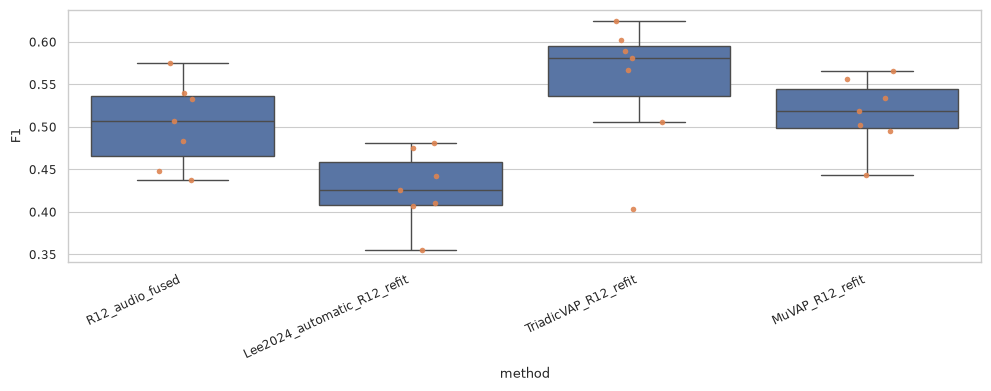

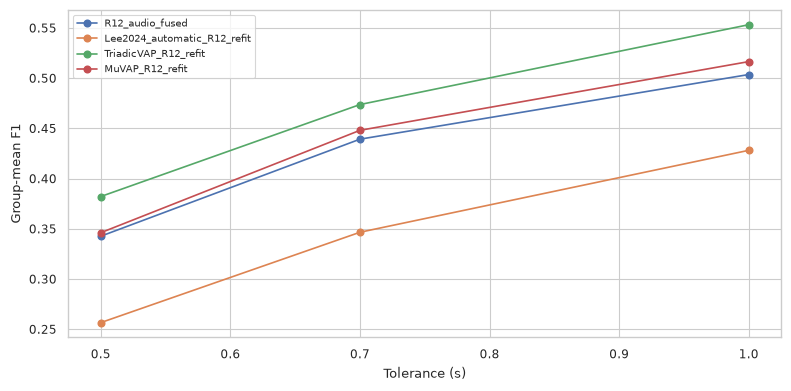

  artists = ax.bxp(**boxplot_kws)


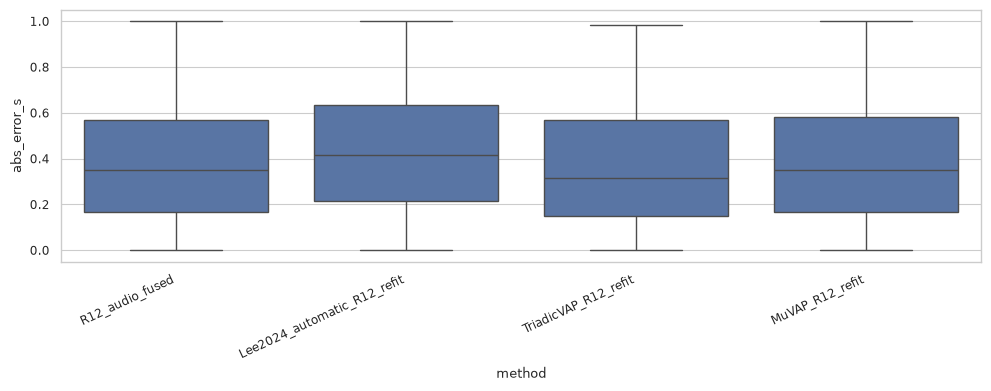

  artists = ax.bxp(**boxplot_kws)


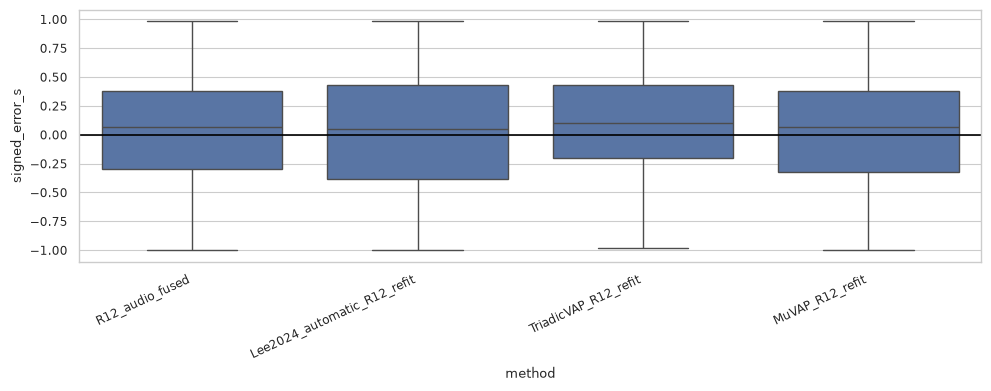

  artists = ax.bxp(**boxplot_kws)


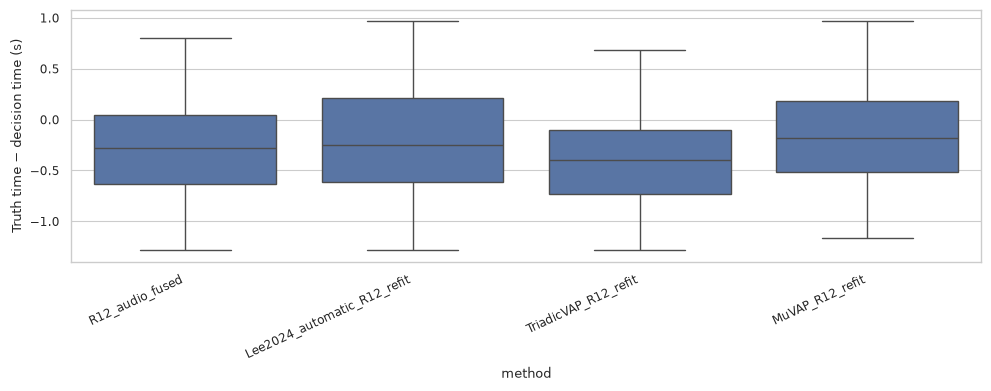

  artists = ax.bxp(**boxplot_kws)


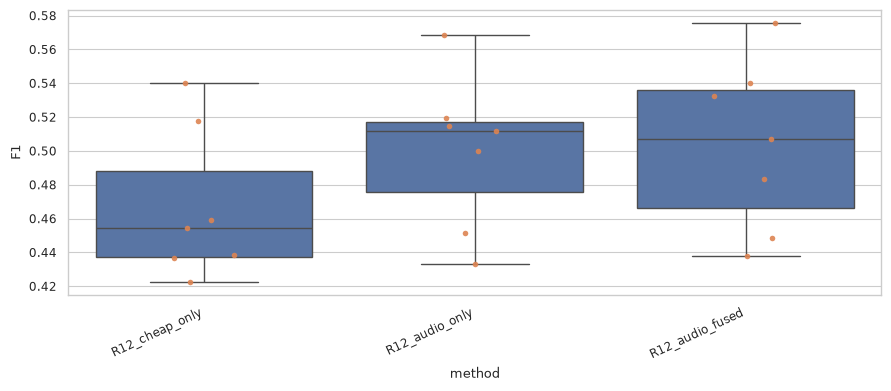

  artists = ax.bxp(**boxplot_kws)


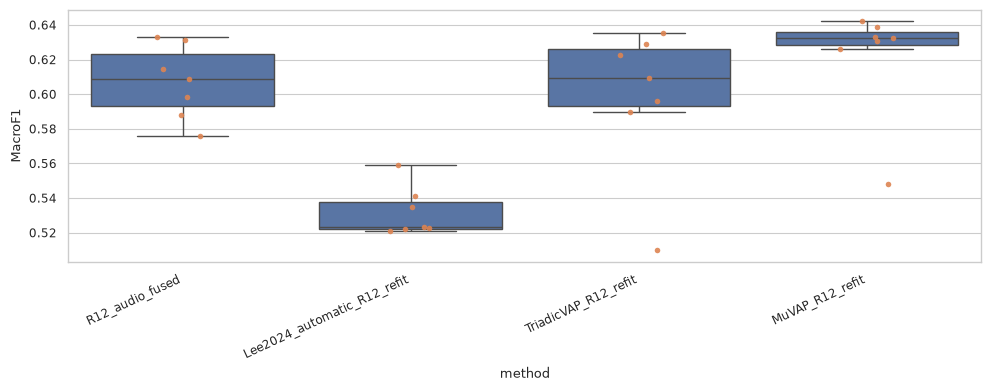

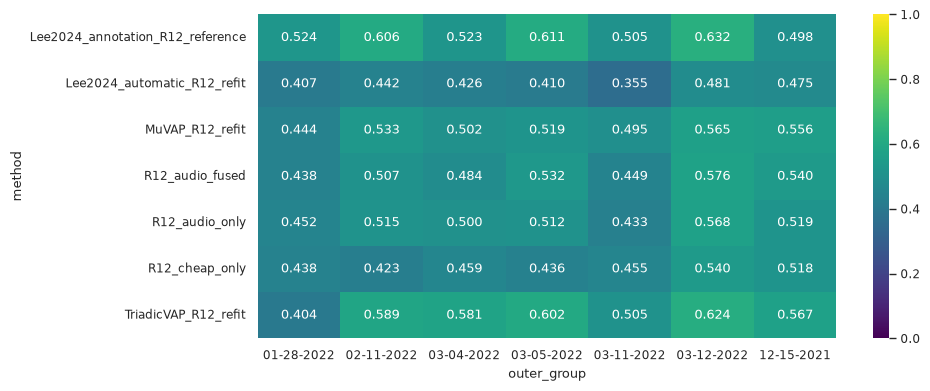

In [24]:
# Eight article figures from actual outer-fold distributions
sns.set_theme(style='whitegrid',context='paper')
FIGURE_FILES=[]
GROUP_POINT_OVERLAY=True
HEADLINE=[METHOD_PROPOSED_FULL,METHOD_LEE_AUTOMATIC,METHOD_TRIADIC_VAP,METHOD_MUVAP]
def finish_figure(name):
    plt.tight_layout()
    for ext in ('png','pdf'):
        path=FIG_ROOT/(name+'.'+ext);plt.savefig(path,dpi=300,bbox_inches='tight');FIGURE_FILES.append(str(path))
    plt.show();plt.close()
def safe_box(table,x,y,show_all_points=False):
    q=table.dropna(subset=[y]).copy() if not table.empty else table
    if q.empty:plt.text(.5,.5,'No eligible observations',ha='center',transform=plt.gca().transAxes)
    else:
        sns.boxplot(data=q,x=x,y=y,showfliers=False)
        if show_all_points:sns.stripplot(data=q,x=x,y=y,jitter=.12,size=4,alpha=.9)
    plt.xticks(rotation=25,ha='right')
primary=OUTER_FOLD_METRICS[OUTER_FOLD_METRICS.tolerance.eq(1.)]
plt.figure(figsize=(10,4));safe_box(primary[primary.method.isin(HEADLINE)],'method','F1',True);finish_figure('fig01_group_F1')
plt.figure(figsize=(8,4))
for method in HEADLINE:
    q=TASK_C_SUMMARY[TASK_C_SUMMARY.method.eq(method)].sort_values('tolerance')
    plt.plot(q.tolerance,q.F1_group_mean,marker='o',label=method)
plt.xlabel('Tolerance (s)');plt.ylabel('Group-mean F1');plt.legend(fontsize=7);finish_figure('fig02_tolerance')
match1=OUTER_MATCHES[OUTER_MATCHES.tolerance.eq(1.)&OUTER_MATCHES.method.isin(HEADLINE)]
plt.figure(figsize=(10,4));safe_box(match1,'method','abs_error_s',False);finish_figure('fig03_absolute_error')
plt.figure(figsize=(10,4));safe_box(match1,'method','signed_error_s',False);plt.axhline(0,color='black');finish_figure('fig04_signed_error')
plt.figure(figsize=(10,4));safe_box(match1,'method','lead_s',False);plt.ylabel('Truth time − decision time (s)');finish_figure('fig05_lead_time')
plt.figure(figsize=(9,4));safe_box(primary[primary.method.isin(PROPOSED_METHOD_KEYS)],'method','F1',True);finish_figure('fig06_ablation')
plt.figure(figsize=(10,4));safe_box(TASK_B_RESULTS[TASK_B_RESULTS.tolerance.eq(1.)&TASK_B_RESULTS.method.isin(HEADLINE)],'method','MacroF1',True);finish_figure('fig07_taskB')
plt.figure(figsize=(10,4));sns.heatmap(primary.pivot(index='method',columns='outer_group',values='F1'),annot=True,fmt='.3f',vmin=0,vmax=1,cmap='viridis');finish_figure('fig08_group_heatmap')

In [27]:
# Final checks and result package
audit=[]
def check(name,condition,detail=''):
    audit.append({'check':name,'status':'PASS' if bool(condition) else 'FAIL','detail':str(detail)})
check('historical_result_bytes_preserved',_sha256_file(HISTORICAL_RESULT_PATH)==HISTORICAL_EVIDENCE['result_sha256'])
if HISTORICAL_EVIDENCE['audit_sha256']:
    check('historical_audit_bytes_preserved',_sha256_file(HISTORICAL_AUDIT_PATH)==HISTORICAL_EVIDENCE['audit_sha256'])
check('seven_groups',len(GROUPS)==7)
check('all_method_group_tolerance_rows',len(OUTER_FOLD_METRICS)==7*len(ALL_METHODS)*len(EVENT_TOLERANCES))
check('exact_method_set',set(OUTER_FOLD_METRICS.method)==set(ALL_METHODS))
check('all_taskA_rows',len(TASK_A_RESULTS)==7*len(ALL_METHODS))
check('all_taskB_rows',len(TASK_B_RESULTS)==7*len(ALL_METHODS)*len(EVENT_TOLERANCES))
check('taskA_auc_pr_columns',{'MacroF1','AUROC','AUPRC'}.issubset(TASK_A_RESULTS.columns))
check('taskB_auc_pr_columns',{'MacroF1','AUROC','AUPRC'}.issubset(TASK_B_RESULTS.columns))
check('finite_taskC',np.isfinite(OUTER_FOLD_METRICS[['P','R','F1']].to_numpy()).all())
check('metric_bounds',OUTER_FOLD_METRICS[['P','R','F1']].ge(0).all().all() and OUTER_FOLD_METRICS[['P','R','F1']].le(1).all().all())
check('localization_median_reported','localization_median_abs_error_s' in OUTER_FOLD_METRICS.columns)
check('early_late_distribution',{'early_count','late_count','early_fraction','late_fraction'}.issubset(OUTER_FOLD_METRICS.columns))
check('ntt_itt_recall',{'NTT_recall','ITT_recall'}.issubset(OUTER_FOLD_METRICS.columns))
check('next_speaker_macro_f1','MacroF1' in NEXT_SPEAKER_RESULTS.columns)
check('runtime_cost_rows',len(RUNTIME_COST)==7*len(ALL_METHODS))
check('runtime_cost_nonnegative',(RUNTIME_COST[['train_selection_wall_s','outer_refit_wall_s','outer_inference_wall_s','total_outer_wall_s']].fillna(-1)>=0).all().all())
check('paired_differences_present',len(PAIRED_DIFFERENCES)==len(AUTOMATIC_COMPARATORS)*7*(2+len(EVENT_TOLERANCES)))
check('paired_wilcoxon_present',len(PAIRED_TESTS)==len(AUTOMATIC_COMPARATORS)*(2+len(EVENT_TOLERANCES)) and {'p_raw','p_holm'}.issubset(PAIRED_TESTS.columns))
check('headline_has_five_requested_rows',list(ARTICLE_SUMMARY.Method)==['Proposed (seven-group nested)','Original held-out system','Lee automatic-causal','Triadic VAP','MuVAP'])
check('r11_cv_not_fabricated',HISTORICAL_CV_STATUS['available'] or ARTICLE_SUMMARY.loc[ARTICLE_SUMMARY.Method.eq('Original held-out system'),'Evidence status'].eq('NOT_AVAILABLE_FROM_FROZEN_SINGLE_SPLIT').all())
check('group_boxplots_overlay_all_points',GROUP_POINT_OVERLAY is True)
for outer in GROUPS:
    for method in ALL_METHODS:
        p=load_outer(outer,method)
        check('verified_commit::'+outer+'::'+method,p is not None and outer not in p['train_groups'])
        check('held_only_scores::'+outer+'::'+method,set(p['scores'].session).issubset(set(sessions_for([outer]))))
check('eight_png_pdf_figures',len(FIGURE_FILES)==16 and all(Path(p).is_file() and Path(p).stat().st_size>100 for p in FIGURE_FILES))
RUNTIME_AUDIT=pd.DataFrame(audit);RUNTIME_AUDIT.to_csv(RESULT_ROOT/'runtime_audit.csv',index=False)
display(RUNTIME_AUDIT)
if not RUNTIME_AUDIT.status.eq('PASS').all():raise RuntimeError('Seven-group runtime audit failed; do not report this run as complete.')
FINAL_PACKAGE={'schema':NESTED_PROTOCOL_ID,'reporting_revision':REPORTING_REVISION,'run_fingerprint':RUN_FINGERPRINT,
               'historical_frozen_evaluation':HISTORICAL_EVIDENCE,'historical_taskC':HISTORICAL_TASKC.to_dict('records'),
               'frozen_heldout_reference': FROZEN_HELDOUT_REFERENCE.to_dict('records'),'historical_nested_cv_status': HISTORICAL_CV_STATUS,
               'new_protocol':RUN_CONTRACT,'posthoc_nested_logo':{name:table.to_dict('records') for name,table in TABLES.items() if name!='matched_events'},
               'figures':FIGURE_FILES,'audit':audit,
               'statistical_note':'Paired outer-fold Wilcoxon tests are exploratory with n=7; Holm-adjusted p-values and group-cluster bootstrap intervals are reported.',
               'reporting':'Report the original held-out evaluation separately from the post-hoc nested LOGO analysis. Do not manufacture a seven-group historical row from the single held-out TEST. Task A uses a shared proposer diagnostic; annotation-assisted Lee is secondary.'}
atomic_bytes(RESULT_ROOT/'final_result_package.json',canonical_json(FINAL_PACKAGE).encode())
print('SEVEN-GROUP RUNTIME AUDIT: PASS')
print('Results:',RESULT_ROOT)